In [1]:
!pip -q install scikit-survival lifelines captum optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 5.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 50.3 MB/s eta 0:00:00


In [2]:
import os, re, gc, json, time, math, random, hashlib, pickle, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests, zipfile
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from matplotlib.colors import LinearSegmentedColormap
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sksurv.metrics import concordance_index_ipcw, concordance_index_censored, cumulative_dynamic_auc, integrated_brier_score, brier_score
from sksurv.ensemble import RandomSurvivalForest
from lifelines import KaplanMeierFitter, CoxPHFitter
from scipy.stats import spearmanr
from google.colab import drive
warnings.filterwarnings('ignore'); pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/CKD_GraphSurv_Public')
VER = 'v3'
RAW, INT, CK, FIG, RES = [ROOT/x for x in ['raw', 'interim', f'checkpoints_{VER}', f'figures_{VER}', f'results_{VER}']]
for p in [RAW, INT, CK, FIG, RES]: p.mkdir(parents=True, exist_ok=True)

BIN_M = 3; MAX_M = 120; NB = MAX_M // BIN_M
BIN_END = BIN_M * np.arange(1, NB + 1)
HZ = [12, 24, 36]; CAL_M = 24; TAU = 36
T_POS = np.array([0., 3., 6.]); T_STEPS = 3
SEEDS = [42, 7, 2026, 11, 99]
EPOCHS, PATIENCE, BS, LR = 150, 20, 128, 1e-3
SIGMA = 0.1
N_TRIALS, HPO_SEED = 60, 42
N_BOOT = 200
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
mpl.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelweight': 'semibold',
                     'legend.frameon': False, 'grid.alpha': 0.35, 'font.family': 'DejaVu Sans'})
MODELS = ['CKD-GraphSurv', 'Temporal Transformer', 'GRU-DeepHit', 'DeepHit', 'DeepSurv', 'RSF', 'CoxPH']
PAL = dict(zip(MODELS, ['#B3172B', '#2166AC', '#1B7837', '#762A83', '#E08214', '#8C510A', '#4D4D4D']))
CPAL = {'Ajou (KR)': '#1F4E79', 'CKD-ROUTE (JP)': '#C55A11', 'Foshan (CN)': '#548235'}
COHORTS = {'test': 'Ajou internal test', 'test_sv': 'Ajou single-visit test', 'route': 'CKD-ROUTE external (renal)',
           'route_cmp': 'CKD-ROUTE composite (n=1,138)', 'foshan': 'Foshan external (3-y)'}
MAIN_C = ['test', 'test_sv', 'route', 'foshan']
GPAL = {'Kidney function': '#B3172B', 'Mineral–bone': '#E08214', 'Acid–base / electrolyte': '#2166AC',
        'Anaemia': '#762A83', 'Glomerular / nutrition': '#1B7837'}
CMAP = LinearSegmentedColormap.from_list('ckd', ['#FFFFFF', '#FDDBC7', '#D6604D', '#67001F'])

def save(fig, name):
    fig.savefig(FIG/f'{name}.png', bbox_inches='tight'); fig.savefig(FIG/f'{name}.pdf', bbox_inches='tight'); plt.show(); plt.close(fig)
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def pdump(o, p):
    with open(str(p) + '.tmp', 'wb') as f: pickle.dump(o, f)
    os.replace(str(p) + '.tmp', p)
def pload(p):
    with open(p, 'rb') as f: return pickle.load(f)
def md5(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()

print('Device:', DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
print('Drive cache:', ROOT)

Mounted at /content/drive
Device: cuda Tesla T4
Drive cache: /content/drive/MyDrive/CKD_GraphSurv_Public


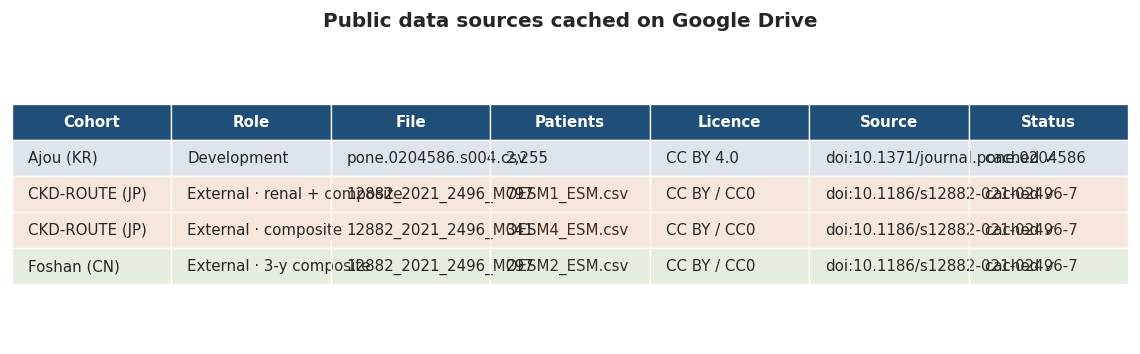

In [3]:
import zipfile, io
ZIPS = {'PMC6171856': 'https://www.ebi.ac.uk/europepmc/webservices/rest/PMC6171856/supplementaryFiles',
        'PMC8477525': 'https://www.ebi.ac.uk/europepmc/webservices/rest/PMC8477525/supplementaryFiles'}
SOURCES = {
    'ajou': dict(file='pone.0204586.s004.csv', zip='PMC6171856', fid=13186736, portal='plos', rows=2255, cols=['crf', 'obsday', 'CCR1_0mon'],
                 label='Ajou (KR)', role='Development', licence='CC BY 4.0', doi='10.1371/journal.pone.0204586'),
    'route': dict(file='12882_2021_2496_MOESM1_ESM.csv', zip='PMC8477525', fid=30902057, portal='springernature', rows=797, cols=['eGFR(last.visit)', 'CKD.progression'],
                  label='CKD-ROUTE (JP)', role='External · renal + composite', licence='CC BY / CC0', doi='10.1186/s12882-021-02496-7'),
    'route_b': dict(file='12882_2021_2496_MOESM4_ESM.csv', zip='PMC8477525', fid=None, portal='springernature', rows=341, cols=['age.number', 'CKD.progression'],
                    label='CKD-ROUTE (JP)', role='External · composite', licence='CC BY / CC0', doi='10.1186/s12882-021-02496-7'),
    'foshan': dict(file='12882_2021_2496_MOESM2_ESM.csv', zip='PMC8477525', fid=30902060, portal='springernature', rows=297, cols=['CKD.progression'],
                   label='Foshan (CN)', role='External · 3-y composite', licence='CC BY / CC0', doi='10.1186/s12882-021-02496-7')}
UA = {'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36', 'Accept': '*/*'}
def read_clean(p):
    d = pd.read_csv(p, dtype=str, keep_default_na=False); d.columns = [c.strip() for c in d.columns]
    for c in d.columns:
        x = d[c].str.strip().replace({'': np.nan, 'NA': np.nan}); n = pd.to_numeric(x, errors='coerce')
        d[c] = n if n.notna().sum() >= 0.9 * x.notna().sum() else x
    return d
def valid(p, s):
    try: d = read_clean(p); return len(d) == s['rows'] and all(c in d.columns for c in s['cols'])
    except Exception: return False
def get_zip(z):
    zp = RAW/f'{z}.zip'
    if not (zp.exists() and zipfile.is_zipfile(zp)):
        for k in range(4):
            try:
                r = requests.get(ZIPS[z], headers=UA, timeout=300)
                if r.status_code == 200 and r.content[:2] == b'PK': zp.write_bytes(r.content); break
            except Exception as e: print('  Europe PMC retry', k + 1, type(e).__name__)
            time.sleep(5 * (k + 1))
    return zipfile.ZipFile(zp) if zp.exists() and zipfile.is_zipfile(zp) else None
def fetch(key):
    s = SOURCES[key]; p = RAW/s['file']
    if p.exists() and valid(p, s): return 'cached'
    zf = get_zip(s['zip'])
    if zf is not None and s['file'] in zf.namelist():
        p.write_bytes(zf.read(s['file']))
        if valid(p, s): return 'Europe PMC'
    if s['fid']:
        for u in [f"https://ndownloader.figshare.com/files/{s['fid']}", f"https://{s['portal']}.figshare.com/ndownloader/files/{s['fid']}"]:
            try:
                r = requests.get(u, headers=UA, timeout=120)
                if r.status_code == 200: p.write_bytes(r.content)
                if valid(p, s): return 'figshare'
            except Exception: pass
    raise RuntimeError(f"Could not fetch {s['file']}. Download {ZIPS[s['zip']]} in a browser, unzip it and copy {s['file']} to {RAW}.")
STATUS = {k: fetch(k) for k in SOURCES}
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis('off')
cells = [[SOURCES[k]['label'], SOURCES[k]['role'], SOURCES[k]['file'], f"{SOURCES[k]['rows']:,}", SOURCES[k]['licence'], 'doi:' + SOURCES[k]['doi'], STATUS[k] + ' ✓'] for k in SOURCES]
tb = ax.table(cellText=cells, colLabels=['Cohort', 'Role', 'File', 'Patients', 'Licence', 'Source', 'Status'], loc='center', cellLoc='left')
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.8)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor('white')
    if r == 0: cell.set_facecolor('#1F4E79'); cell.set_text_props(color='white', weight='bold')
    else: cell.set_facecolor(mpl.colors.to_rgba(CPAL[cells[r-1][0]], 0.15))
ax.set_title('Public data sources cached on Google Drive', pad=12); save(fig, 'S02_sources')

{'ajou': (2255, 708), 'route': (797, 185), 'route_cmp': (1138, 280), 'foshan': (297, 108)}


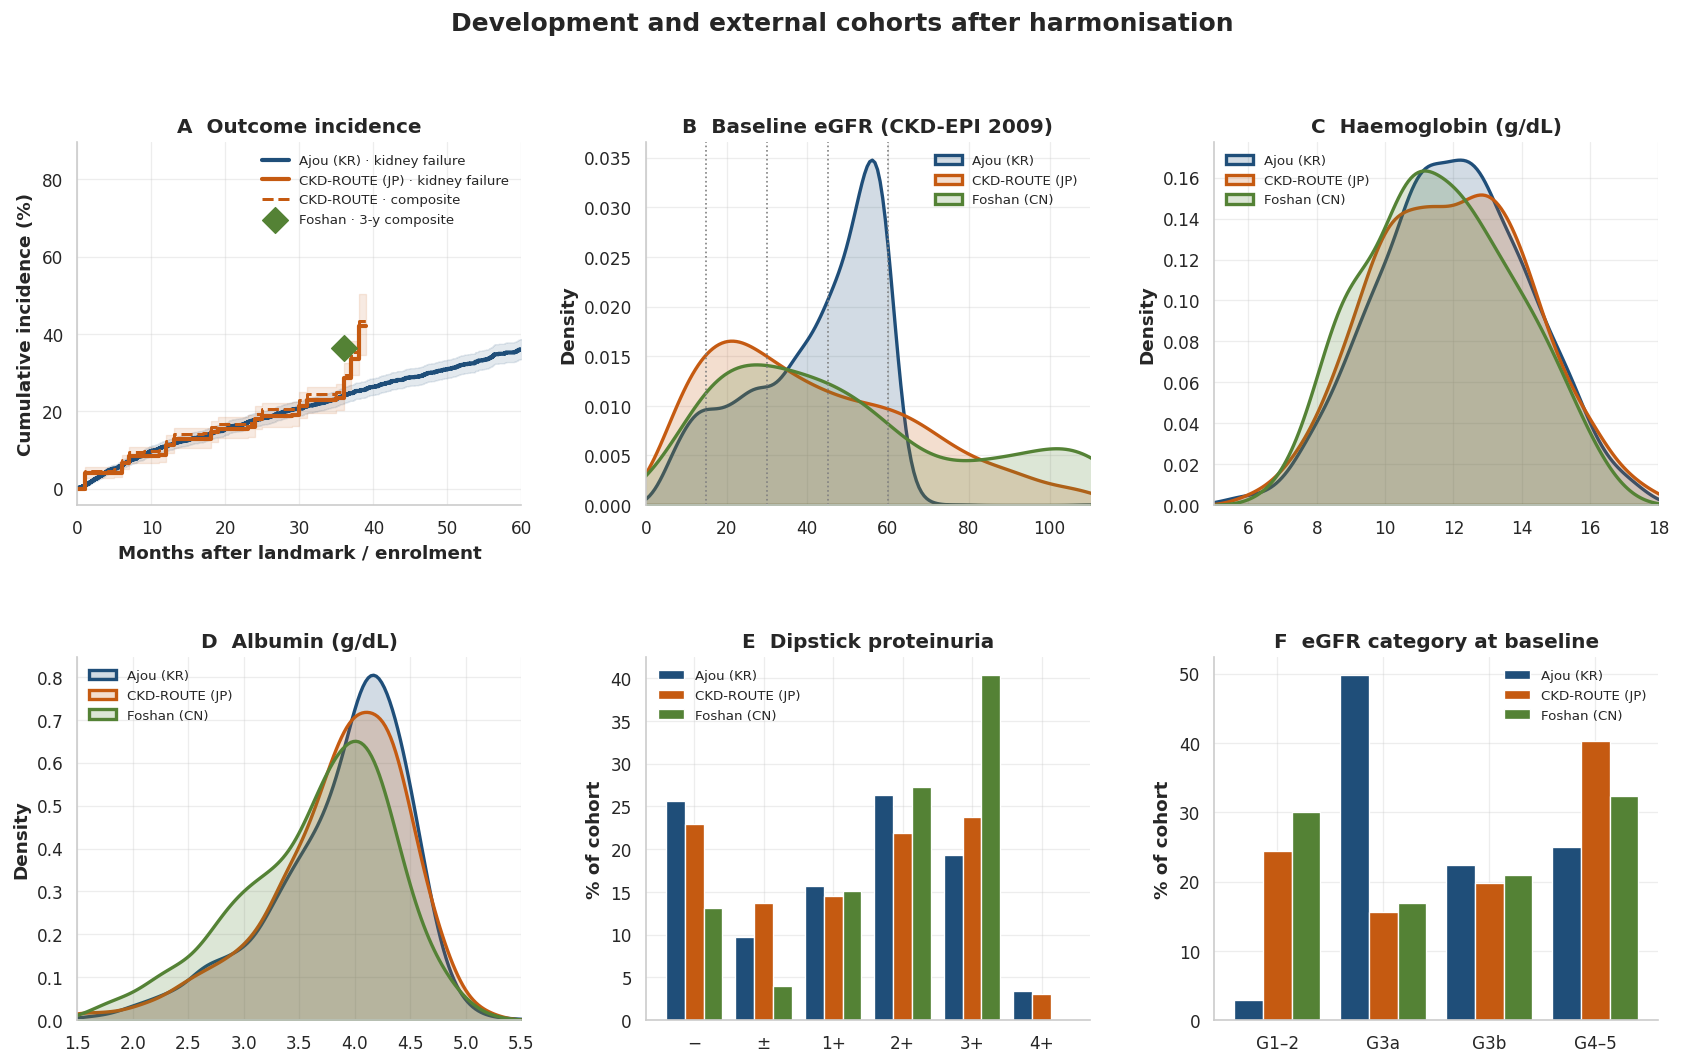

In [4]:
LABS = ['egfr', 'creatinine', 'bun', 'hemoglobin', 'albumin', 'bicarbonate', 'calcium', 'phosphorus', 'potassium', 'proteinuria']
FI = {f: i for i, f in enumerate(LABS)}; F = len(LABS)
EXT_LABS = ['egfr', 'creatinine', 'hemoglobin', 'albumin', 'proteinuria']
DROP_LABS = [FI[f] for f in LABS if f not in EXT_LABS]
FLABEL = dict(zip(LABS, ['eGFR', 'Creatinine', 'BUN', 'Haemoglobin', 'Albumin', 'Bicarbonate', 'Calcium', 'Phosphorus', 'Potassium', 'Proteinuria']))
FGROUP = {'egfr': 'Kidney function', 'creatinine': 'Kidney function', 'bun': 'Kidney function', 'calcium': 'Mineral–bone',
          'phosphorus': 'Mineral–bone', 'bicarbonate': 'Acid–base / electrolyte', 'potassium': 'Acid–base / electrolyte',
          'hemoglobin': 'Anaemia', 'albumin': 'Glomerular / nutrition', 'proteinuria': 'Glomerular / nutrition'}
STATIC = ['age', 'female', 'dm', 'htn', 'gn']
SLABEL = dict(zip(STATIC, ['Age', 'Female sex', 'Diabetes', 'Hypertension', 'Glomerulonephritis']))
AJ = {'egfr': 'CCR1', 'creatinine': 'bcreatinine', 'bun': 'BUN', 'hemoglobin': 'bhemoglobin', 'albumin': 'balbumin',
      'bicarbonate': 'biocarbonate', 'calcium': 'calcium', 'phosphorus': 'phosphorus', 'potassium': 'potassium'}
PROT = {'Neg': -1, 'Trace': 0, '1+': 1, '2+': 2, '3+': 3, '4+': 4}

def epi2009(cr, age, female):
    cr, age, fe = np.asarray(cr, float), np.asarray(age, float), np.asarray(female) == 1
    k, a = np.where(fe, 0.7, 0.9), np.where(fe, -0.329, -0.411)
    return 141 * np.minimum(cr / k, 1) ** a * np.maximum(cr / k, 1) ** -1.209 * 0.993 ** age * np.where(fe, 1.018, 1.)
def jsn_to_cr(egfr_jp, age, female):
    return (np.asarray(egfr_jp, float) / (194 * np.asarray(age, float) ** -0.287 * np.where(np.asarray(female) == 1, 0.739, 1.))) ** (-1 / 1.094)

if not (INT/'cohorts.pkl').exists():
    a = read_clean(RAW/SOURCES['ajou']['file'])
    N = len(a); V = np.full((N, T_STEPS, F), np.nan, np.float32); TR = np.full((N, F), np.nan, np.float32); VR = TR.copy()
    for f, c in AJ.items():
        V[:, 0, FI[f]], V[:, 1, FI[f]], V[:, 2, FI[f]] = a[f'{c}_0mon'], a[f'{c}_ajmean'], a[f'{c}_6mon']
        TR[:, FI[f]] = a[f'{c}_seaslope']; VR[:, FI[f]] = np.log(a[f'{c}_slope'].clip(lower=1))
    V[:, 0, FI['proteinuria']] = a.protein_0mon.map(PROT); V[:, 2, FI['proteinuria']] = a.protein_6mon.map(PROT)
    sa = pd.DataFrame({'age': a.age, 'female': (a.sex == 1).astype(int), 'dm': a.dm, 'htn': a.htn, 'gn': a.gn})
    aj = dict(V=V, TR=TR, VR=VR, S=sa.values.astype(np.float32), Th=np.clip((a.obsday.values - 182) / 30.4375, 0.1, None).astype(np.float32),
              E=a.crf.values.astype(np.int64), meta=sa.assign(base_egfr=V[:, 0, FI['egfr']], prot=V[:, 0, FI['proteinuria']], cohort='Ajou (KR)'))
    def norm(df):
        df = df.copy()
        if 'age.number' in df: df['age'] = df.pop('age.number')
        return df.rename(columns={'etiology of CKD': 'etiology.of.CKD'})
    def ext(df, label):
        df = norm(df).reset_index(drop=True); n = len(df)
        df.loc[(df.Hb < 5) | (df.Hb > 20), 'Hb'] = np.nan; df.loc[(df.Alb < 1) | (df.Alb > 6), 'Alb'] = np.nan; df.loc[df.eGFR <= 0, 'eGFR'] = np.nan
        fe = (df.gender == 2).astype(int).values; cr = jsn_to_cr(df.eGFR, df.age, fe); V = np.full((n, T_STEPS, F), np.nan, np.float32)
        V[:, 0, FI['creatinine']] = cr; V[:, 0, FI['egfr']] = epi2009(cr, df.age, fe)
        V[:, 0, FI['hemoglobin']] = df.Hb; V[:, 0, FI['albumin']] = df.Alb; V[:, 0, FI['proteinuria']] = df['dipstick.proteinuria'].clip(-1, 4)
        s = pd.DataFrame({'age': df.age, 'female': fe, 'dm': df.diabetes, 'htn': df.hypertension, 'gn': (df['etiology.of.CKD'] == 3).astype(int)}).fillna(0)
        return dict(V=V, TR=np.full((n, F), np.nan, np.float32), VR=np.full((n, F), np.nan, np.float32), S=s.values.astype(np.float32),
                    Th=np.clip(df['observational.duration'].values, 0.5, None).astype(np.float32), E=df['CKD.progression'].fillna(0).values.astype(np.int64),
                    meta=s.assign(base_egfr=V[:, 0, FI['egfr']], prot=V[:, 0, FI['proteinuria']], cohort=label).reset_index(drop=True))
    r1 = read_clean(RAW/SOURCES['route']['file']); r2 = read_clean(RAW/SOURCES['route_b']['file'])
    ro = ext(r1, 'CKD-ROUTE (JP)'); last, base = r1['eGFR(last.visit)'].values, r1.eGFR.values
    ro['E'] = ((ro['E'] == 1) & ((last <= 0.5 * base) | (last < 15))).astype(np.int64)
    rc = ext(pd.concat([norm(r1).drop(columns=['eGFR(last.visit)', 'proteinuria']), norm(r2)], ignore_index=True), 'CKD-ROUTE (JP)')
    fo = ext(read_clean(RAW/SOURCES['foshan']['file']), 'Foshan (CN)'); fo['Th'] = np.full(len(fo['E']), 36., np.float32)
    pdump({'ajou': aj, 'route': ro, 'route_cmp': rc, 'foshan': fo}, INT/'cohorts.pkl')
CO = pload(INT/'cohorts.pkl'); AJD, ROD, RCD, FOD = CO['ajou'], CO['route'], CO['route_cmp'], CO['foshan']
print({k: (len(v['E']), int(v['E'].sum())) for k, v in CO.items()})

fig = plt.figure(figsize=(17, 9.5)); gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.28)
ax = fig.add_subplot(gs[0, 0])
for d, lb, ls in [(AJD, 'Ajou (KR)', '-'), (ROD, 'CKD-ROUTE (JP)', '-')]:
    km = KaplanMeierFitter().fit(d['Th'], d['E']); x = km.cumulative_density_.index.values; y = km.cumulative_density_.values[:, 0] * 100
    ax.step(x, y, where='post', color=CPAL[lb], lw=2.5, label=f'{lb} · kidney failure')
    ax.fill_between(x, km.confidence_interval_cumulative_density_.values[:, 0] * 100, km.confidence_interval_cumulative_density_.values[:, 1] * 100, step='post', color=CPAL[lb], alpha=0.12)
km = KaplanMeierFitter().fit(RCD['Th'], RCD['E']); ax.step(km.cumulative_density_.index, km.cumulative_density_.values[:, 0] * 100, where='post', color=CPAL['CKD-ROUTE (JP)'], ls='--', lw=1.8, label='CKD-ROUTE · composite')
ax.scatter([36], [FOD['E'].mean() * 100], s=120, marker='D', color=CPAL['Foshan (CN)'], zorder=5, label='Foshan · 3-y composite')
ax.set_xlim(0, 60); ax.set_xlabel('Months after landmark / enrolment'); ax.set_ylabel('Cumulative incidence (%)'); ax.set_title('A  Outcome incidence'); ax.legend(fontsize=8)
for j, (f, ttl, rng_) in enumerate([('egfr', 'B  Baseline eGFR (CKD-EPI 2009)', (0, 110)), ('hemoglobin', 'C  Haemoglobin (g/dL)', (5, 18)), ('albumin', 'D  Albumin (g/dL)', (1.5, 5.5))]):
    ax = fig.add_subplot(gs[0, 1] if j == 0 else gs[0, 2] if j == 1 else gs[1, 0])
    for d, lb in [(AJD, 'Ajou (KR)'), (RCD, 'CKD-ROUTE (JP)'), (FOD, 'Foshan (CN)')]:
        x = d['V'][:, 0, FI[f]]; x = x[~np.isnan(x)]; sns.kdeplot(np.clip(x, *rng_), ax=ax, color=CPAL[lb], fill=True, alpha=0.2, lw=2, label=lb)
    if f == 'egfr':
        for v in [15, 30, 45, 60]: ax.axvline(v, color='grey', ls=':', lw=1)
    ax.set_xlim(*rng_); ax.set_title(ttl); ax.set_xlabel(''); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 1]); cats = [-1, 0, 1, 2, 3, 4]; w = 0.27
for k, (d, lb) in enumerate([(AJD, 'Ajou (KR)'), (RCD, 'CKD-ROUTE (JP)'), (FOD, 'Foshan (CN)')]):
    p = pd.Series(d['V'][:, 0, FI['proteinuria']]).value_counts(normalize=True).reindex(cats).fillna(0) * 100
    ax.bar(np.arange(6) + (k - 1) * w, p.values, w, color=CPAL[lb], label=lb, edgecolor='white')
ax.set_xticks(range(6)); ax.set_xticklabels(['−', '±', '1+', '2+', '3+', '4+']); ax.set_ylabel('% of cohort'); ax.set_title('E  Dipstick proteinuria'); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 2]); st = lambda e: pd.Series(pd.cut(e, [-1, 30, 45, 60, 200], labels=['G4–5', 'G3b', 'G3a', 'G1–2']))
for k, (d, lb) in enumerate([(AJD, 'Ajou (KR)'), (RCD, 'CKD-ROUTE (JP)'), (FOD, 'Foshan (CN)')]):
    p = st(d['V'][:, 0, FI['egfr']]).value_counts(normalize=True).reindex(['G1–2', 'G3a', 'G3b', 'G4–5']) * 100
    ax.bar(np.arange(4) + (k - 1) * w, p.values, w, color=CPAL[lb], label=lb, edgecolor='white')
ax.set_xticks(range(4)); ax.set_xticklabels(['G1–2', 'G3a', 'G3b', 'G4–5']); ax.set_ylabel('% of cohort'); ax.set_title('F  eGFR category at baseline'); ax.legend(fontsize=8)
fig.suptitle('Development and external cohorts after harmonisation', fontsize=15, fontweight='bold', y=0.995); save(fig, 'S03_cohorts')

Characteristic,Ajou (development),CKD-ROUTE (external),Foshan (external),SMD vs ROUTE,SMD vs Foshan
"Patients, n","2,255","1,138",297,,
"Age, years",60.0 [47.0–68.0],70.0 [61.0–77.0],53.0 [39.0–64.0],0.74,0.35
Female sex,997 (44.2%),346 (30.4%),139 (46.8%),0.29,0.05
Diabetes,833 (36.9%),422 (37.1%),70 (23.6%),0.00,0.29
Hypertension,839 (37.2%),"1,027 (90.2%)",178 (59.9%),1.32,0.47
Glomerulonephritis,385 (17.1%),216 (19.0%),177 (59.6%),0.05,0.97
eGFR,46.2 [30.1–55.0],36.9 [20.7–59.5],42.1 [23.8–66.4],0.01,0.32
Creatinine,1.5 [1.3–2.1],1.7 [1.2–2.7],1.6 [1.1–2.6],0.14,0.03
Haemoglobin,12.0 [10.5–13.6],12.0 [10.2–13.6],11.5 [10.1–13.2],0.01,0.16
Albumin,4.0 [3.5–4.3],4.0 [3.5–4.3],3.8 [3.2–4.1],0.03,0.34


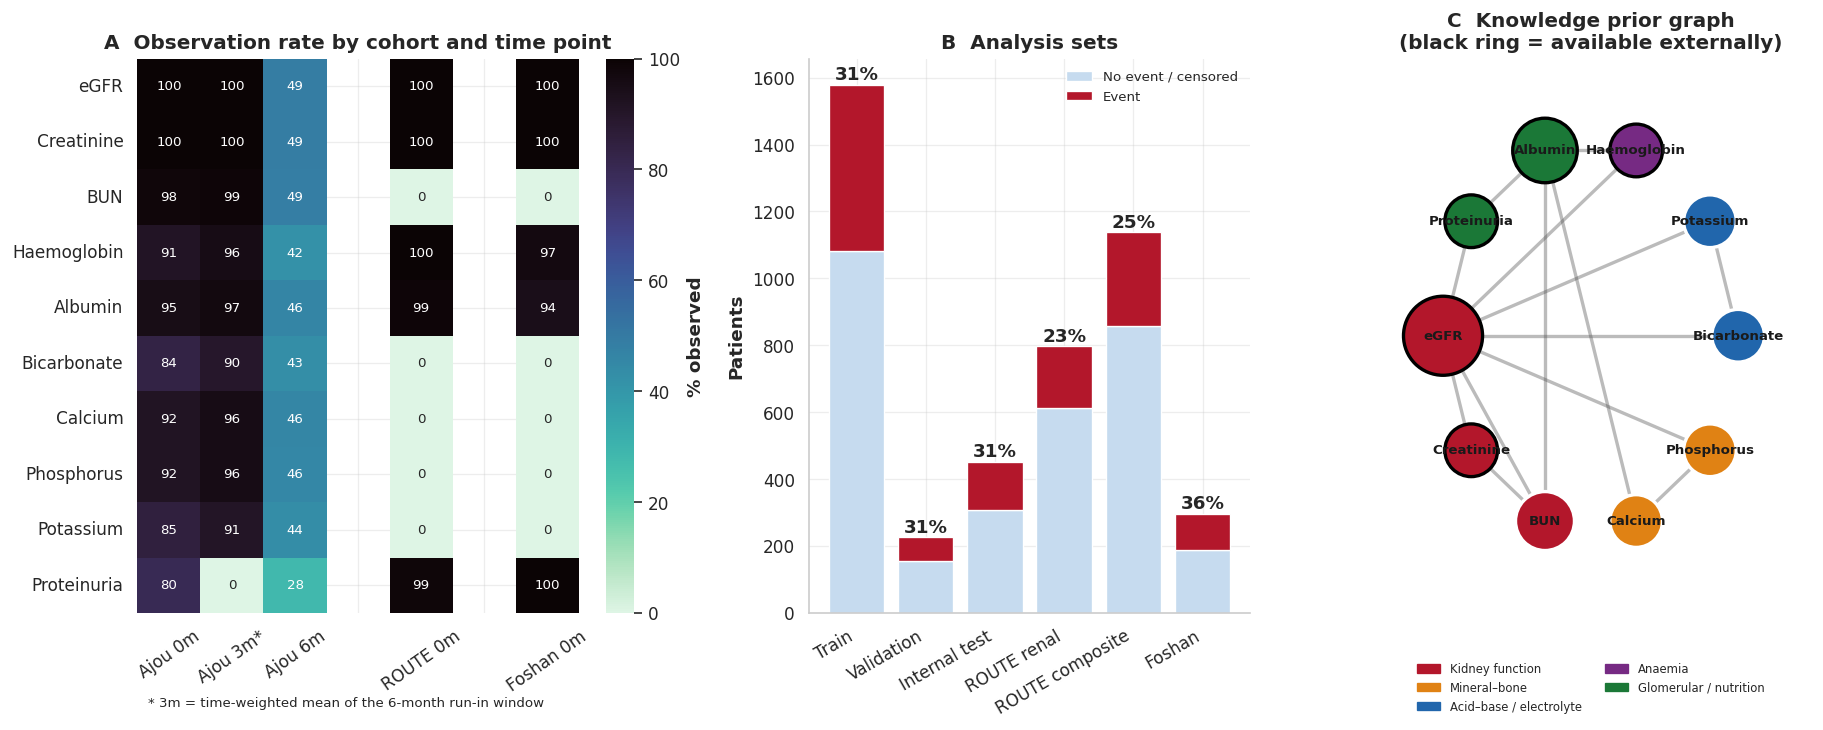

In [5]:
LOGF = [FI['creatinine'], FI['bun']]
EDGES = [('egfr', 'creatinine'), ('egfr', 'bun'), ('creatinine', 'bun'), ('calcium', 'phosphorus'), ('egfr', 'phosphorus'),
         ('bicarbonate', 'potassium'), ('egfr', 'bicarbonate'), ('egfr', 'potassium'), ('egfr', 'hemoglobin'), ('albumin', 'proteinuria'),
         ('egfr', 'proteinuria'), ('albumin', 'calcium'), ('bun', 'albumin'), ('hemoglobin', 'albumin')]
PRIOR_NP = np.eye(F, dtype=np.float32)
for u, v in EDGES: PRIOR_NP[FI[u], FI[v]] = PRIOR_NP[FI[v], FI[u]] = 1.
def tlog(V):
    V = V.copy(); V[..., LOGF] = np.log1p(np.clip(V[..., LOGF], 0, None)); return V
def rscale(x, ax=0):
    med = np.nanmedian(x, ax); iqr = np.nanpercentile(x, 75, ax) - np.nanpercentile(x, 25, ax); sd = np.nanstd(x, ax)
    return med, np.where(iqr > 1e-6, iqr, np.where(sd > 1e-9, sd, 1.))
def single_visit(X):
    X = X.copy(); X[:, 1:] = 0; X[..., 2:] = 0; X[:, :, DROP_LABS] = 0; return X
def flat(X, S):
    return np.concatenate([X.reshape(len(X), -1), S], 1).astype(np.float32)
if not (INT/'splits.pkl').exists():
    idx = np.arange(len(AJD['E']))
    tr, te = train_test_split(idx, test_size=0.2, stratify=AJD['E'], random_state=42)
    tr, va = train_test_split(tr, test_size=0.125, stratify=AJD['E'][tr], random_state=42)
    Vt = tlog(AJD['V'][tr]).reshape(-1, F); vmed, viqr = rscale(Vt)
    tmed, tiqr = rscale(AJD['TR'][tr]); wmed, wiqr = rscale(AJD['VR'][tr])
    amu, asd = AJD['S'][tr, 0].mean(), AJD['S'][tr, 0].std()
    def pack(d, ix, E=None):
        V = tlog(d['V'][ix]); M = ~np.isnan(V)
        Z = np.nan_to_num(np.clip((V - vmed) / viqr, -6, 6), nan=0.)
        Tz = np.nan_to_num(np.clip((d['TR'][ix] - tmed) / tiqr, -6, 6), nan=0.); Wz = np.nan_to_num(np.clip((d['VR'][ix] - wmed) / wiqr, -6, 6), nan=0.)
        X = np.stack([Z, M.astype(np.float32), np.repeat(Tz[:, None], T_STEPS, 1), np.repeat(Wz[:, None], T_STEPS, 1)], -1).astype(np.float32)
        S = d['S'][ix].copy(); S[:, 0] = (S[:, 0] - amu) / asd
        E_ = d['E'][ix] if E is None else E[ix]; Th = d['Th'][ix]
        return {'X': X, 'S': S.astype(np.float32), 'Th': Th.astype(np.float32), 'E': E_.astype(np.int64),
                'Tb': np.clip(np.ceil(Th / BIN_M).astype(int) - 1, 0, NB - 1), 'Vraw': d['V'][ix], 'meta': d['meta'].iloc[ix].reset_index(drop=True)}
    SP = {'train': pack(AJD, tr), 'val': pack(AJD, va), 'test': pack(AJD, te)}
    for k in ['val', 'test']:
        s = dict(SP[k]); s['X'] = single_visit(s['X']); s['Vraw'] = s['Vraw'].copy(); s['Vraw'][:, 1:] = np.nan; s['Vraw'][:, :, DROP_LABS] = np.nan; SP[k + '_sv'] = s
    SP['route'] = pack(ROD, np.arange(len(ROD['E']))); SP['route_cmp'] = pack(RCD, np.arange(len(RCD['E']))); SP['foshan'] = pack(FOD, np.arange(len(FOD['E'])))
    SP['age_norm'] = (amu, asd); pdump(SP, INT/'splits.pkl')
SP = pload(INT/'splits.pkl')
C_IN = SP['train']['X'].shape[-1]; S_DIM = SP['train']['S'].shape[1]; A_DIM = T_STEPS * F * C_IN + S_DIM
AUG = {}
for k in ['train']:
    Xa = single_visit(SP[k]['X']); AUG = {'A': np.concatenate([flat(SP[k]['X'], SP[k]['S']), flat(Xa, SP[k]['S'])]),
                                          'Th': np.r_[SP[k]['Th'], SP[k]['Th']], 'E': np.r_[SP[k]['E'], SP[k]['E']]}
A_NAMES = [f'{FLABEL[f]}@{t}m·{c}' for t in ['0', '3', '6'] for f in LABS for c in ['z', 'obs', 'trend', 'var']] + [SLABEL[s] for s in STATIC]

def smd(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna(); d = np.sqrt((a.var() + b.var()) / 2); return abs(a.mean() - b.mean()) / d if d > 0 else 0.
def fmt(x, binary=False):
    x = pd.Series(x).dropna()
    return f'{int(x.sum()):,} ({100*x.mean():.1f}%)' if binary else f'{x.median():.1f} [{x.quantile(.25):.1f}–{x.quantile(.75):.1f}]'
rows = [('Patients, n', f"{len(AJD['E']):,}", f"{len(RCD['E']):,}", f"{len(FOD['E']):,}", '', '')]
for k, lb, b in [('age', 'Age, years', False), ('female', 'Female sex', True), ('dm', 'Diabetes', True), ('htn', 'Hypertension', True), ('gn', 'Glomerulonephritis', True)]:
    a_, r_, f_ = AJD['meta'][k], RCD['meta'][k], FOD['meta'][k]; rows.append((lb, fmt(a_, b), fmt(r_, b), fmt(f_, b), f'{smd(a_, r_):.2f}', f'{smd(a_, f_):.2f}'))
for f in ['egfr', 'creatinine', 'hemoglobin', 'albumin', 'proteinuria']:
    a_, r_, f_ = AJD['V'][:, 0, FI[f]], RCD['V'][:, 0, FI[f]], FOD['V'][:, 0, FI[f]]
    rows.append((FLABEL[f] + (' (dipstick, −1 to 4)' if f == 'proteinuria' else ''), fmt(a_), fmt(r_), fmt(f_), f'{smd(a_, r_):.2f}', f'{smd(a_, f_):.2f}'))
rows += [('RRT (Ajou) / kidney failure or ≥50% eGFR loss (ROUTE, n=797)', fmt(AJD['E'], True), fmt(ROD['E'], True), '–', '', ''),
         ('Composite outcome incl. CVD and death', '–', fmt(RCD['E'], True), fmt(FOD['E'], True), '', ''),
         ('Follow-up, months', fmt(AJD['Th']), fmt(RCD['Th']), '36 (fixed)', '', '')]
TABLE1 = pd.DataFrame(rows, columns=['Characteristic', 'Ajou (development)', 'CKD-ROUTE (external)', 'Foshan (external)', 'SMD vs ROUTE', 'SMD vs Foshan'])
TABLE1.to_csv(RES/'table1_baseline.csv', index=False); TABLE1.to_latex(RES/'table1_baseline.tex', index=False)
display(TABLE1.style.hide(axis='index').set_table_styles([{'selector': 'th', 'props': [('background', '#1F4E79'), ('color', 'white')]}]))

fig = plt.figure(figsize=(18, 6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1], wspace=0.25)
ax = fig.add_subplot(gs[0]); obs = np.stack([SP[k]['X'][..., 1].mean(0) for k in ['train', 'route_cmp', 'foshan']], 0)
hm = np.concatenate([obs[0].T, np.full((F, 1), np.nan), obs[1][:1].T, np.full((F, 1), np.nan), obs[2][:1].T], 1) * 100
sns.heatmap(hm, ax=ax, cmap='mako_r', vmin=0, vmax=100, annot=True, fmt='.0f', annot_kws={'fontsize': 8}, cbar_kws={'label': '% observed'},
            yticklabels=[FLABEL[f] for f in LABS], xticklabels=['Ajou 0m', 'Ajou 3m*', 'Ajou 6m', '', 'ROUTE 0m', '', 'Foshan 0m'], mask=np.isnan(hm))
ax.set_title('A  Observation rate by cohort and time point'); ax.tick_params(axis='x', rotation=35)
ax = fig.add_subplot(gs[1]); names = ['train', 'val', 'test', 'route', 'route_cmp', 'foshan']; lbl = ['Train', 'Validation', 'Internal test', 'ROUTE renal', 'ROUTE composite', 'Foshan']
n1 = [int(SP[s]['E'].sum()) for s in names]; n0 = [len(SP[s]['E']) - e for s, e in zip(names, n1)]
ax.bar(lbl, n0, color='#C6DBEF', edgecolor='white', label='No event / censored'); ax.bar(lbl, n1, bottom=n0, color='#B3172B', edgecolor='white', label='Event')
for i, s in enumerate(names): ax.text(i, n0[i] + n1[i] + 15, f'{n1[i]/(n0[i]+n1[i])*100:.0f}%', ha='center', fontweight='bold')
ax.set_title('B  Analysis sets'); ax.set_ylabel('Patients'); ax.legend(fontsize=8); plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
ax = fig.add_subplot(gs[2]); G = nx.Graph(); G.add_nodes_from(LABS); G.add_edges_from(EDGES); pos = nx.circular_layout(sorted(LABS, key=lambda n: FGROUP[n]))
nx.draw_networkx_edges(G, pos, ax=ax, width=2, alpha=0.4, edge_color='#555555')
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[GPAL[FGROUP[n]] for n in G.nodes], node_size=[500 + 250 * G.degree(n) for n in G.nodes],
                       edgecolors=['black' if n in EXT_LABS else 'white' for n in G.nodes], linewidths=2)
nx.draw_networkx_labels(G, pos, ax=ax, labels={n: FLABEL[n] for n in G.nodes}, font_size=8, font_weight='bold')
ax.legend(handles=[mpl.patches.Patch(color=c, label=g) for g, c in GPAL.items()], loc='lower center', fontsize=7, ncol=2, bbox_to_anchor=(0.5, -0.2))
ax.set_title('C  Knowledge prior graph\n(black ring = available externally)'); ax.margins(0.18); ax.axis('off')
fig.text(0.13, -0.02, '* 3m = time-weighted mean of the 6-month run-in window', fontsize=8); save(fig, 'S04_design')

In [6]:
PRIOR = torch.tensor(PRIOR_NP)
DEFAULT_CFG = dict(graph=True, prior=True, temporal=True, use_md=True, aug=True, gate=True, wide=True, ph=True)
BASE_CFG = dict(rank=True, aug=True)
DROP_T = torch.tensor(DROP_LABS)

def tpos(d):
    pe = torch.zeros(T_STEPS, d); pos = torch.tensor(T_POS).float().unsqueeze(1); div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(100.) / d))
    pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div); return pe

class GraphAttn(nn.Module):
    def __init__(s, d, h, A, drop, use_prior=True):
        super().__init__(); s.h, s.dk, s.use_prior, s.keep, s.last = h, d // h, use_prior, False, None
        s.qkv, s.o = nn.Linear(d, 3 * d), nn.Linear(d, d); s.edge = nn.Parameter(torch.zeros(h, F, F)); s.beta = nn.Parameter(torch.ones(h))
        s.register_buffer('A', A.clone()); s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d); s.drop = nn.Dropout(drop)
        s.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d))
    def forward(s, x):
        N, n, d = x.shape; q, k, v = s.qkv(s.ln1(x)).view(N, n, 3, s.h, s.dk).permute(2, 0, 3, 1, 4)
        att = q @ k.transpose(-1, -2) / math.sqrt(s.dk) + s.edge
        if s.use_prior: att = att + s.beta.view(1, -1, 1, 1) * s.A
        a = att.softmax(-1)
        if s.keep: s.last = a.detach()
        x = x + s.drop(s.o((s.drop(a) @ v).transpose(1, 2).reshape(N, n, d))); return x + s.drop(s.ff(s.ln2(x)))

class TBlock(nn.Module):
    def __init__(s, d, h, drop):
        super().__init__(); s.att = nn.MultiheadAttention(d, h, dropout=drop, batch_first=True); s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.drop = nn.Dropout(drop); s.keep, s.last = False, None; s.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d))
    def forward(s, x, kpm=None):
        y = s.ln1(x); y, w = s.att(y, y, y, key_padding_mask=kpm, need_weights=s.keep, average_attn_weights=False)
        if s.keep: s.last = w.detach()
        x = x + s.drop(y); return x + s.drop(s.ff(s.ln2(x)))

def hazard_head(d):
    l = nn.Linear(d, NB)
    with torch.no_grad(): l.bias.fill_(-3.5)
    return l
def step_mask(X): return X[..., 1].sum(-1) > 0

class PHHead(nn.Module):
    def __init__(s, d, rank=4):
        super().__init__(); s.base = nn.Parameter(torch.full((NB,), -3.5)); s.eta = nn.Linear(d, 1); s.tv = nn.Linear(d, rank); s.tb = nn.Parameter(torch.zeros(rank, NB))
    def forward(s, z): return s.base + s.eta(z) + 0.1 * (s.tv(z) @ s.tb)

class CKDGraphSurv(nn.Module):
    def __init__(s, cfg=None, d=32, h=4, hid=64, drop=0.2, nl=2, rank=4):
        super().__init__(); s.cfg = {**DEFAULT_CFG, **(cfg or {})}; c = s.cfg; s.keep = False
        cin = C_IN if c['use_md'] else 2; s.cin = cin
        s.inp = nn.Linear(F * cin + S_DIM, hid)
        if c['graph']:
            s.val = nn.Linear(cin, d); s.fid = nn.Embedding(F, d); s.gl = nn.ModuleList([GraphAttn(d, h, PRIOR, drop, c['prior']) for _ in range(nl)])
            s.npool = nn.Linear(d, 1); s.gproj = nn.Linear(d, hid); s.gate = nn.Linear(2 * hid, hid) if c['gate'] else None
        if c['temporal']: s.gru = nn.GRU(hid, hid, 2, batch_first=True, dropout=drop)
        else: s.step = nn.Sequential(nn.Linear(hid, hid), nn.GELU())
        s.att = nn.Linear(hid, 1)
        s.out = nn.Sequential(nn.Linear(2 * hid, hid), nn.BatchNorm1d(hid), nn.GELU(), nn.Dropout(drop), nn.Linear(hid, hid // 2), nn.GELU())
        s.ph = PHHead(hid // 2, rank) if c['ph'] else hazard_head(hid // 2)
        s.wide = nn.Linear(T_STEPS * F * cin + S_DIM, 1) if c['wide'] else None
        if s.wide is not None: nn.init.zeros_(s.wide.weight); nn.init.zeros_(s.wide.bias)
        s.rec = nn.Linear(hid // 2, F) if c['aug'] else None
    def set_keep(s, flag):
        s.keep = flag
        for m in s.modules():
            if isinstance(m, GraphAttn): m.keep = flag
    def forward(s, b):
        X, S = b['X'][..., :s.cin], b['S']; B = X.shape[0]; c = s.cfg; sm = step_mask(b['X']); L = sm.sum(1).clamp(min=1)
        u = s.inp(torch.cat([X.reshape(B, T_STEPS, -1), S.unsqueeze(1).expand(B, T_STEPS, -1)], -1))
        if c['graph']:
            h = (s.val(X) + s.fid.weight).reshape(B * T_STEPS, F, -1)
            for l in s.gl: h = l(h)
            w = s.npool(h).softmax(1); gv = s.gproj((w * h).sum(1)).view(B, T_STEPS, -1)
            gt = torch.sigmoid(s.gate(torch.cat([u, gv], -1))) if s.gate is not None else torch.full_like(u, 0.5)
            u = gt * u + (1 - gt) * gv
            if s.keep: s.node_w = w.detach().view(B, T_STEPS, F); s.gate_v = gt.detach().mean(-1)
        if c['temporal']: hs, _ = s.gru(Fnn.gelu(u))
        else: hs = s.step(Fnn.gelu(u))
        last = hs[torch.arange(B), L - 1]; a = s.att(hs).squeeze(-1).masked_fill(~sm, -1e4).softmax(1)
        if s.keep: s.time_w = a.detach()
        z = s.out(torch.cat([last, (a.unsqueeze(-1) * hs).sum(1)], -1)); logit = s.ph(z)
        if s.wide is not None: logit = logit + s.wide(torch.cat([X.flatten(1), S], 1))
        o = {'haz': torch.sigmoid(logit)}
        if s.rec is not None: o['rec'] = s.rec(z)
        return o

class TemporalTransformer(nn.Module):
    def __init__(s, d=64, h=4, L=2, drop=0.2):
        super().__init__(); s.inp = nn.Sequential(nn.Linear(F * C_IN, d), nn.GELU(), nn.Dropout(drop)); s.register_buffer('pe', tpos(d))
        s.stat = nn.Sequential(nn.Linear(S_DIM, d), nn.GELU(), nn.Linear(d, d)); s.tl = nn.ModuleList([TBlock(d, h, drop) for _ in range(L)])
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Dropout(drop)); s.hz = hazard_head(d)
    def forward(s, b):
        X = b['X']; B = X.shape[0]; sm = step_mask(X)
        z = torch.cat([s.stat(b['S']).unsqueeze(1), s.inp(X.reshape(B, T_STEPS, -1)) + s.pe], 1)
        kpm = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=X.device), ~sm], 1)
        for l in s.tl: z = l(z, kpm)
        return {'haz': torch.sigmoid(s.hz(s.head(z[:, 0])))}

def MLP(i, o, h=128, drop=0.2):
    return nn.Sequential(nn.Linear(i, h), nn.BatchNorm1d(h), nn.GELU(), nn.Dropout(drop), nn.Linear(h, h // 2), nn.BatchNorm1d(h // 2), nn.GELU(), nn.Dropout(drop), nn.Linear(h // 2, o))
class GRUDeepHit(nn.Module):
    def __init__(s, d=64, drop=0.2, layers=2):
        super().__init__(); s.inp = nn.Linear(F * C_IN + S_DIM, d); s.gru = nn.GRU(d, d, layers, batch_first=True, dropout=drop if layers > 1 else 0.); s.out = MLP(d, NB, h=d, drop=drop)
        with torch.no_grad(): s.out[-1].bias.fill_(-3.5)
    def forward(s, b):
        X = b['X']; B = X.shape[0]; L = step_mask(X).sum(1).clamp(min=1)
        h, _ = s.gru(Fnn.gelu(s.inp(torch.cat([X.reshape(B, T_STEPS, -1), b['S'].unsqueeze(1).expand(B, T_STEPS, -1)], -1))))
        return {'haz': torch.sigmoid(s.out(h[torch.arange(B), L - 1]))}
class DeepHitMLP(nn.Module):
    def __init__(s, h=128, drop=0.2):
        super().__init__(); s.net = MLP(A_DIM, NB, h, drop)
        with torch.no_grad(): s.net[-1].bias.fill_(-3.5)
    def forward(s, b): return {'haz': torch.sigmoid(s.net(torch.cat([b['X'].flatten(1), b['S']], 1)))}
class DeepSurvMLP(nn.Module):
    def __init__(s, h=128, drop=0.2): super().__init__(); s.net = MLP(A_DIM, 1, h, drop)
    def forward(s, b): return {'risk': s.net(torch.cat([b['X'].flatten(1), b['S']], 1)).squeeze(-1)}

ARCH = {'CKD-GraphSurv': (CKDGraphSurv, 'hz', ['d', 'h', 'hid', 'drop', 'nl', 'rank']), 'Temporal Transformer': (TemporalTransformer, 'hz', ['d', 'h', 'L', 'drop']),
        'GRU-DeepHit': (GRUDeepHit, 'hz', ['d', 'drop', 'layers']), 'DeepHit': (DeepHitMLP, 'hz', ['h', 'drop']), 'DeepSurv': (DeepSurvMLP, 'cox', ['h', 'drop'])}
TRAIN_HP = dict(lr=1e-3, wd=1e-4, bs=128, aug_p=0.5)
DEF_HP = {'CKD-GraphSurv': dict(d=32, h=4, hid=64, drop=0.2, nl=2, rank=4, alpha=0.0, lam=0.3, **TRAIN_HP),
          'Temporal Transformer': dict(d=64, h=4, L=2, drop=0.2, alpha=0.2, **TRAIN_HP), 'GRU-DeepHit': dict(d=64, layers=2, drop=0.2, alpha=0.2, **TRAIN_HP),
          'DeepHit': dict(h=128, drop=0.2, alpha=0.2, **TRAIN_HP), 'DeepSurv': dict(h=128, drop=0.2, **TRAIN_HP),
          'RSF': dict(n_estimators=300, min_samples_leaf=15, max_features='sqrt'), 'CoxPH': dict(penalizer=0.05, l1_ratio=0.0)}
HP_PATH = INT/f'hpo_best_{VER}.json'; HP = json.load(open(HP_PATH)) if HP_PATH.exists() else {}
def base_of(name): return 'CKD-GraphSurv' if name.startswith('ABL') else name
def hp_of(name): b = base_of(name); return {**DEF_HP[b], **HP.get(b, {})}
def build_model(name, cfg=None, hp=None):
    b = base_of(name); hp = hp or hp_of(name); cls, kind, keys = ARCH[b]; a = {k: hp[k] for k in keys}
    return (cls(cfg, **a) if b == 'CKD-GraphSurv' else cls(**a)), kind

def cif_t(haz): return 1 - torch.cumprod(1 - haz, 1)
def hz_nll(haz, Tb, E):
    t = torch.arange(NB, device=haz.device).unsqueeze(0); before = (t < Tb.unsqueeze(1)).float(); at = ((t == Tb.unsqueeze(1)) & (E.unsqueeze(1) == 1)).float()
    return -(before * torch.log(1 - haz + 1e-7) + at * torch.log(haz + 1e-7)).sum(1).mean()
def rank_loss(haz, Tb, E):
    cif = cif_t(haz); ar = torch.arange(len(E), device=E.device); Fi, Fji = cif[ar, Tb], cif[:, Tb].T
    valid = ((E == 1).unsqueeze(1) & (Tb.unsqueeze(1) < Tb.unsqueeze(0))).float()
    return (torch.exp(-(Fi.unsqueeze(1) - Fji) / SIGMA) * valid).sum() / valid.sum().clamp(min=1)
def cox_loss(r, t, E):
    o = torch.argsort(t, descending=True); r, e = r[o], (E[o] == 1).float()
    return -((r - torch.logcumsumexp(r, 0)) * e).sum() / e.sum().clamp(min=1)
def augment(b, p=0.5):
    X = b['X'].clone(); B = X.shape[0]; target = X[:, 2, :, 0].clone(); tmask = X[:, 2, :, 1].clone()
    dt = torch.rand(B, device=X.device) < p; dl = torch.rand(B, device=X.device) < p
    X[dt, 1:] = 0; X[dt, :, :, 2:] = 0; X[dl.nonzero().squeeze(1)[:, None], :, DROP_T.to(X.device)] = 0
    return {**b, 'X': X, 'rec_t': target, 'rec_m': tmask * dt.float().unsqueeze(1)}
def make_loss(kind, hp):
    alpha, lam = hp.get('alpha', 0.), hp.get('lam', 0.)
    def f(o, b):
        if kind == 'cox': return cox_loss(o['risk'], b['Th'], b['E'])
        l = hz_nll(o['haz'], b['Tb'], b['E'])
        if alpha > 0: l = l + alpha * rank_loss(o['haz'], b['Tb'], b['E'])
        if lam > 0 and 'rec' in o and 'rec_m' in b: l = l + lam * (((o['rec'] - b['rec_t']) ** 2) * b['rec_m']).sum() / b['rec_m'].sum().clamp(min=1)
        return l
    return f

KEYS = ['X', 'S', 'Th', 'E', 'Tb']
def gpu(d): return {k: torch.as_tensor(d[k]).to(DEVICE) for k in KEYS}
def risk_of(o): return o['risk'] if 'risk' in o else cif_t(o['haz'])[:, TAU // BIN_M - 1]
def harrell(o, b): return concordance_index_censored(b['E'].cpu().numpy() == 1, b['Th'].cpu().numpy(), risk_of(o).detach().float().cpu().numpy())[0]
GTR, GVA, GVS = gpu(SP['train']), gpu(SP['val']), gpu(SP['val_sv'])

def train_epoch(model, opt, lossf, hp, use_aug):
    model.train(); N = len(GTR['E']); perm = torch.randperm(N, device=DEVICE); tot, bs = 0., int(hp['bs'])
    for i in range(0, N, bs):
        ix = perm[i:i + bs]
        if len(ix) < 8: continue
        b = {k: v[ix] for k, v in GTR.items()}
        if use_aug and hp['aug_p'] > 0: b = augment(b, hp['aug_p'])
        l = lossf(model(b), b); opt.zero_grad(); l.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tot += l.item() * len(ix)
    return tot / N
@torch.no_grad()
def val_eval(model, lossf):
    model.eval(); vo = model(GVA); return lossf(vo, GVA).item(), harrell(vo, GVA), harrell(model(GVS), GVS)
def make_opt(model, hp, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd']); return opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

def fit(name, seed, cfg=None, epochs=EPOCHS, verbose=True):
    hp = hp_of(name); seed_all(seed); model, kind = build_model(name, cfg, hp); cfg = getattr(model, 'cfg', BASE_CFG); lossf = make_loss(kind, hp); use_aug = cfg.get('aug', True)
    fin, run = CK/f'{name}__s{seed}__final.pt', CK/f'{name}__s{seed}__run.pt'
    if fin.exists():
        st = torch.load(fin, map_location=DEVICE, weights_only=False)
        if st.get('hp') == hp:
            try: model.load_state_dict(st['model']); return model.to(DEVICE).eval(), kind, st['hist']
            except RuntimeError: pass
        print(f'⚠ {fin.name} was trained with other settings; retraining'); fin.unlink(); run.unlink(missing_ok=True)
    model.to(DEVICE); opt, sch = make_opt(model, hp, epochs)
    hist = {'loss': [], 'val_loss': [], 'val_c': [], 'val_c_sv': []}; ep0, best, wait, best_state = 0, -1., 0, None
    if run.exists():
        st = torch.load(run, map_location=DEVICE, weights_only=False)
        if st.get('hp') == hp:
            model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); sch.load_state_dict(st['sch'])
            ep0, best, wait, best_state, hist = st['ep'], st['best'], st['wait'], st['best_state'], st['hist']; torch.set_rng_state(st['rng'])
            print(f'↻ {name} resumed at epoch {ep0}')
    t0 = time.time()
    for ep in range(ep0, epochs):
        if wait >= PATIENCE: break
        tl = train_epoch(model, opt, lossf, hp, use_aug); sch.step(); vl, vc, vs = val_eval(model, lossf)
        hist['loss'].append(tl); hist['val_loss'].append(vl); hist['val_c'].append(vc); hist['val_c_sv'].append(vs); score = (vc + vs) / 2
        if score > best: best, wait, best_state = score, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: wait += 1
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sch': sch.state_dict(), 'ep': ep + 1, 'best': best, 'wait': wait,
                    'best_state': best_state, 'hist': hist, 'rng': torch.get_rng_state(), 'hp': hp}, run)
        if verbose and (ep % 10 == 0 or wait == 0): print(f'{name} s{seed} ep{ep:3d} loss {tl:.4f} val C {vc:.4f} single-visit C {vs:.4f} best {best:.4f}')
    model.load_state_dict(best_state); torch.save({'model': best_state, 'hist': hist, 'hp': hp}, fin); run.unlink(missing_ok=True)
    print(f'✓ {name} s{seed} {time.time()-t0:,.0f}s · best mean val C {best:.4f}')
    return model.eval(), kind, hist

def cox_frame(): df = pd.DataFrame(AUG['A'], columns=A_NAMES).assign(Th=AUG['Th'], e=AUG['E']); return df.loc[:, df.std() > 1e-6]
def fit_cox(hp):
    cph = CoxPHFitter(penalizer=hp['penalizer'], l1_ratio=hp['l1_ratio']); cph.fit(cox_frame(), 'Th', 'e', fit_options={'step_size': 0.5}); return cph
def fit_rsf(hp, seed):
    y = np.array(list(zip(AUG['E'] == 1, AUG['Th'].astype(float))), dtype=[('e', '?'), ('t', '<f8')]); mf = hp['max_features']
    mf = float(mf) if mf not in ('sqrt', 'log2') else mf
    return RandomSurvivalForest(n_estimators=int(hp['n_estimators']), min_samples_leaf=int(hp['min_samples_leaf']), max_features=mf, n_jobs=-1, random_state=seed).fit(AUG['A'], y)

@torch.no_grad()
def predict(model, kind, d, bres=None):
    model.eval(); g = gpu(d); o = model(g)
    if kind == 'hz': return {'cif': cif_t(o['haz']).float().cpu().numpy()}
    r = o['risk'].float().cpu().numpy()
    if bres is None: return {'risk': r}
    H0, c = bres; return {'cif': 1 - np.exp(-np.exp(r[:, None] - c) * H0[None])}
def breslow(risk, Th, E):
    o = np.argsort(Th); t, e, r = Th[o], (E[o] == 1), risk[o]; c = r.max(); rs = np.exp(r - c)
    H = np.cumsum(e / np.cumsum(rs[::-1])[::-1]); idx = np.searchsorted(t, BIN_END, side='right') - 1
    return np.where(idx >= 0, H[np.clip(idx, 0, None)], 0.), c

def plot_hist(hists, title, name):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
    for (lb, h), c in zip(hists.items(), sns.color_palette('tab10', len(hists))):
        col = PAL.get(lb, c); ep = np.arange(1, len(h['loss']) + 1)
        axs[0].plot(ep, h['loss'], color=col, lw=2, label=lb); axs[1].plot(ep, h['val_c'], color=col, lw=2); axs[2].plot(ep, h['val_c_sv'], color=col, lw=2)
        b = int(np.argmax(np.add(h['val_c'], h['val_c_sv']))); axs[1].scatter(b + 1, h['val_c'][b], color=col, s=50, zorder=5, edgecolor='white'); axs[2].scatter(b + 1, h['val_c_sv'][b], color=col, s=50, zorder=5, edgecolor='white')
    for ax, t in zip(axs, ['Training loss', 'Validation C-index (6-month window)', 'Validation C-index (single visit)']): ax.set_title(t); ax.set_xlabel('Epoch')
    axs[0].legend(fontsize=8); fig.suptitle(title, fontweight='bold', y=1.03); save(fig, name)

✓ CKD-GraphSurv          60 trials · best validation C 0.8312
✓ Temporal Transformer   60 trials · best validation C 0.8264
✓ GRU-DeepHit            60 trials · best validation C 0.8306
✓ DeepHit                60 trials · best validation C 0.8299
✓ DeepSurv               60 trials · best validation C 0.8260
✓ RSF                    60 trials · best validation C 0.8189
✓ CoxPH                  60 trials · best validation C 0.8262


Model,Selected configuration,Default val C,Tuned val C,Gain,Complete,Pruned
CKD-GraphSurv,"lr=0.00133, wd=4.42e-05, bs=128, drop=0.0082, aug_p=0.429, alpha=0.05, d=32, h=2, hid=128, nl=3, rank=8, lam=0.5",0.8282,0.8312,0.0029,24,36
Temporal Transformer,"lr=0.00267, wd=0.000263, bs=128, drop=0.0142, aug_p=0.547, alpha=0.05, d=32, h=8, L=3",0.8198,0.8264,0.0066,43,17
GRU-DeepHit,"lr=0.000683, wd=1.66e-05, bs=256, drop=0.187, aug_p=0.472, alpha=0.4, d=128, layers=3",0.8222,0.8306,0.0085,29,31
DeepHit,"lr=0.000772, wd=7.21e-06, bs=64, drop=0.0839, aug_p=0.173, alpha=0.4, h=64",0.8201,0.8299,0.0098,37,23
DeepSurv,"lr=0.00131, wd=3.71e-05, bs=128, drop=0.388, aug_p=0.301, h=128",0.8179,0.8260,0.0081,29,31
RSF,"n_estimators=200, min_samples_leaf=4, max_features=0.2",0.8100,0.8189,0.0090,60,0
CoxPH,"penalizer=0.257, l1_ratio=0.0263",0.8210,0.8262,0.0052,60,0


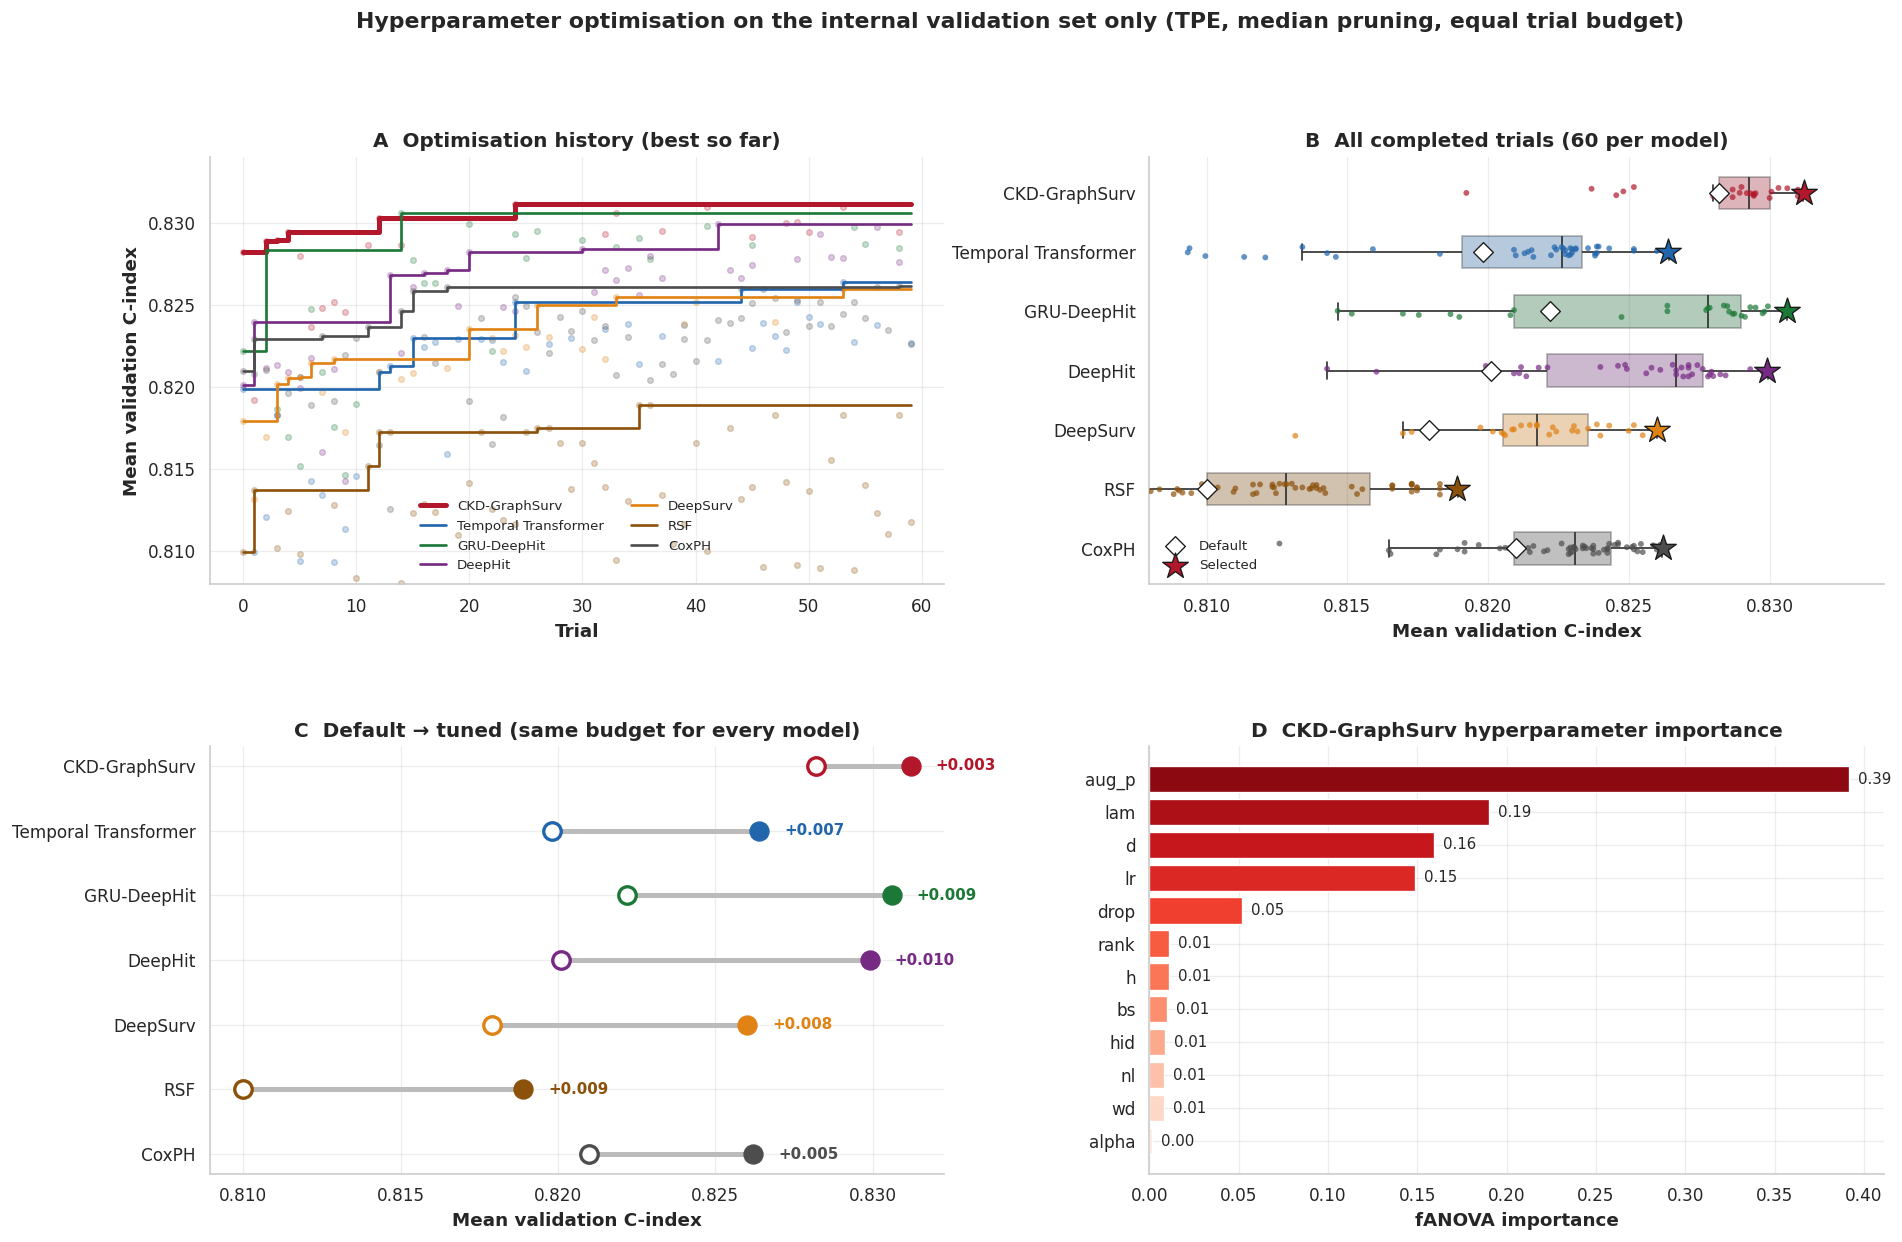

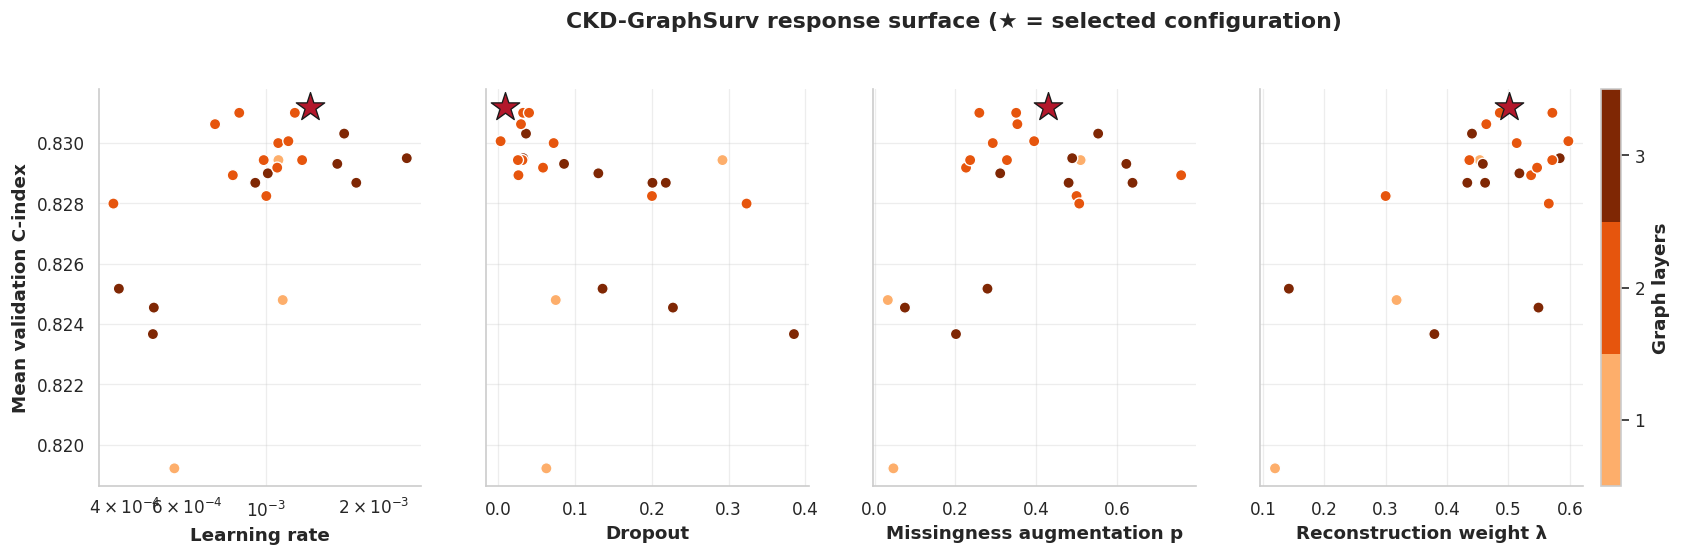

In [7]:
import optuna
from optuna.trial import TrialState
from optuna.study import MaxTrialsCallback
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE = ['CKD-GraphSurv', 'Temporal Transformer', 'GRU-DeepHit', 'DeepHit', 'DeepSurv', 'RSF', 'CoxPH']
LOCAL = Path('/content') if Path('/content').exists() else INT
DB_DRIVE, DB_LOCAL = INT/f'hpo_{VER}.db', LOCAL/f'hpo_{VER}_local.db'
if DB_DRIVE.exists() and (not DB_LOCAL.exists() or DB_DRIVE.stat().st_mtime > DB_LOCAL.stat().st_mtime): shutil.copy(DB_DRIVE, DB_LOCAL)
STORE = optuna.storages.RDBStorage(f'sqlite:///{DB_LOCAL}', heartbeat_interval=30, grace_period=90,
                                   failed_trial_callback=optuna.storages.RetryFailedTrialCallback(max_retry=1))
def sync(study, trial):
    shutil.copy(DB_LOCAL, str(DB_DRIVE) + '.tmp'); os.replace(str(DB_DRIVE) + '.tmp', DB_DRIVE)

def space(name, t):
    c, fl = t.suggest_categorical, t.suggest_float
    if name == 'RSF': return dict(n_estimators=c('n_estimators', [100, 200, 300]), min_samples_leaf=t.suggest_int('min_samples_leaf', 3, 40),
                                  max_features=c('max_features', ['sqrt', 'log2', '0.2', '0.4']))
    if name == 'CoxPH': return dict(penalizer=fl('penalizer', 1e-3, 1.0, log=True), l1_ratio=fl('l1_ratio', 0.0, 0.5))
    g = dict(lr=fl('lr', 2e-4, 3e-3, log=True), wd=fl('wd', 1e-6, 1e-3, log=True), bs=c('bs', [64, 128, 256]), drop=fl('drop', 0.0, 0.4), aug_p=fl('aug_p', 0.0, 0.8))
    if name != 'DeepSurv': g['alpha'] = c('alpha', [0.0, 0.05, 0.1, 0.2, 0.4])
    if name == 'CKD-GraphSurv': g.update(d=c('d', [16, 32, 64]), h=c('h', [2, 4]), hid=c('hid', [32, 64, 128]), nl=c('nl', [1, 2, 3]), rank=c('rank', [2, 4, 8]), lam=fl('lam', 0.0, 0.6))
    if name == 'Temporal Transformer': g.update(d=c('d', [32, 64, 128]), h=c('h', [2, 4, 8]), L=c('L', [1, 2, 3]))
    if name == 'GRU-DeepHit': g.update(d=c('d', [32, 64, 128]), layers=c('layers', [1, 2, 3]))
    if name in ('DeepHit', 'DeepSurv'): g['h'] = c('h', [64, 128, 256])
    return g
SPACE_TXT = {'shared (all deep models)': 'lr 2e-4–3e-3 (log); weight decay 1e-6–1e-3 (log); batch {64,128,256}; dropout 0–0.4; missingness augmentation p 0–0.8; ranking weight α {0,0.05,0.1,0.2,0.4} (hazard models)',
             'CKD-GraphSurv': 'node dim {16,32,64}; heads {2,4}; hidden {32,64,128}; graph layers {1,2,3}; PH rank {2,4,8}; reconstruction weight λ 0–0.6',
             'Temporal Transformer': 'model dim {32,64,128}; heads {2,4,8}; layers {1,2,3}', 'GRU-DeepHit': 'hidden {32,64,128}; GRU layers {1,2,3}',
             'DeepHit': 'hidden {64,128,256}', 'DeepSurv': 'hidden {64,128,256}', 'RSF': 'trees {100,200,300}; min leaf 3–40; max features {sqrt,log2,0.2,0.4}',
             'CoxPH': 'penalty 1e-3–1 (log); L1 ratio 0–0.5'}
def default_params(name):
    t = optuna.trial.FixedTrial({**DEF_HP[name], 'max_features': DEF_HP['RSF']['max_features']}); return {k: v for k, v in space(name, t).items()}
def val_c(risk_va, risk_vs):
    return (concordance_index_censored(SP['val']['E'] == 1, SP['val']['Th'], risk_va)[0] + concordance_index_censored(SP['val']['E'] == 1, SP['val']['Th'], risk_vs)[0]) / 2

def objective(name):
    def obj(trial):
        hp = {**DEF_HP[name], **space(name, trial)}; seed_all(HPO_SEED); t0 = time.time()
        if name == 'CoxPH':
            try: cph = fit_cox(hp)
            except Exception: raise optuna.TrialPruned()
            r = [cph.predict_log_partial_hazard(pd.DataFrame(flat(SP[s]['X'], SP[s]['S']), columns=A_NAMES)[cph.params_.index]).values for s in ['val', 'val_sv']]
            sc = val_c(*r)
        elif name == 'RSF':
            rsf = fit_rsf(hp, HPO_SEED); sc = val_c(*[rsf.predict(flat(SP[s]['X'], SP[s]['S'])) for s in ['val', 'val_sv']]); del rsf; gc.collect()
        else:
            model, kind = build_model(name, None, hp); model.to(DEVICE); cfg = getattr(model, 'cfg', BASE_CFG); lossf = make_loss(kind, hp)
            opt, sch = make_opt(model, hp, EPOCHS); sc, wait = -1., 0
            for ep in range(EPOCHS):
                try: train_epoch(model, opt, lossf, hp, cfg.get('aug', True)); sch.step(); _, vc, vs = val_eval(model, lossf)
                except Exception: raise optuna.TrialPruned()
                if not np.isfinite(vc + vs): raise optuna.TrialPruned()
                if (vc + vs) / 2 > sc: sc, wait = (vc + vs) / 2, 0
                else: wait += 1
                trial.report(sc, ep)
                if trial.should_prune(): raise optuna.TrialPruned()
                if wait >= PATIENCE: break
            trial.set_user_attr('epochs', ep + 1); del model, opt; torch.cuda.empty_cache()
        trial.set_user_attr('default', trial.params == default_params(name)); trial.set_user_attr('sec', time.time() - t0); return sc
    return obj

def progress(name):
    def cb(study, trial):
        n = sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in study.trials)
        v = f'{trial.value:.4f}' if trial.value is not None else trial.state.name.lower()
        print(f'\r{name:<22} trial {n:>3}/{N_TRIALS}  this {v:<8}  best {study.best_value:.4f}', end='', flush=True)
    return cb

STUDIES = {}
for name in TUNE:
    st = optuna.create_study(study_name=f'{name}_{VER}', storage=STORE, direction='maximize', load_if_exists=True,
                             sampler=optuna.samplers.TPESampler(seed=HPO_SEED, n_startup_trials=12, multivariate=True),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=8))
    if len(st.trials) == 0: st.enqueue_trial(default_params(name))
    n = sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in st.trials)
    if n < N_TRIALS:
        st.optimize(objective(name), callbacks=[MaxTrialsCallback(N_TRIALS, states=(TrialState.COMPLETE, TrialState.PRUNED)), progress(name), sync], gc_after_trial=True); print()
    STUDIES[name] = st; print(f'✓ {name:<22} {N_TRIALS} trials · best validation C {st.best_value:.4f}')

def to_hp(name, p): p = dict(p); return {**DEF_HP[name], **p}
HP = {m: to_hp(m, STUDIES[m].best_params) for m in TUNE}; json.dump(HP, open(HP_PATH, 'w'), indent=1)
rows = []
for m in TUNE:
    tr = STUDIES[m].trials; comp = [t for t in tr if t.state == TrialState.COMPLETE]; dflt = next((t.value for t in comp if t.user_attrs.get('default')), np.nan)
    rows.append({'Model': m, 'Search space': SPACE_TXT[m], 'Selected configuration': ', '.join(f'{k}={v:.3g}' if isinstance(v, float) else f'{k}={v}' for k, v in STUDIES[m].best_params.items()),
                 'Default val C': round(dflt, 4), 'Tuned val C': round(STUDIES[m].best_value, 4), 'Gain': round(STUDIES[m].best_value - dflt, 4),
                 'Complete': len(comp), 'Pruned': sum(t.state == TrialState.PRUNED for t in tr)})
TABLE_HPO = pd.DataFrame(rows); TABLE_HPO.to_csv(RES/'tableS_hpo.csv', index=False); TABLE_HPO.to_latex(RES/'tableS_hpo.tex', index=False)
pd.DataFrame([{'Scope': k, 'Range': v} for k, v in SPACE_TXT.items()]).to_csv(RES/'tableS_search_space.csv', index=False)
display(TABLE_HPO.drop(columns='Search space').style.hide(axis='index').format(precision=4)
        .background_gradient(subset=['Tuned val C'], cmap='Reds').bar(subset=['Gain'], color='#9ECAE1')
        .set_table_styles([{'selector': 'th', 'props': [('background', '#1F4E79'), ('color', 'white')]}]))

fig = plt.figure(figsize=(18, 11)); gs = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.28)
ax = fig.add_subplot(gs[0, 0])
for m in TUNE:
    v = [(t.number, t.value) for t in STUDIES[m].trials if t.state == TrialState.COMPLETE]; x, y = np.array(v).T
    ax.scatter(x, y, color=PAL[m], s=12, alpha=0.25); yb = np.maximum.accumulate(y); x, yb = np.r_[x, len(STUDIES[m].trials) - 1], np.r_[yb, yb[-1]]
    ax.plot(x, yb, color=PAL[m], lw=3 if m == 'CKD-GraphSurv' else 1.6, label=m, drawstyle='steps-post')
ax.set_xlabel('Trial'); ax.set_ylabel('Mean validation C-index'); ax.set_title('A  Optimisation history (best so far)'); ax.legend(fontsize=8, ncol=2)
lo = min(np.nanpercentile([t.value for t in STUDIES[m].trials if t.state == TrialState.COMPLETE], 10) for m in TUNE); ax.set_ylim(lo, None)
ax = fig.add_subplot(gs[0, 1]); dv = pd.DataFrame([{'model': m, 'C': t.value} for m in TUNE for t in STUDIES[m].trials if t.state == TrialState.COMPLETE])
sns.boxplot(dv, x='C', y='model', hue='model', palette=PAL, ax=ax, fliersize=0, width=0.55, legend=False, boxprops={'alpha': 0.35})
sns.stripplot(dv, x='C', y='model', hue='model', palette=PAL, ax=ax, size=3.5, alpha=0.7, legend=False)
for i, m in enumerate(TUNE):
    r = TABLE_HPO.set_index('Model').loc[m]; ax.scatter(r['Default val C'], i, marker='D', s=70, color='white', edgecolor='k', zorder=6, label='Default' if i == 0 else None)
    ax.scatter(r['Tuned val C'], i, marker='*', s=260, color=PAL[m], edgecolor='k', zorder=7, label='Selected' if i == 0 else None)
ax.set_xlim(max(lo, dv['C'].min()), None); ax.set_xlabel('Mean validation C-index'); ax.set_ylabel(''); ax.set_title(f'B  All completed trials ({N_TRIALS} per model)'); ax.legend(fontsize=8, loc='lower left')
ax = fig.add_subplot(gs[1, 0]); tb = TABLE_HPO.set_index('Model').loc[TUNE[::-1]]
for i, (m, r) in enumerate(tb.iterrows()):
    ax.plot([r['Default val C'], r['Tuned val C']], [i, i], color='#BBBBBB', lw=3, zorder=1)
    ax.scatter(r['Default val C'], i, color='white', edgecolor=PAL[m], s=110, lw=2, zorder=2); ax.scatter(r['Tuned val C'], i, color=PAL[m], s=130, zorder=3)
    ax.text(r['Tuned val C'] + 0.0008, i, f"+{r['Gain']:.3f}", va='center', fontsize=9, fontweight='bold', color=PAL[m])
ax.set_yticks(range(len(tb))); ax.set_yticklabels(tb.index); ax.set_xlabel('Mean validation C-index'); ax.set_title('C  Default → tuned (same budget for every model)')
ax = fig.add_subplot(gs[1, 1])
try:
    imp = optuna.importance.get_param_importances(STUDIES['CKD-GraphSurv'], evaluator=optuna.importance.FanovaImportanceEvaluator(seed=HPO_SEED))
    iv = pd.Series(imp).sort_values(); ax.barh(iv.index, iv.values, color=sns.color_palette('Reds', len(iv)), edgecolor='white')
    for j, v in enumerate(iv.values): ax.text(v + 0.005, j, f'{v:.2f}', va='center', fontsize=9)
except Exception as e: ax.text(0.5, 0.5, f'importance unavailable\n{e}', ha='center', transform=ax.transAxes)
ax.set_xlabel('fANOVA importance'); ax.set_title('D  CKD-GraphSurv hyperparameter importance')
fig.suptitle('Hyperparameter optimisation on the internal validation set only (TPE, median pruning, equal trial budget)', fontweight='bold', y=0.99); save(fig, 'S05b_hpo')

dg = pd.DataFrame([{**t.params, 'C': t.value} for t in STUDIES['CKD-GraphSurv'].trials if t.state == TrialState.COMPLETE])
fig, axs = plt.subplots(1, 4, figsize=(19, 4.3), sharey=True)
for ax, (k, lg) in zip(axs, [('lr', True), ('drop', False), ('aug_p', False), ('lam', False)]):
    sc = ax.scatter(dg[k], dg['C'], c=dg['nl'], cmap=mpl.colors.ListedColormap(['#FDAE6B', '#E6550D', '#7F2704']), s=45, edgecolor='white', vmin=0.5, vmax=3.5)
    b = dg.loc[dg['C'].idxmax()]; ax.scatter(b[k], b['C'], marker='*', s=320, color=PAL['CKD-GraphSurv'], edgecolor='k', zorder=5)
    if lg: ax.set_xscale('log')
    ax.set_xlabel({'lr': 'Learning rate', 'drop': 'Dropout', 'aug_p': 'Missingness augmentation p', 'lam': 'Reconstruction weight λ'}[k])
axs[0].set_ylabel('Mean validation C-index'); cb = fig.colorbar(sc, ax=axs, ticks=[1, 2, 3], pad=0.01); cb.set_label('Graph layers')
fig.suptitle('CKD-GraphSurv response surface (★ = selected configuration)', fontweight='bold', y=1.03); save(fig, 'S05c_hpo_response')

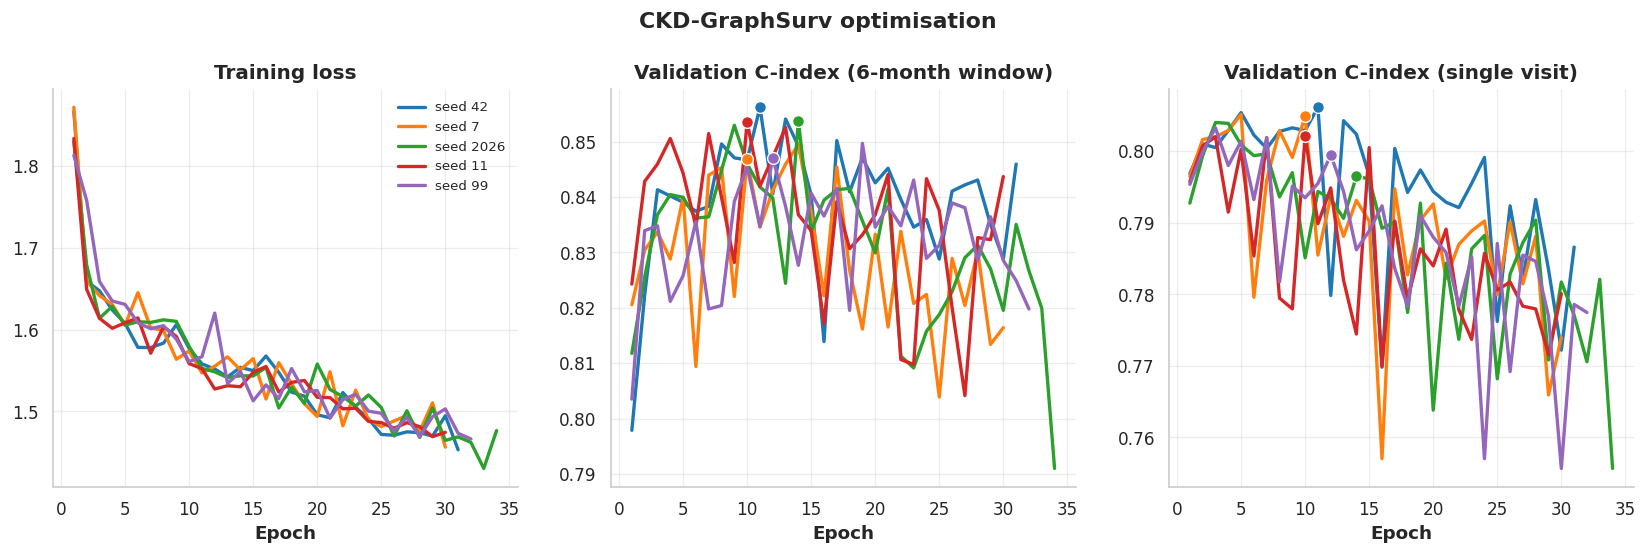

In [8]:
HIST = {}
for sd in SEEDS: _, _, HIST[('CKD-GraphSurv', sd)] = fit('CKD-GraphSurv', sd)
plot_hist({'CKD-GraphSurv' if len(SEEDS) == 1 else f'seed {s}': h for (m, s), h in HIST.items()}, 'CKD-GraphSurv optimisation', 'S06_train_proposed')

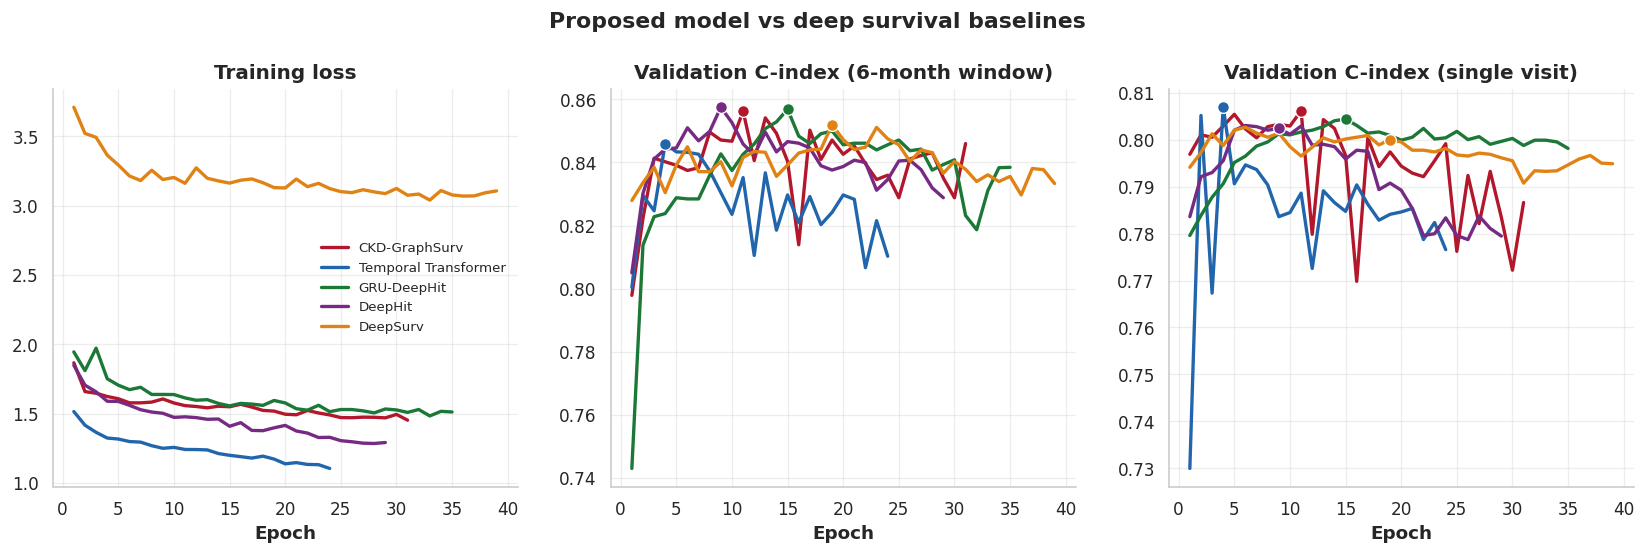

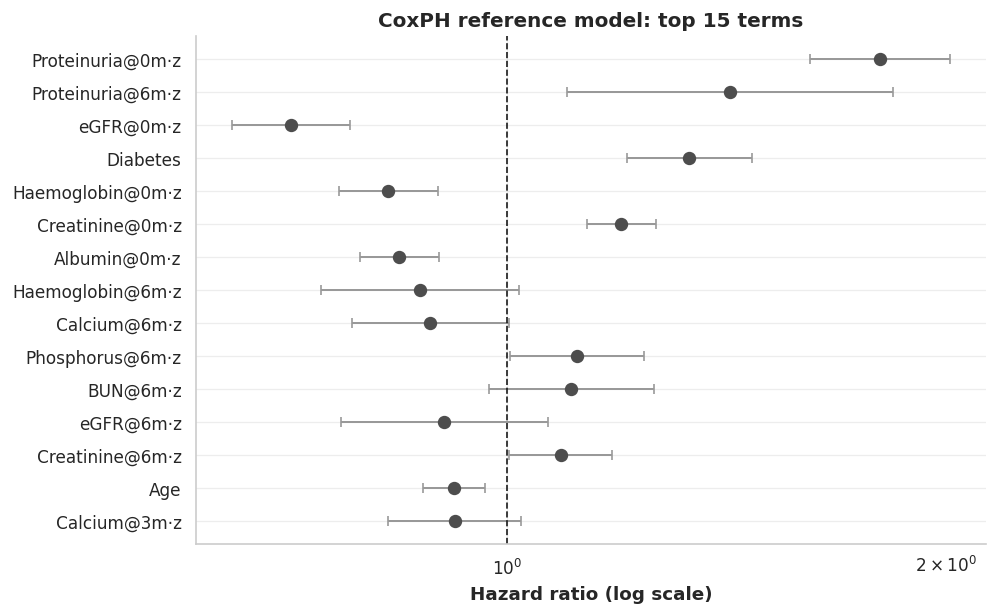

In [9]:
for name in ['Temporal Transformer', 'GRU-DeepHit', 'DeepHit', 'DeepSurv']:
    for sd in SEEDS: _, _, HIST[(name, sd)] = fit(name, sd)
if not (CK/'CoxPH__final.pkl').exists(): pdump(fit_cox(hp_of('CoxPH')), CK/'CoxPH__final.pkl')
EVAL_SETS = ['train', 'val', 'val_sv', 'test', 'test_sv', 'route', 'route_cmp', 'foshan']
RSF_PATH = CK/'RSF__predictions.pkl'; RSFP = pload(RSF_PATH) if RSF_PATH.exists() else {}
for sd in SEEDS:
    if all((sd, s) in RSFP for s in EVAL_SETS): continue
    rsf = fit_rsf(hp_of('RSF'), sd)
    for s in EVAL_SETS:
        out = np.empty((len(SP[s]['E']), NB))
        for i, fn in enumerate(rsf.predict_survival_function(flat(SP[s]['X'], SP[s]['S']))): out[i] = 1 - fn(np.clip(BIN_END, fn.x.min(), fn.x.max()))
        RSFP[(sd, s)] = out
    del rsf; gc.collect(); pdump(RSFP, RSF_PATH); print('✓ RSF seed', sd)
COX = pload(CK/'CoxPH__final.pkl')
plot_hist({m: HIST[(m, SEEDS[0])] for m in MODELS[:5]}, 'Proposed model vs deep survival baselines', 'S07_train_baselines')
cs = COX.summary.sort_values('coef', key=abs, ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.errorbar(cs['exp(coef)'], range(len(cs)), xerr=[cs['exp(coef)'] - cs['exp(coef) lower 95%'], cs['exp(coef) upper 95%'] - cs['exp(coef)']], fmt='o', color=PAL['CoxPH'], ecolor='#999999', capsize=3, ms=7)
ax.axvline(1, color='k', ls='--', lw=1); ax.set_yticks(range(len(cs))); ax.set_yticklabels(cs.index); ax.set_xscale('log'); ax.set_xlabel('Hazard ratio (log scale)'); ax.set_title('CoxPH reference model: top 15 terms')
save(fig, 'S07_coxph_hr')

ABL_no_survival_heads__PH___skip s42 ep  0 loss 1.8819 val C 0.8250 single-visit C 0.7910 best 0.8080
ABL_no_survival_heads__PH___skip s42 ep  1 loss 1.6952 val C 0.8323 single-visit C 0.7995 best 0.8159
ABL_no_survival_heads__PH___skip s42 ep  2 loss 1.6207 val C 0.8438 single-visit C 0.8001 best 0.8220
ABL_no_survival_heads__PH___skip s42 ep 10 loss 1.4690 val C 0.8317 single-visit C 0.8003 best 0.8220
ABL_no_survival_heads__PH___skip s42 ep 20 loss 1.3195 val C 0.8119 single-visit C 0.7952 best 0.8220
✓ ABL_no_survival_heads__PH___skip s42 10s · best mean val C 0.8220
ABL_no_survival_heads__PH___skip s7 ep  0 loss 1.9004 val C 0.8142 single-visit C 0.7949 best 0.8045
ABL_no_survival_heads__PH___skip s7 ep  1 loss 1.7066 val C 0.8173 single-visit C 0.7951 best 0.8062
ABL_no_survival_heads__PH___skip s7 ep  2 loss 1.6101 val C 0.8254 single-visit C 0.7971 best 0.8113
ABL_no_survival_heads__PH___skip s7 ep  4 loss 1.5484 val C 0.8342 single-visit C 0.8029 best 0.8185
ABL_no_survival_he

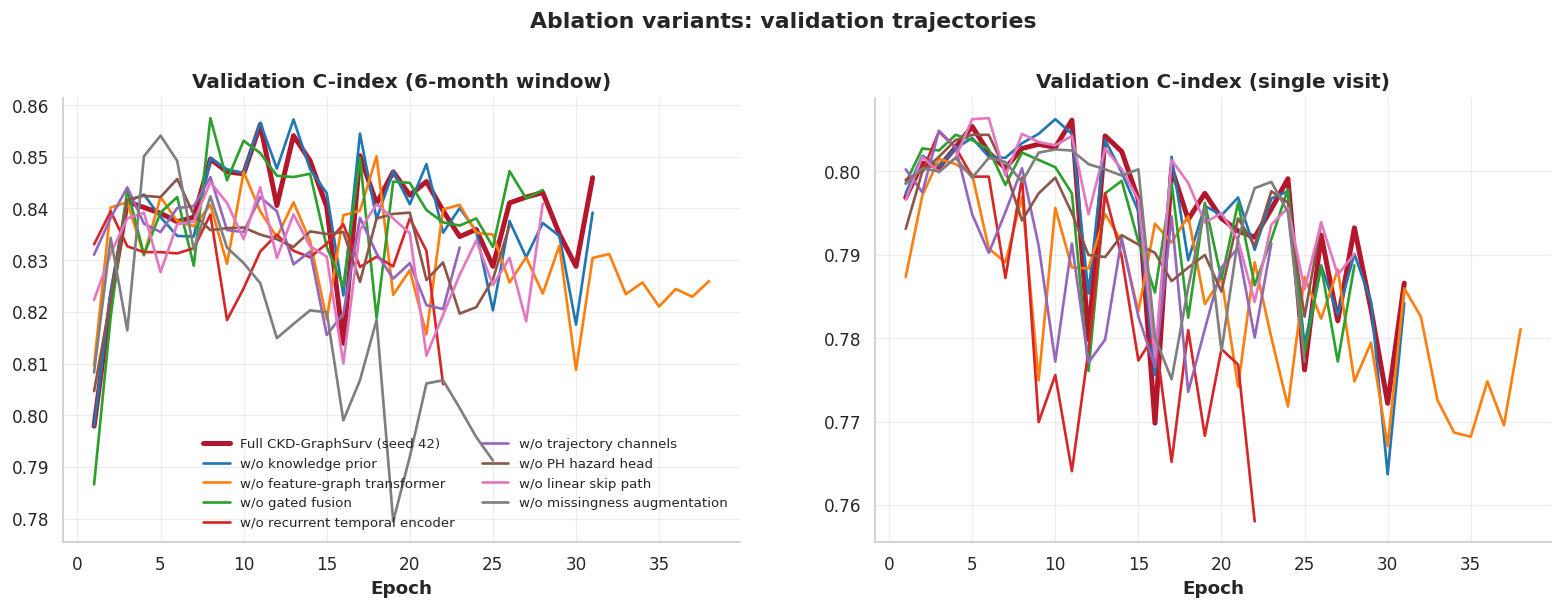

In [10]:
ABL = {'w/o knowledge prior': {'prior': False}, 'w/o feature-graph transformer': {'graph': False}, 'w/o gated fusion': {'gate': False},
       'w/o recurrent temporal encoder': {'temporal': False}, 'w/o trajectory channels': {'use_md': False}, 'w/o PH hazard head': {'ph': False},
       'w/o linear skip path': {'wide': False}, 'w/o missingness augmentation': {'aug': False}}
ABL_GROUP = {'w/o survival heads (PH + skip)': {'ph': False, 'wide': False}, 'w/o robustness design (augmentation + trajectories)': {'aug': False, 'use_md': False}}
BUILD = {'Step 0 · GRU hazard core': {'graph': False, 'ph': False, 'wide': False, 'aug': False}, 'Step 1 · + PH hazard head': {'graph': False, 'wide': False, 'aug': False},
         'Step 2 · + linear skip path': {'graph': False, 'aug': False}, 'Step 3 · + missingness augmentation': {'graph': False}}
ABL_ALL = {**ABL, **ABL_GROUP, **BUILD}; ABL_KEY, _seen = {}, {}
for k, cfg in ABL_ALL.items():
    ABL_KEY[k] = _seen.setdefault(tuple(sorted(cfg.items())), 'ABL_' + re.sub(r'[^A-Za-z0-9_]+', '_', k.replace('w/o ', 'no_').replace('-', '_').replace(' ', '_')).strip('_'))
ABL_MODELS = list(dict.fromkeys(ABL_KEY.values())); ABL_CFG = {ABL_KEY[k]: cfg for k, cfg in ABL_ALL.items()}
for v in ABL_MODELS:
    for sd in SEEDS: _, _, HIST[(v, sd)] = fit(v, sd, ABL_CFG[v])
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8)); pal = sns.color_palette('tab10', len(ABL))
for ax, key, ttl in [(axs[0], 'val_c', 'Validation C-index (6-month window)'), (axs[1], 'val_c_sv', 'Validation C-index (single visit)')]:
    h = HIST[('CKD-GraphSurv', SEEDS[0])]; ax.plot(np.arange(1, len(h[key]) + 1), h[key], color=PAL['CKD-GraphSurv'], lw=3, label='Full CKD-GraphSurv (seed 42)')
    for (k, _), c in zip(ABL.items(), pal): h = HIST[(ABL_KEY[k], SEEDS[0])]; ax.plot(np.arange(1, len(h[key]) + 1), h[key], color=c, lw=1.6, label=k)
    ax.set_xlabel('Epoch'); ax.set_title(ttl)
axs[0].legend(fontsize=8, ncol=2); fig.suptitle('Ablation variants: validation trajectories', fontweight='bold', y=1.03); save(fig, 'S08_train_ablations')

cached ABL_no_survival_heads__PH___skip 42
cached ABL_no_survival_heads__PH___skip 7
cached ABL_no_survival_heads__PH___skip 2026
cached ABL_no_survival_heads__PH___skip 11
cached ABL_no_survival_heads__PH___skip 99
cached ABL_no_robustness_design__augmentation___trajectories 42
cached ABL_no_robustness_design__augmentation___trajectories 7
cached ABL_no_robustness_design__augmentation___trajectories 2026
cached ABL_no_robustness_design__augmentation___trajectories 11
cached ABL_no_robustness_design__augmentation___trajectories 99
cached ABL_Step_0___GRU_hazard_core 42
cached ABL_Step_0___GRU_hazard_core 7
cached ABL_Step_0___GRU_hazard_core 2026
cached ABL_Step_0___GRU_hazard_core 11
cached ABL_Step_0___GRU_hazard_core 99
cached ABL_Step_1_____PH_hazard_head 42
cached ABL_Step_1_____PH_hazard_head 7
cached ABL_Step_1_____PH_hazard_head 2026
cached ABL_Step_1_____PH_hazard_head 11
cached ABL_Step_1_____PH_hazard_head 99
cached ABL_Step_2_____linear_skip_path 42
cached ABL_Step_2_____li

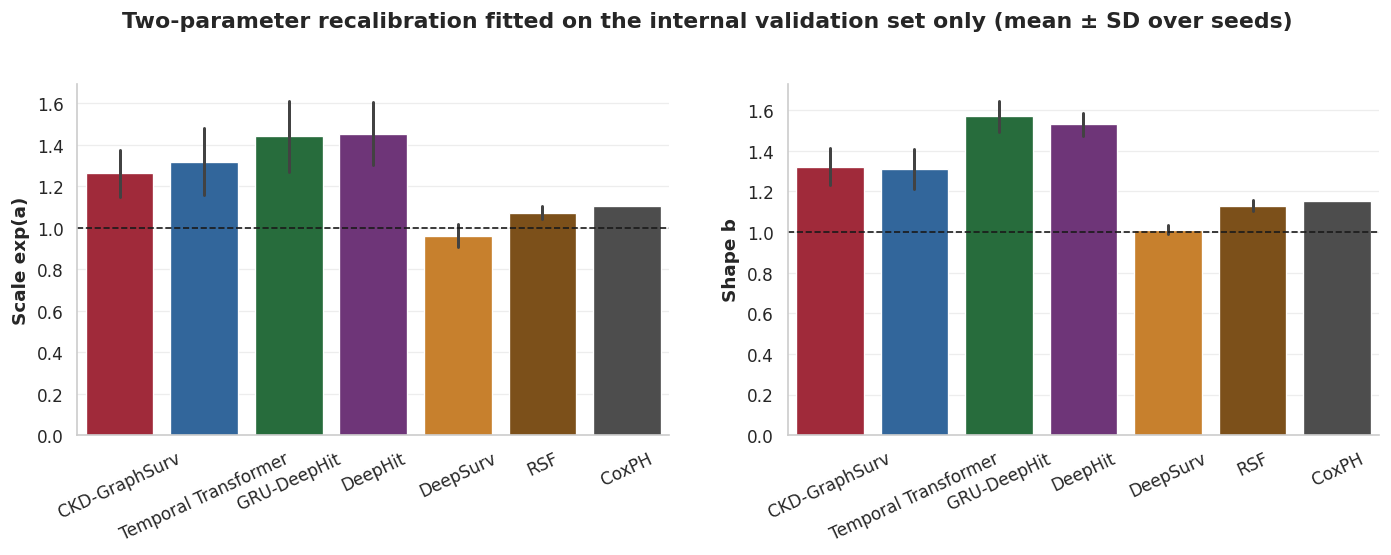

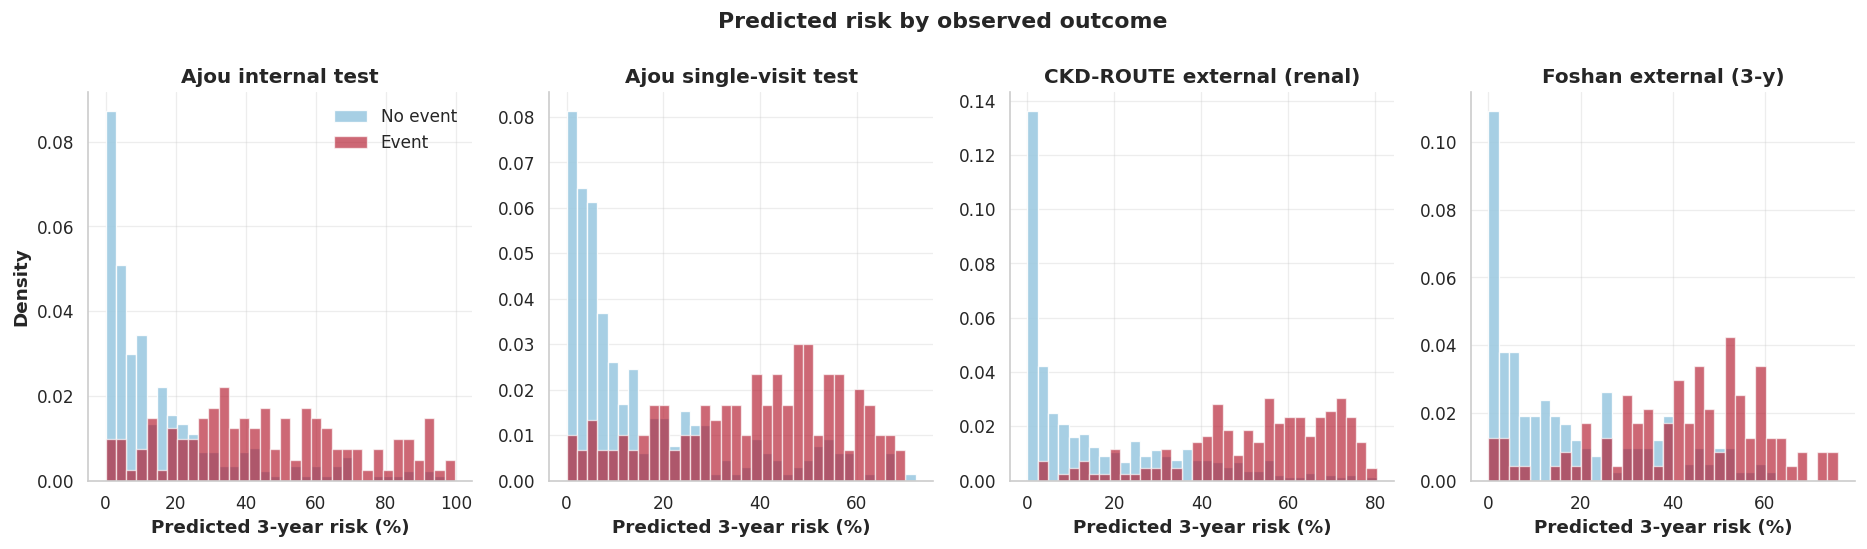

In [11]:
PRED_PATH = INT/f'predictions_{VER}.pkl'; PRED = pload(PRED_PATH) if PRED_PATH.exists() else {}
EVAL_SETS = ['train', 'val', 'val_sv', 'test', 'test_sv', 'route', 'route_cmp', 'foshan']
for name in [m for m in MODELS if m not in ('CoxPH', 'RSF')] + ABL_MODELS:
    for sd in SEEDS:
        if all((name, sd, s) in PRED for s in EVAL_SETS): continue
        model, kind, _ = fit(name, sd, ABL_CFG.get(name))
        bres = None
        if kind == 'cox':
            ga = {'X': np.concatenate([SP['train']['X'], single_visit(SP['train']['X'])]), 'S': np.r_[SP['train']['S'], SP['train']['S']],
                  'Th': AUG['Th'], 'E': AUG['E'], 'Tb': np.r_[SP['train']['Tb'], SP['train']['Tb']]}
            bres = breslow(predict(model, kind, ga)['risk'], AUG['Th'], AUG['E'])
        for s in EVAL_SETS: PRED[(name, sd, s)] = predict(model, kind, SP[s], bres)
        pdump(PRED, PRED_PATH); print('cached', name, sd)
for sd in SEEDS:
    for s in EVAL_SETS:
        A = flat(SP[s]['X'], SP[s]['S'])
        if ('CoxPH', sd, s) not in PRED: PRED[('CoxPH', sd, s)] = {'cif': 1 - COX.predict_survival_function(pd.DataFrame(A, columns=A_NAMES)[COX.params_.index], times=BIN_END).values.T}
        if ('RSF', sd, s) not in PRED: PRED[('RSF', sd, s)] = {'cif': RSFP[(sd, s)]}
pdump(PRED, PRED_PATH); S0 = SEEDS[0]
def recal(cif, a, b): H = -np.log(np.clip(1 - cif, 1e-9, 1)); return 1 - np.exp(-np.exp(a) * np.clip(H, 1e-9, None) ** b)
def recal_ll(cif, Tb, E, a, b):
    S = 1 - recal(cif, a, b); Sp = np.concatenate([np.ones((len(S), 1)), S[:, :-1]], 1); ar = np.arange(len(S))
    return np.where(E == 1, np.log(np.clip(Sp[ar, Tb] - S[ar, Tb], 1e-12, None)), np.log(np.clip(Sp[ar, Tb], 1e-12, None))).sum()
RECAL = {}
for (m, sd, s) in list(PRED):
    if s != 'val' or (m, sd) in RECAL: continue
    cif = np.concatenate([PRED[(m, sd, 'val')]['cif'], PRED[(m, sd, 'val_sv')]['cif']]); Tb = np.r_[SP['val']['Tb'], SP['val']['Tb']]; E = np.r_[SP['val']['E'], SP['val']['E']]
    best = (-np.inf, 0., 1.)
    for a_ in np.linspace(-1.5, 1.5, 61):
        for b_ in np.linspace(0.5, 2.5, 41):
            ll = recal_ll(cif, Tb, E, a_, b_)
            if ll > best[0]: best = (ll, a_, b_)
    RECAL[(m, sd)] = best[1:]
PRED = {(m, sd, s): {'cif': recal(v['cif'], *RECAL[(m, sd)]), 'cif_raw': v['cif']} for (m, sd, s), v in PRED.items()}
PA = {(m, s): {'cif': np.mean([PRED[(m, sd, s)]['cif'] for sd in SEEDS], 0)} for m in MODELS + ABL_MODELS for s in EVAL_SETS}
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, j, lb in [(axs[0], 0, 'Scale exp(a)'), (axs[1], 1, 'Shape b')]:
    v = pd.DataFrame([{'model': m, 'v': np.exp(RECAL[(m, sd)][0]) if j == 0 else RECAL[(m, sd)][1]} for m in MODELS for sd in SEEDS])
    sns.barplot(v, x='model', y='v', hue='model', palette=PAL, ax=ax, errorbar='sd', legend=False); ax.axhline(1, color='k', ls='--', lw=1); ax.set_ylabel(lb); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25)
fig.suptitle('Two-parameter recalibration fitted on the internal validation set only (mean ± SD over seeds)', fontweight='bold', y=1.04); save(fig, 'S09_recalibration')
def risk_at(cif, m): return cif[:, int(m // BIN_M) - 1]
fig, axs = plt.subplots(1, 4, figsize=(19, 4.2), sharey=False)
for ax, s in zip(axs, MAIN_C):
    p = risk_at(PA[('CKD-GraphSurv', s)]['cif'], TAU) * 100; e = SP[s]['E']; bins = np.linspace(0, np.percentile(p, 99.5), 35)
    ax.hist(p[e == 0], bins=bins, color='#9ECAE1', density=True, alpha=0.9, label='No event'); ax.hist(p[e == 1], bins=bins, color=PAL['CKD-GraphSurv'], density=True, alpha=0.65, label='Event')
    ax.set_title(COHORTS[s]); ax.set_xlabel('Predicted 3-year risk (%)')
axs[0].set_ylabel('Density'); axs[0].legend(); fig.suptitle('Predicted risk by observed outcome', fontweight='bold', y=1.04); save(fig, 'S09_risk_distributions')

Cohort,Model,C-index,Mean td-AUC,AUC@12m,AUC@24m,AUC@36m,IBS / Brier,O/E
Ajou internal test,CKD-GraphSurv,0.850 ± 0.005 (0.811–0.887),0.902 ± 0.005 (0.870–0.937),0.919000,0.890000,0.885000,0.085700,1.100000
Ajou single-visit test,CKD-GraphSurv,0.825 ± 0.001 (0.789–0.856),0.875 ± 0.002 (0.835–0.905),0.891000,0.865000,0.853000,0.103300,1.310000
CKD-ROUTE external (renal),CKD-GraphSurv,0.922 ± 0.002 (0.906–0.939),0.945 ± 0.001 (0.927–0.961),0.964000,0.954000,0.919000,0.074900,1.000000
"CKD-ROUTE composite (n=1,138)",CKD-GraphSurv,0.917 ± 0.002 (0.904–0.931),0.938 ± 0.002 (0.923–0.955),0.948000,0.945000,0.920000,0.082000,1.060000
Foshan external (3-y),CKD-GraphSurv,0.842 ± 0.004 (0.793–0.882),0.842 ± 0.004 (0.793–0.882),nan,nan,0.842000,0.166900,1.380000
Ajou internal test,Temporal Transformer,0.845 ± 0.003 (0.809–0.880),0.897 ± 0.007 (0.863–0.930),0.912000,0.885000,0.880000,0.093600,1.460000
Ajou single-visit test,Temporal Transformer,0.825 ± 0.003 (0.789–0.858),0.876 ± 0.002 (0.838–0.905),0.891000,0.869000,0.854000,0.103200,1.420000
CKD-ROUTE external (renal),Temporal Transformer,0.917 ± 0.004 (0.899–0.936),0.940 ± 0.002 (0.921–0.956),0.952000,0.947000,0.922000,0.081700,1.180000
"CKD-ROUTE composite (n=1,138)",Temporal Transformer,0.912 ± 0.004 (0.899–0.927),0.933 ± 0.003 (0.918–0.950),0.938000,0.940000,0.922000,0.088800,1.240000
Foshan external (3-y),Temporal Transformer,0.834 ± 0.002 (0.787–0.876),0.834 ± 0.002 (0.787–0.876),nan,nan,0.834000,0.178200,1.470000


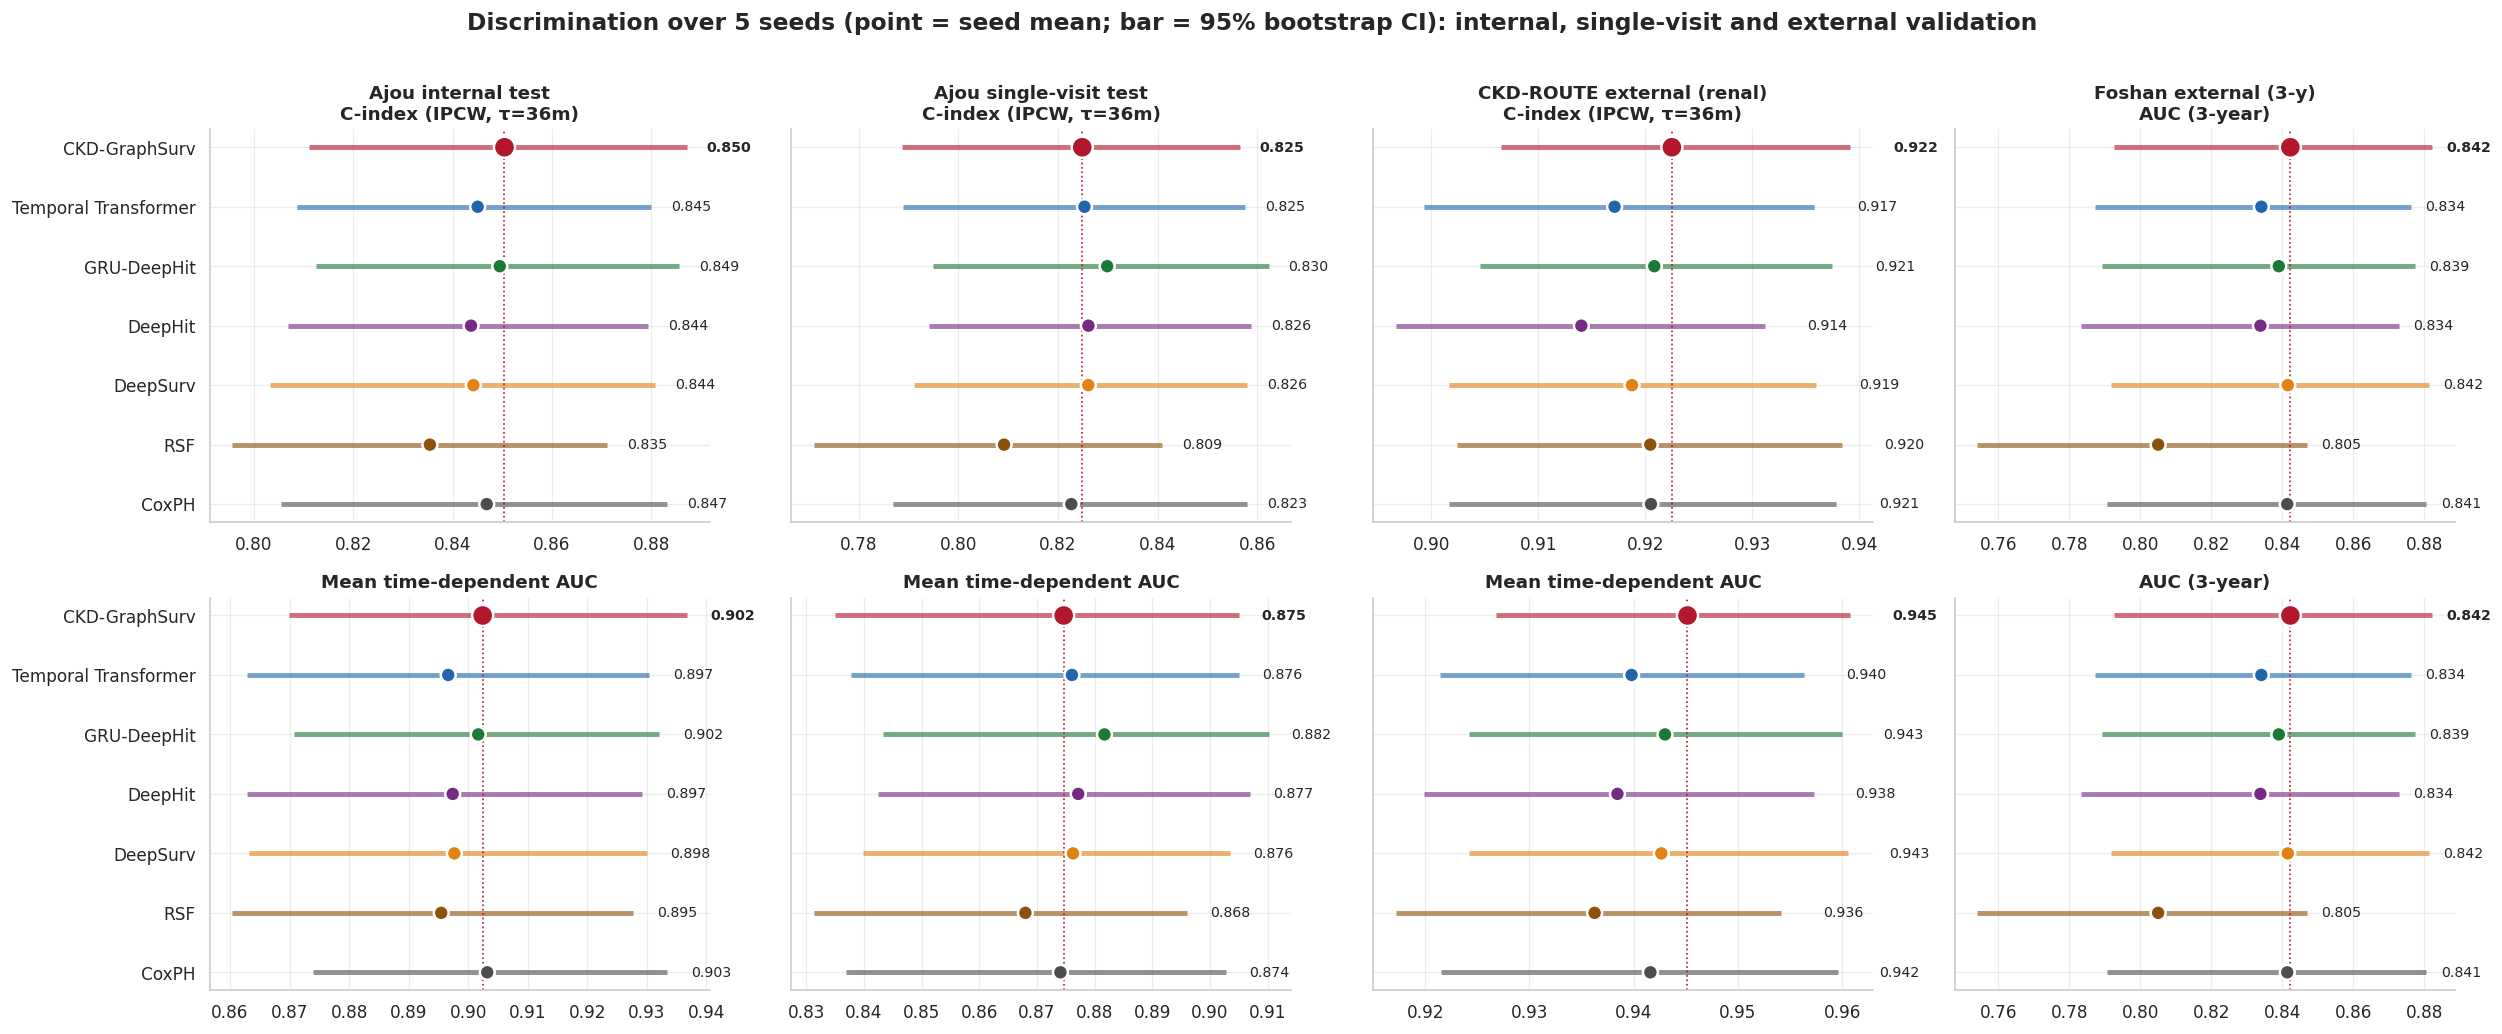

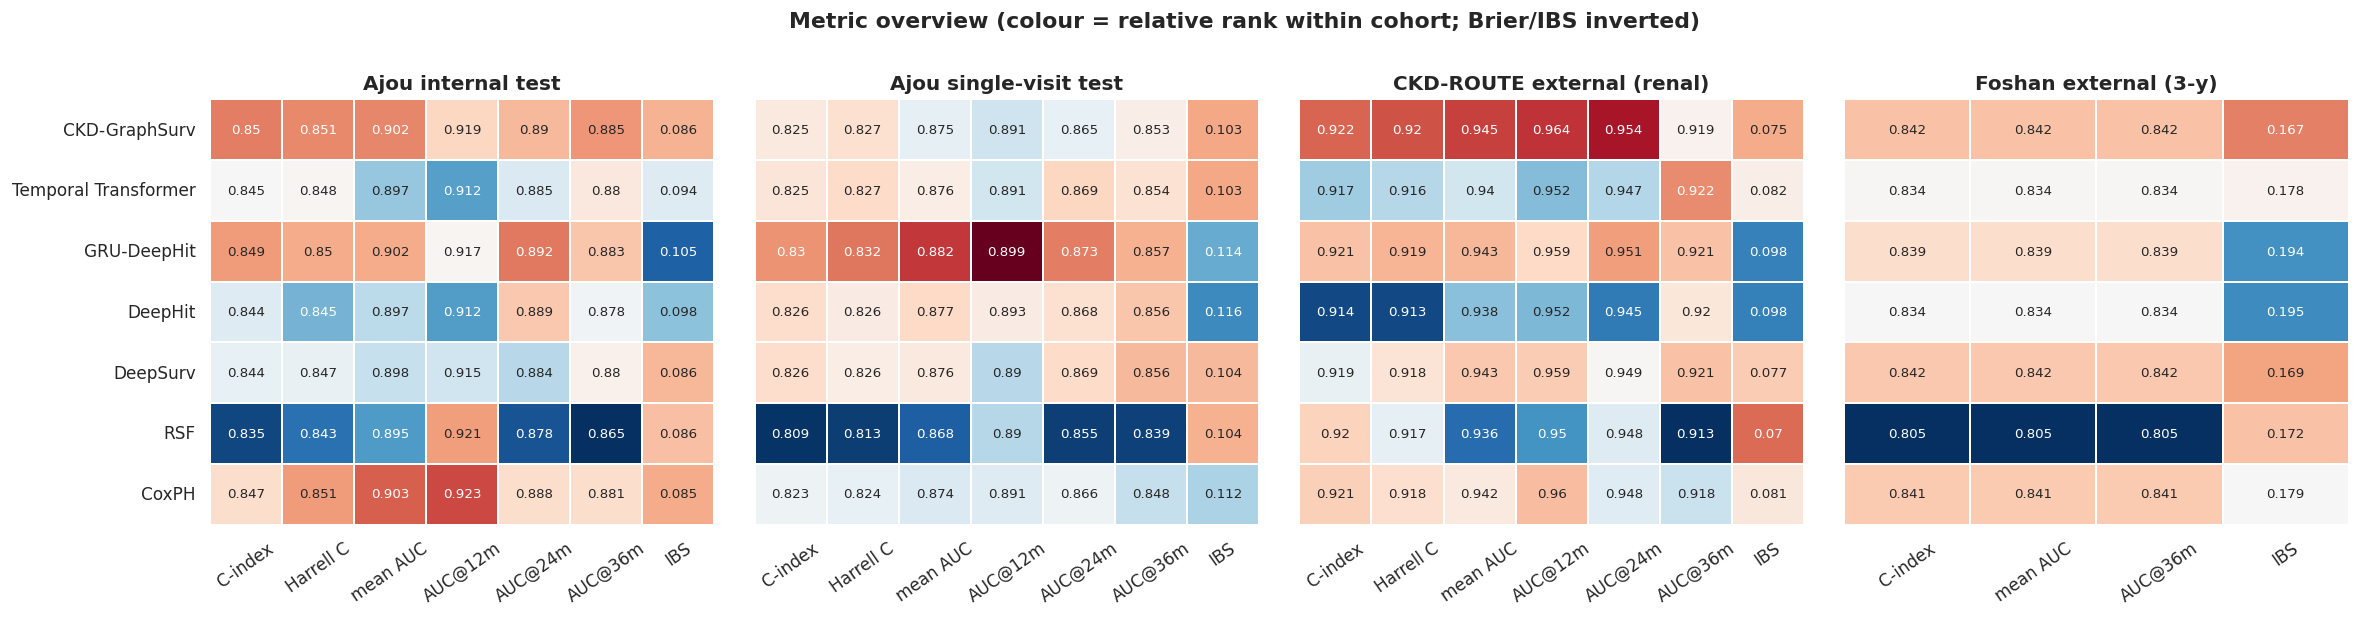

In [12]:
def ystr(Th, E): return np.array(list(zip(E == 1, Th.astype(float))), dtype=[('e', '?'), ('t', '<f8')])
def km_at(Th, E, t):
    if len(Th) == 0: return np.nan
    return float(KaplanMeierFitter().fit(Th, E).cumulative_density_at_times([t]).values[0])
def is_binary(s): return s == 'foshan'
def auc_times(y): return np.array([m for m in HZ if m < y['t'].max() and (y['e'] & (y['t'] <= m)).sum() > 0 and (y['t'] > m).sum() > 0])
def disc(cif, d, s):
    if is_binary(s):
        p = risk_at(cif, 36); a = roc_auc_score(d['E'], p); return a, a
    y = ystr(d['Th'], d['E']); tau = min(TAU, y['t'].max() - 1e-3)
    c = concordance_index_ipcw(y, y, risk_at(cif, TAU), tau=tau)[0]; tt = auc_times(y)
    return c, cumulative_dynamic_auc(y, y, np.stack([risk_at(cif, m) for m in tt], 1), tt)[1]
def metrics(cif, d, s):
    if is_binary(s):
        p = risk_at(cif, 36); y = d['E']; a = roc_auc_score(y, p)
        return {'C-index': a, 'mean AUC': a, 'AUC@36m': a, 'IBS': np.mean((p - y) ** 2), 'O/E': y.mean() / max(p.mean(), 1e-8)}
    y = ystr(d['Th'], d['E']); c, ma = disc(cif, d, s); r = {'C-index': c, 'Harrell C': concordance_index_censored(y['e'], y['t'], risk_at(cif, TAU))[0], 'mean AUC': ma}
    tt = auc_times(y); auc, _ = cumulative_dynamic_auc(y, y, np.stack([risk_at(cif, m) for m in tt], 1), tt)
    for m, a in zip(tt, auc): r[f'AUC@{int(m)}m'] = a
    gt = BIN_END[(BIN_END > y['t'].min()) & (BIN_END < min(y['t'].max(), TAU + 1e-3))]
    r['IBS'] = integrated_brier_score(y, y, 1 - cif[:, gt // BIN_M - 1], gt) if len(gt) > 1 else np.nan
    r['O/E'] = km_at(d['Th'], d['E'], CAL_M) / max(risk_at(cif, CAL_M).mean(), 1e-8); return r
BOOT_PATH = INT/f'bootstrap_{VER}.pkl'; BOOT = pload(BOOT_PATH) if BOOT_PATH.exists() else {}
rng = np.random.default_rng(2026)
if 'idx' not in BOOT: BOOT['idx'] = {s: [rng.integers(0, len(SP[s]['E']), len(SP[s]['E'])) for _ in range(N_BOOT)] for s in COHORTS}
def boot(m, s):
    d = SP[s]; cifs = [PRED[(m, sd, s)]['cif'] for sd in SEEDS]; out = []
    for ix in BOOT['idx'][s]:
        sub = {k: d[k][ix] for k in ['Th', 'E']}
        try: out.append(np.mean([disc(c[ix], sub, s) for c in cifs], 0))
        except Exception: out.append((np.nan, np.nan))
    return np.array(out)
ALLM = MODELS + ABL_MODELS
for m in ALLM:
    for s in COHORTS:
        if (m, s) not in BOOT: BOOT[(m, s)] = boot(m, s); pdump(BOOT, BOOT_PATH)
RESULTS = pd.DataFrame([{'model': m, 'seed': sd, 'cohort': lb, **metrics(PRED[(m, sd, s)]['cif'], SP[s], s)} for m in ALLM for sd in SEEDS for s, lb in COHORTS.items()])
RESULTS.to_csv(RES/'metrics_all_seeds.csv', index=False)
def ci(a): a = a[~np.isnan(a)]; return np.percentile(a, 2.5), np.percentile(a, 97.5)
main = []
for m in MODELS:
    for s, lb in COHORTS.items():
        rr = RESULTS[(RESULTS.model == m) & (RESULTS.cohort == lb)].drop(columns=['model', 'seed', 'cohort']); r, sdv = rr.mean(), rr.std()
        b = BOOT[(m, s)]; (cl, ch), (al, ah) = ci(b[:, 0]), ci(b[:, 1])
        main.append({'Cohort': lb, 'Model': m, 'C-index': f"{r['C-index']:.3f} ± {sdv['C-index']:.3f} ({cl:.3f}–{ch:.3f})",
                     'Mean td-AUC': f"{r['mean AUC']:.3f} ± {sdv['mean AUC']:.3f} ({al:.3f}–{ah:.3f})",
                     **{k: round(v, 3) for k, v in r.items() if k.startswith('AUC@')}, 'IBS / Brier': round(r['IBS'], 4), 'O/E': round(r['O/E'], 2),
                     '_c': r['C-index'], '_cs': sdv['C-index'], '_cl': cl, '_ch': ch, '_a': r['mean AUC'], '_al': al, '_ah': ah})
MAIN = pd.DataFrame(main); show = MAIN[[c for c in MAIN.columns if not c.startswith('_')]]
show.to_csv(RES/'table2_main_results.csv', index=False); show.to_latex(RES/'table2_main_results.tex', index=False, na_rep='–')
display(show.style.hide(axis='index').apply(lambda r: ['font-weight:bold;background:#FBE9E7' if r.Model == 'CKD-GraphSurv' else '' for _ in r], axis=1))
fig, axs = plt.subplots(2, 4, figsize=(21, 8.5), sharey='row')
for j, s in enumerate(MAIN_C):
    sub = MAIN[MAIN.Cohort == COHORTS[s]].set_index('Model').loc[MODELS[::-1]]
    for i, (v, lo, hi, ttl) in enumerate([('_c', '_cl', '_ch', 'C-index (IPCW, τ=36m)' if not is_binary(s) else 'AUC (3-year)'), ('_a', '_al', '_ah', 'Mean time-dependent AUC' if not is_binary(s) else 'AUC (3-year)')]):
        ax = axs[i, j]; y = np.arange(len(sub))
        ax.hlines(y, sub[lo], sub[hi], color=[PAL[m] for m in sub.index], lw=3, alpha=0.6)
        ax.scatter(sub[v], y, color=[PAL[m] for m in sub.index], s=[160 if m == 'CKD-GraphSurv' else 80 for m in sub.index], zorder=5, edgecolor='white', lw=1.5)
        for yy, (m, r) in zip(y, sub.iterrows()): ax.text(r[hi] + 0.004, yy, f'{r[v]:.3f}', va='center', fontsize=8.5, fontweight='bold' if m == 'CKD-GraphSurv' else 'normal')
        ax.axvline(sub.loc['CKD-GraphSurv', v], color=PAL['CKD-GraphSurv'], ls=':', lw=1); ax.set_yticks(y); ax.set_yticklabels(sub.index)
        ax.set_title(f'{COHORTS[s]}\n{ttl}' if i == 0 else ttl, fontsize=11)
fig.suptitle('Discrimination over 5 seeds (point = seed mean; bar = 95% bootstrap CI): internal, single-visit and external validation', fontweight='bold', fontsize=14, y=1.01); fig.tight_layout(); save(fig, 'S10_discrimination_forest')
hm = RESULTS[RESULTS.model.isin(MODELS)].groupby(['cohort', 'model']).mean(numeric_only=True).drop(columns='seed')
fig, axs = plt.subplots(1, 4, figsize=(23, 4.6), gridspec_kw={'wspace': 0.08})
for ax, s in zip(axs, MAIN_C):
    t = hm.loc[COHORTS[s]].loc[MODELS].dropna(axis=1, how='all'); t = t[[c for c in t.columns if c not in ('O/E',)]]
    z = (t - t.mean()) / (t.std() + 1e-9); z['IBS'] = -z['IBS']
    sns.heatmap(z, annot=t.round(3), fmt='', cmap='RdBu_r', center=0, ax=ax, cbar=False, linewidths=1, linecolor='white', annot_kws={'fontsize': 8})
    ax.set_title(COHORTS[s]); ax.set_ylabel(''); ax.tick_params(axis='x', rotation=35)
    if s != MAIN_C[0]: ax.set_yticklabels([])
fig.subplots_adjust(wspace=0.08); fig.suptitle('Metric overview (colour = relative rank within cohort; Brier/IBS inverted)', fontweight='bold', y=1.04); save(fig, 'S10_metric_heatmap')

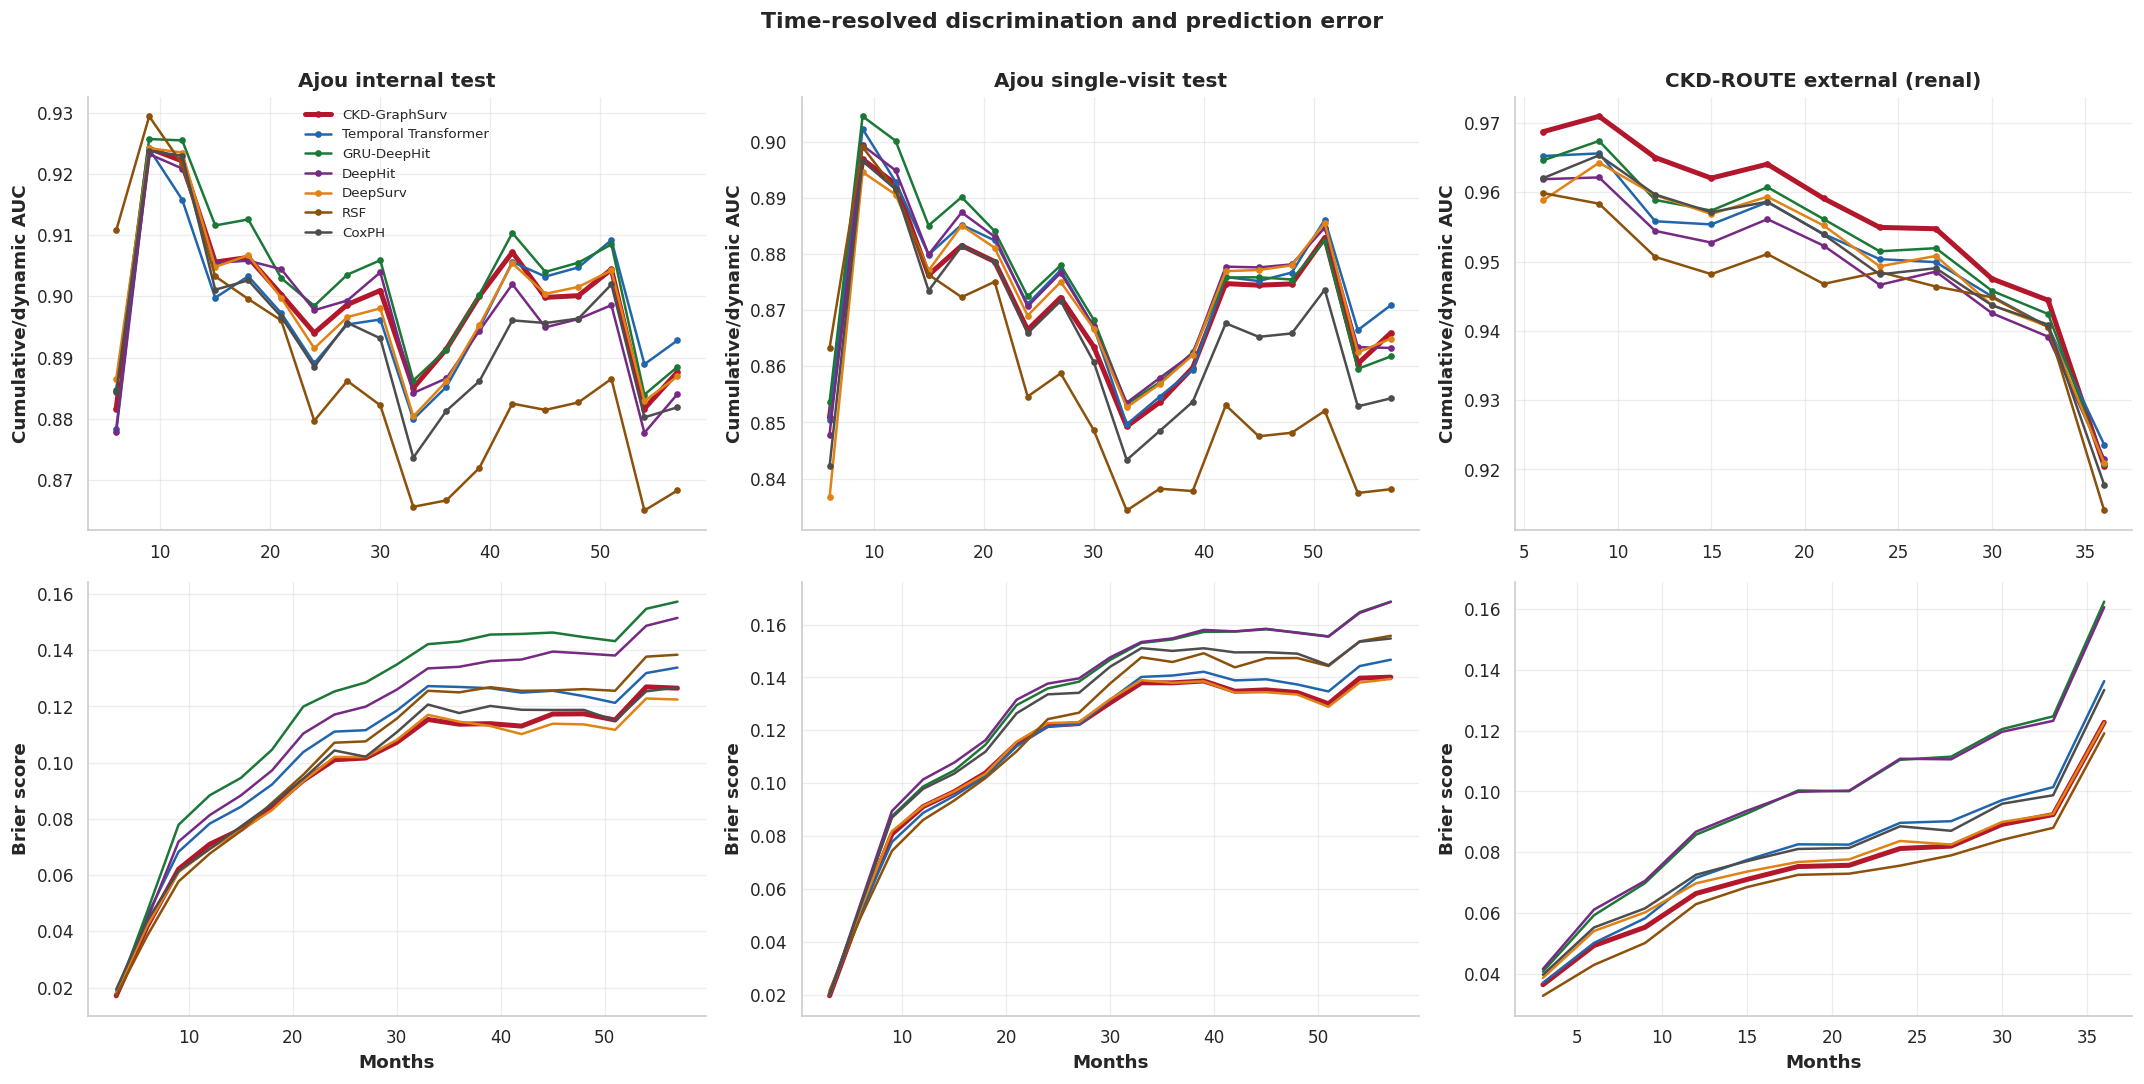

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for j, s in enumerate(['test', 'test_sv', 'route']):
    y = ystr(SP[s]['Th'], SP[s]['E']); tt = BIN_END[(BIN_END >= 6) & (BIN_END < min(y['t'].max(), 60))]; tt = np.array([t for t in tt if (y['e'] & (y['t'] <= t)).sum() > 0 and (y['t'] > t).sum() > 0])
    gt = BIN_END[(BIN_END > y['t'].min()) & (BIN_END < min(y['t'].max(), 60))]
    for m in MODELS:
        cif = PA[(m, s)]['cif']; lw = 3 if m == 'CKD-GraphSurv' else 1.5
        auc, _ = cumulative_dynamic_auc(y, y, cif[:, tt // BIN_M - 1], tt); axs[0, j].plot(tt, auc, color=PAL[m], lw=lw, marker='o', ms=3, label=m)
        _, bs_ = brier_score(y, y, 1 - cif[:, gt // BIN_M - 1], gt); axs[1, j].plot(gt, bs_, color=PAL[m], lw=lw, label=m)
    axs[0, j].set_title(COHORTS[s]); axs[0, j].set_ylabel('Cumulative/dynamic AUC'); axs[1, j].set_ylabel('Brier score'); axs[1, j].set_xlabel('Months')
axs[0, 0].legend(fontsize=8); fig.suptitle('Time-resolved discrimination and prediction error', fontweight='bold', y=1.0); fig.tight_layout(); save(fig, 'S11_tdauc_brier')

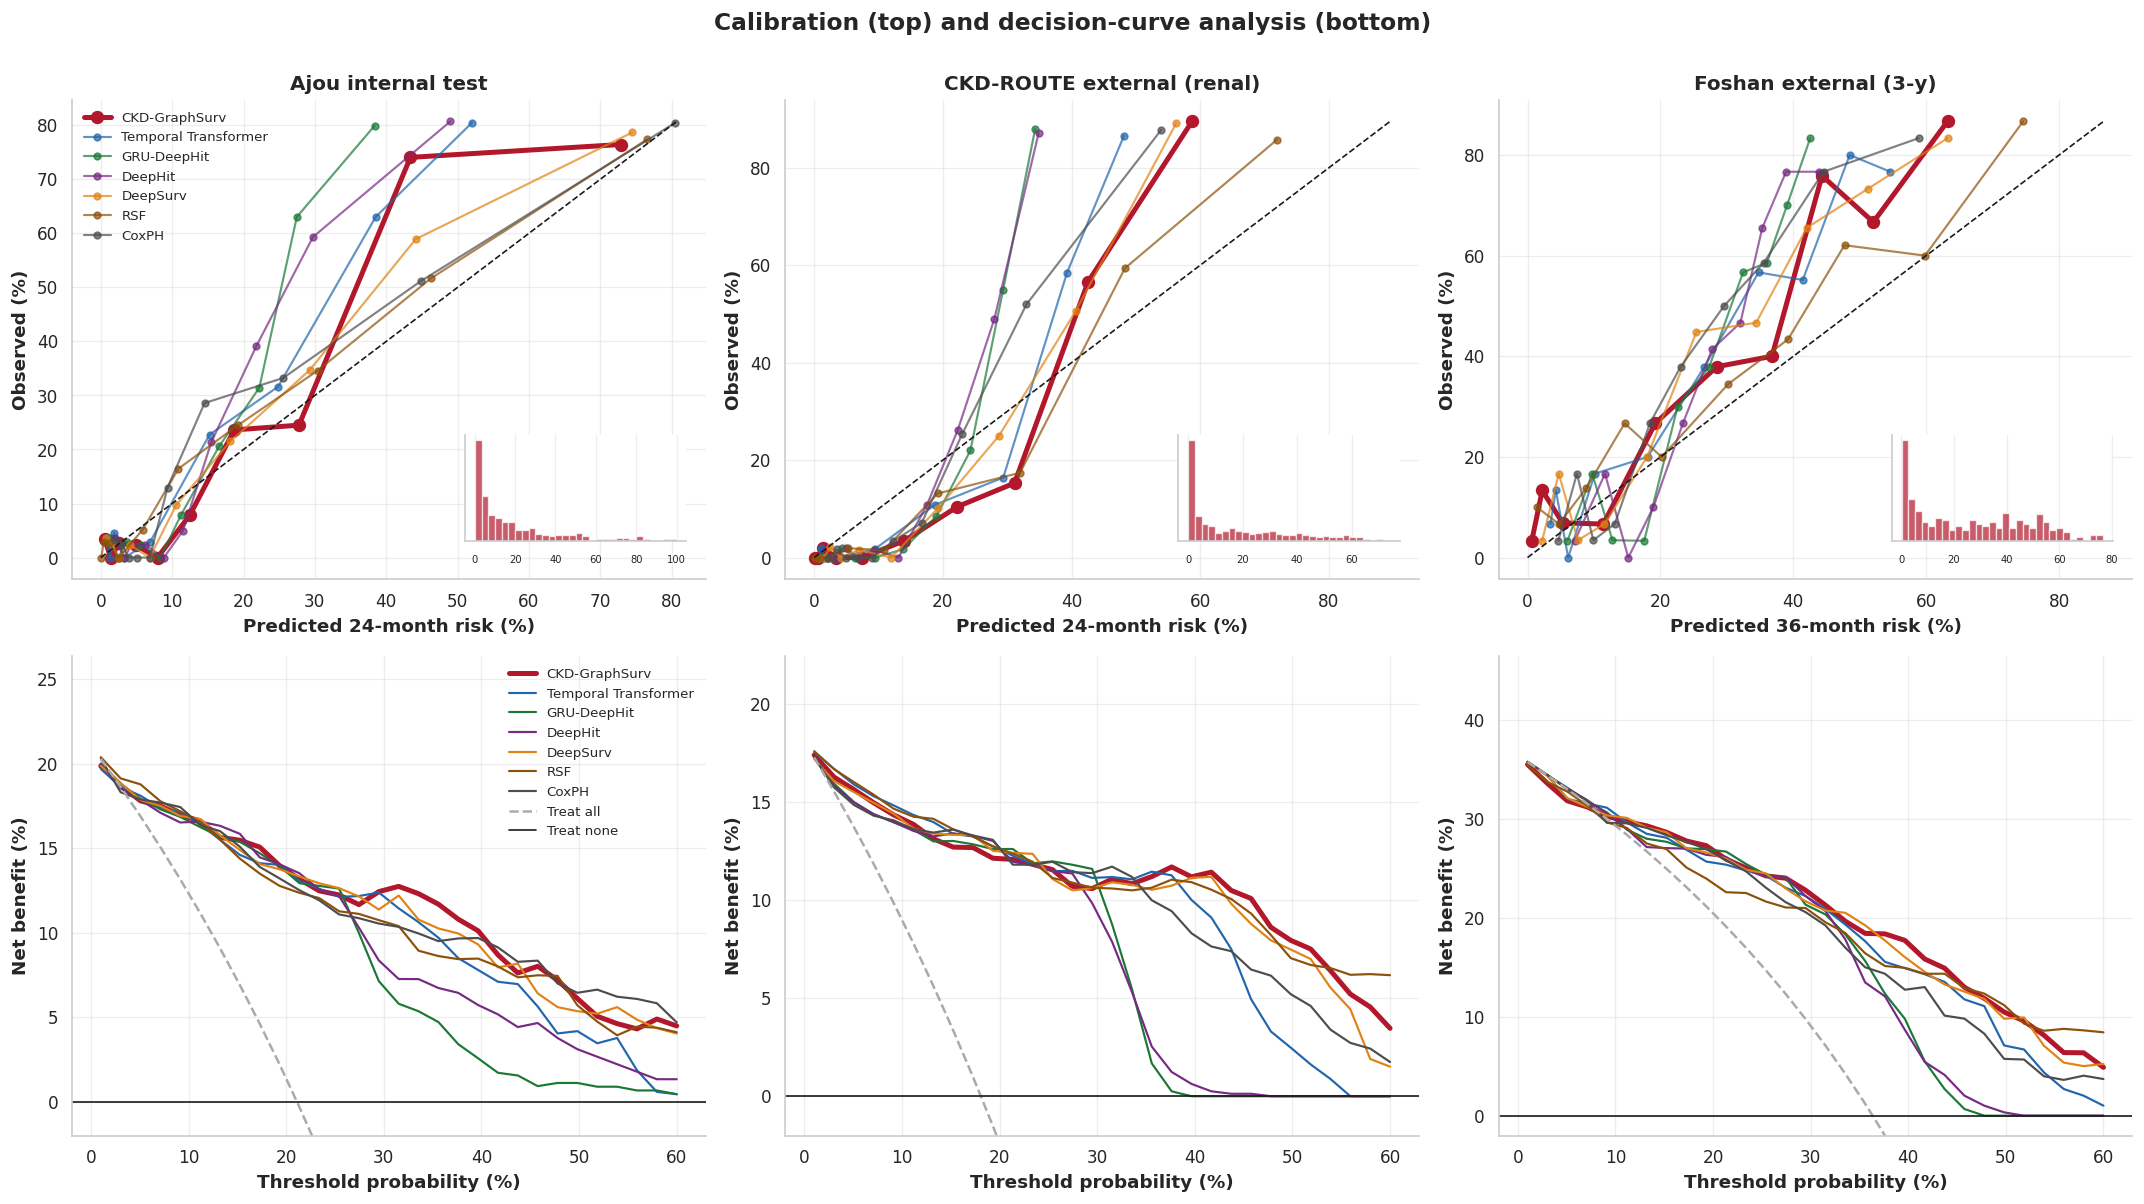

,cohort,model,horizon (m),calibration slope,ICI,O/E
0,Ajou internal test,CKD-GraphSurv,24,0.717,0.062,1.098
1,Ajou internal test,Temporal Transformer,24,0.930,0.083,1.450
2,Ajou internal test,GRU-DeepHit,24,1.598,0.111,1.540
3,Ajou internal test,DeepHit,24,1.266,0.111,1.388
4,Ajou internal test,DeepSurv,24,0.663,0.044,1.099
5,Ajou internal test,RSF,24,0.648,0.029,1.094
6,Ajou internal test,CoxPH,24,0.471,0.049,1.082
7,CKD-ROUTE external (renal),CKD-GraphSurv,24,1.594,0.095,0.994
8,CKD-ROUTE external (renal),Temporal Transformer,24,1.433,0.094,1.181
9,CKD-ROUTE external (renal),GRU-DeepHit,24,2.806,0.127,1.241


In [14]:
def calib(p, d, s, q, hz):
    df = pd.DataFrame({'p': p, 'T': d['Th'], 'E': d['E']}); df['g'] = pd.qcut(df.p.rank(method='first'), q, labels=False)
    return pd.DataFrame([{'pred': g.p.mean(), 'obs': g.E.mean() if is_binary(s) else km_at(g['T'], g['E'], hz)} for _, g in df.groupby('g')])
def net_benefit(p, d, s, ths, hz):
    obs = (lambda m: d['E'][m].mean()) if is_binary(s) else (lambda m: km_at(d['Th'][m], d['E'][m], hz)); allr = obs(np.ones(len(p), bool)); nb = []
    for pt in ths:
        hi = p >= pt; f = hi.mean(); r = obs(hi) if hi.sum() > 0 else 0.; nb.append(r * f - (1 - r) * f * pt / (1 - pt))
    return np.array(nb), np.array([allr - (1 - allr) * pt / (1 - pt) for pt in ths])
def cal_slope(p, d, s, hz):
    lp = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    if is_binary(s): return LogisticRegression(C=1e6).fit(lp[:, None], d['E']).coef_[0, 0]
    df = pd.DataFrame({'lp': lp, 'T': d['Th'], 'E': d['E']}); return CoxPHFitter().fit(df, 'T', 'E').params_['lp']
CAL_ROWS = []; fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for j, s in enumerate(['test', 'route', 'foshan']):
    d = SP[s]; hz = 36 if is_binary(s) else CAL_M; q = 10 if d['E'].sum() >= 80 else 5; mx = 0; ax = axs[0, j]
    for m in MODELS:
        p = risk_at(PA[(m, s)]['cif'], hz); cdf = calib(p, d, s, q, hz); mx = max(mx, np.nanmax(cdf.values))
        CAL_ROWS.append({'cohort': COHORTS[s], 'model': m, 'horizon (m)': hz, 'calibration slope': cal_slope(p, d, s, hz), 'ICI': np.nanmean(np.abs(cdf.pred - cdf.obs)),
                         'O/E': (d['E'].mean() if is_binary(s) else km_at(d['Th'], d['E'], hz)) / max(p.mean(), 1e-8)})
        ax.plot(cdf.pred * 100, cdf.obs * 100, marker='o', color=PAL[m], lw=3 if m == 'CKD-GraphSurv' else 1.3, ms=7 if m == 'CKD-GraphSurv' else 4, alpha=1 if m == 'CKD-GraphSurv' else 0.7, label=m)
    ax.plot([0, mx * 100], [0, mx * 100], 'k--', lw=1); ax.set_xlabel(f'Predicted {hz}-month risk (%)'); ax.set_ylabel('Observed (%)'); ax.set_title(COHORTS[s])
    ins = ax.inset_axes([0.62, 0.08, 0.35, 0.22]); ins.hist(risk_at(PA[('CKD-GraphSurv', s)]['cif'], hz) * 100, bins=30, color=PAL['CKD-GraphSurv'], alpha=0.7); ins.set_yticks([]); ins.tick_params(labelsize=6)
    ax = axs[1, j]; ths = np.linspace(0.01, 0.6, 30)
    for m in MODELS:
        nb, ta = net_benefit(risk_at(PA[(m, s)]['cif'], hz), d, s, ths, hz); ax.plot(ths * 100, nb * 100, color=PAL[m], lw=3 if m == 'CKD-GraphSurv' else 1.3, label=m)
    ax.plot(ths * 100, ta * 100, color='#AAAAAA', lw=1.5, ls='--', label='Treat all'); ax.axhline(0, color='k', lw=1, label='Treat none')
    ax.set_ylim(-2, max(2, ta[0] * 100 * 1.3)); ax.set_xlabel('Threshold probability (%)'); ax.set_ylabel('Net benefit (%)')
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
fig.suptitle('Calibration (top) and decision-curve analysis (bottom)', fontweight='bold', fontsize=14, y=1.0); fig.tight_layout(); save(fig, 'S12_calibration_dca')
CAL = pd.DataFrame(CAL_ROWS); CAL.to_csv(RES/'calibration.csv', index=False); display(CAL.round(3))

Metric,Baseline,Δ (CKD-GraphSurv advantage),95% CI,p,p Holm,p NI,p NI Holm
C-index,Temporal Transformer,+0.0057,+0.0019 to +0.0095,0.003,0.016,<0.001,<0.001
C-index,GRU-DeepHit,+0.0018,-0.0006 to +0.0041,0.146,0.355,<0.001,<0.001
C-index,DeepHit,+0.0082,+0.0046 to +0.0119,<0.001,<0.001,<0.001,<0.001
C-index,DeepSurv,+0.0036,+0.0011 to +0.0062,0.005,0.021,<0.001,<0.001
C-index,RSF,+0.0151,-0.0039 to +0.0341,0.118,0.355,0.005,0.005
C-index,CoxPH,+0.0019,-0.0006 to +0.0044,0.137,0.355,<0.001,<0.001
IBS,Temporal Transformer,+0.0082,+0.0055 to +0.0110,<0.001,<0.001,,
IBS,GRU-DeepHit,+0.0231,+0.0189 to +0.0274,<0.001,<0.001,,
IBS,DeepHit,+0.0209,+0.0124 to +0.0294,<0.001,<0.001,,
IBS,DeepSurv,+0.0023,+0.0012 to +0.0034,<0.001,<0.001,,


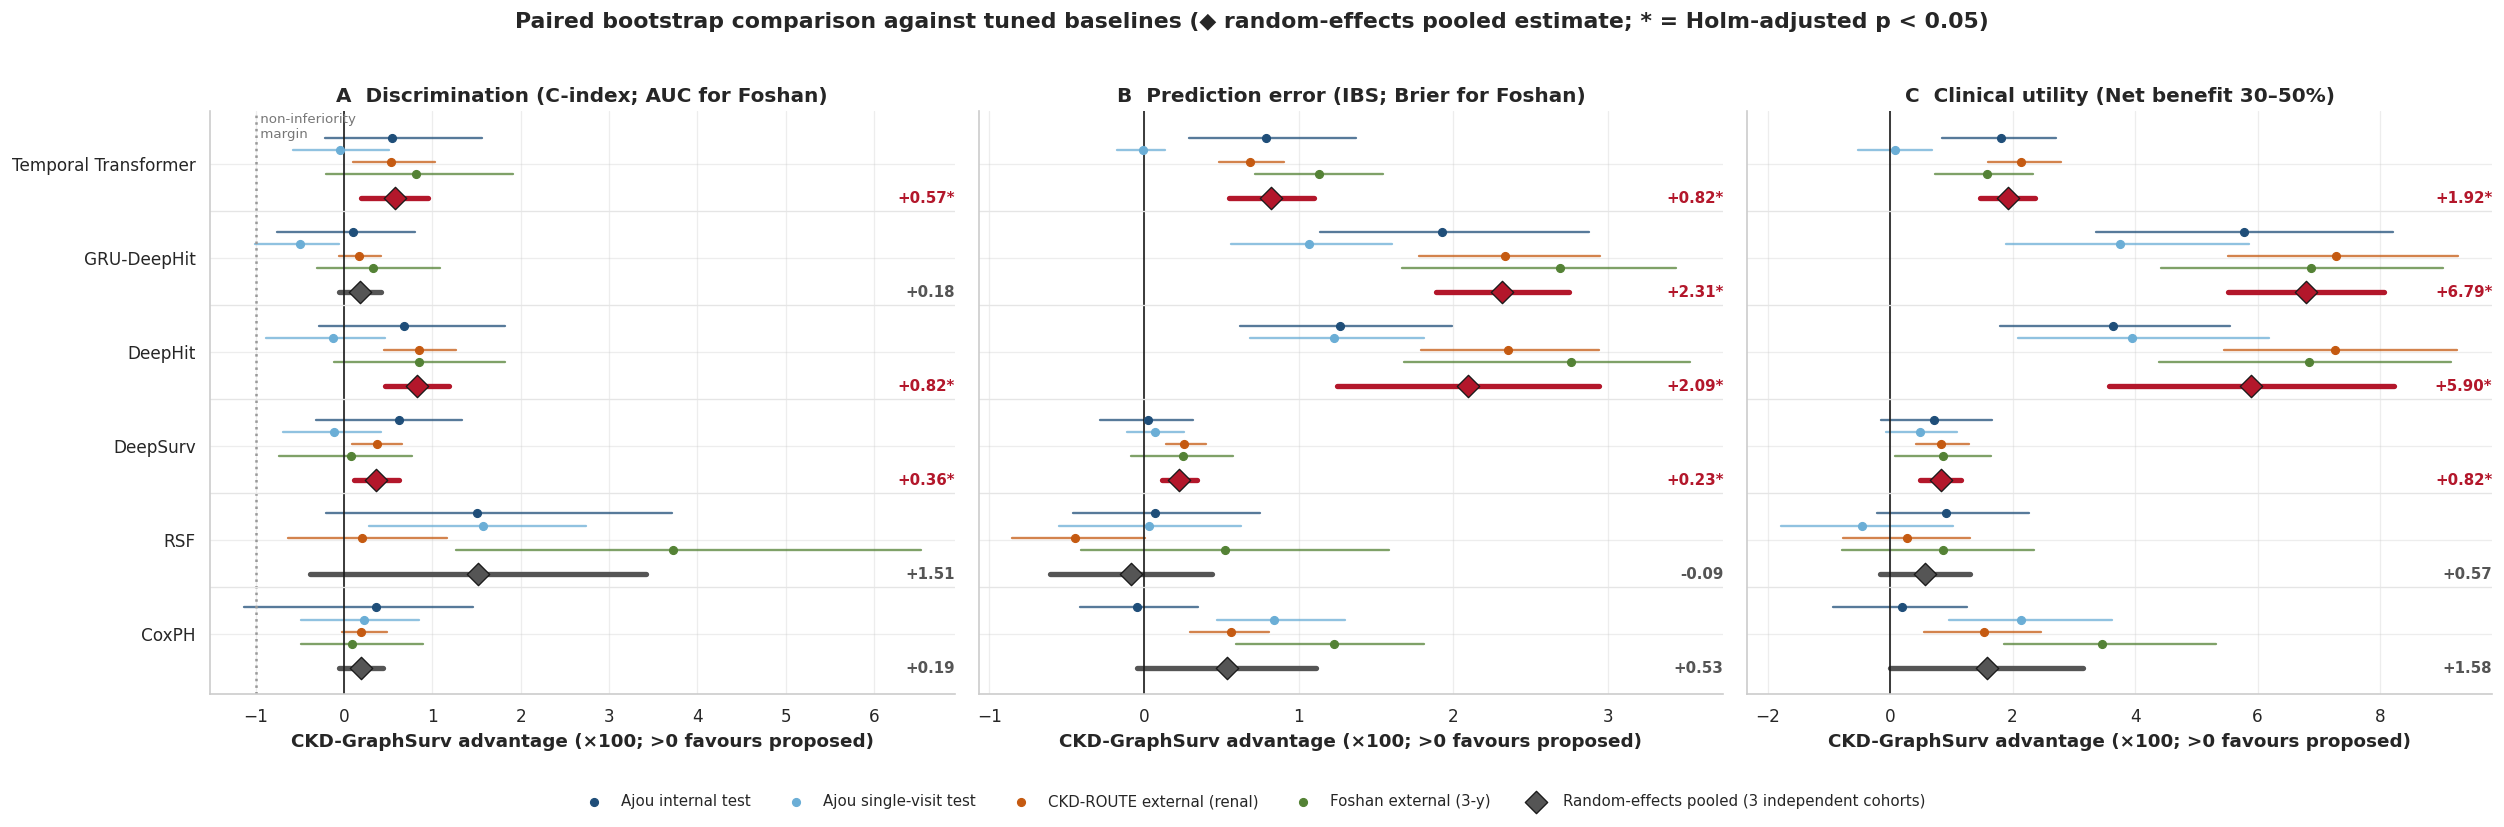

C-index                per-cohort Holm-significant: 1 better / 0 worse of 24 · pooled: 3 better / 0 worse of 6 · non-inferior (Holm) 24/24 per cohort, 6/6 pooled
IBS                    per-cohort Holm-significant: 14 better / 0 worse of 24 · pooled: 4 better / 0 worse of 6
Net benefit 30–50%     per-cohort Holm-significant: 15 better / 0 worse of 24 · pooled: 4 better / 0 worse of 6


In [15]:
from scipy.stats import norm
EXT_PATH = INT/f'bootstrap_ext_{VER}.pkl'; EXT = pload(EXT_PATH) if EXT_PATH.exists() else {}
NB_TH = np.round(np.arange(0.30, 0.501, 0.05), 2); INDEP = ['test', 'route', 'foshan']; NI_MARGIN = 0.01
COH_COL = {'test': '#1F4E79', 'test_sv': '#6BAED6', 'route': '#C55A11', 'foshan': '#548235'}
def hz_of(s): return 36 if is_binary(s) else CAL_M
def km_risk(T, E, t):
    if len(T) == 0: return np.nan
    ut, inv = np.unique(T, return_inverse=True); dth = np.bincount(inv, weights=(E == 1).astype(float)); cnt = np.bincount(inv)
    n = len(T) - np.r_[0, np.cumsum(cnt)[:-1]]; k = ut <= t; return 1 - np.prod(1 - dth[k] / n[k])
def ibs_of(cif, Th, E, s):
    if is_binary(s): return np.mean((risk_at(cif, 36) - E) ** 2)
    y = ystr(Th, E); gt = BIN_END[(BIN_END > y['t'].min()) & (BIN_END < min(y['t'].max(), TAU + 1e-3))]
    return integrated_brier_score(y, y, 1 - cif[:, gt // BIN_M - 1], gt)
def nb_mean(p, Th, E, s):
    out = []
    for pt in NB_TH:
        hi = p >= pt; f = hi.mean()
        if hi.sum() == 0: out.append(0.); continue
        r = E[hi].mean() if is_binary(s) else km_risk(Th[hi], E[hi], hz_of(s)); out.append(r * f - (1 - r) * f * pt / (1 - pt))
    return float(np.mean(out))
def ext_stats(cif, Th, E, s, with_nb=True):
    try: i = ibs_of(cif, Th, E, s)
    except Exception: i = np.nan
    return i, (nb_mean(risk_at(cif, hz_of(s)), Th, E, s) if with_nb else np.nan)
def point_ext(m, s, with_nb=True):
    d = SP[s]; return np.nanmean([ext_stats(PRED[(m, sd, s)]['cif'], d['Th'], d['E'], s, with_nb) for sd in SEEDS], 0)
def boot_ext(m, s, with_nb=True):
    d = SP[s]; cifs = [PRED[(m, sd, s)]['cif'] for sd in SEEDS]; out = np.full((N_BOOT, 2), np.nan)
    for i, ix in enumerate(BOOT['idx'][s]): out[i] = np.nanmean([ext_stats(c[ix], d['Th'][ix], d['E'][ix], s, with_nb) for c in cifs], 0)
    return out
def need_ext(m, s, with_nb=True):
    if (m, s) not in EXT or (with_nb and np.isnan(EXT[(m, s)]['boot'][:, 1]).all()):
        EXT[(m, s)] = {'point': point_ext(m, s, with_nb), 'boot': boot_ext(m, s, with_nb)}; pdump(EXT, EXT_PATH)
    return EXT[(m, s)]
def c_point(m, s): return RESULTS[(RESULTS.model == m) & (RESULTS.cohort == COHORTS[s])]['C-index'].mean()
def paired(a, b, s, metric):
    if metric == 'C-index': return c_point(a, s) - c_point(b, s), BOOT[(a, s)][:, 0] - BOOT[(b, s)][:, 0]
    j = 0 if metric == 'IBS' else 1; A, B = need_ext(a, s), need_ext(b, s)
    return A['point'][j] - B['point'][j], A['boot'][:, j] - B['boot'][:, j]
def wald(est, dv):
    se = np.nanstd(dv); return se, (2 * (1 - norm.cdf(abs(est) / se)) if se > 0 else np.nan)
def pool(ests, ses):
    e_, v = np.array(ests, float), np.maximum(np.array(ses, float), 1e-9) ** 2; w = 1 / v; fe = (w * e_).sum() / w.sum(); Q = (w * (e_ - fe) ** 2).sum()
    tau2 = max(0., (Q - (len(e_) - 1)) / (w.sum() - (w ** 2).sum() / w.sum())); ws = 1 / (v + tau2); return float((ws * e_).sum() / ws.sum()), float(np.sqrt(1 / ws.sum()))
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0.
    for r, i in enumerate(o): run = max(run, min(1., (len(p) - r) * p[i])); adj[i] = run
    return adj

METRICS = {'C-index': +1, 'IBS': -1, f'Net benefit {int(NB_TH[0]*100)}–{int(NB_TH[-1]*100)}%': +1}
BASES = [m for m in MODELS if m != 'CKD-GraphSurv']; rows = []
for met, sign in METRICS.items():
    key = 'NB' if met.startswith('Net') else met
    for s in MAIN_C:
        for b in BASES:
            est, dv = paired('CKD-GraphSurv', b, s, key); est, dv = sign * est, sign * dv; se, p = wald(est, dv)
            rows.append({'Metric': met, 'Cohort': COHORTS[s], '_s': s, 'Baseline': b, 'Δ': est, 'SE': se, 'lo': np.nanpercentile(dv, 2.5), 'hi': np.nanpercentile(dv, 97.5), 'p': p,
                         'p NI': 1 - norm.cdf((est + NI_MARGIN) / se) if key == 'C-index' else np.nan})
SIG = pd.DataFrame(rows)
for met in METRICS:
    k = SIG.Metric == met; SIG.loc[k, 'p Holm'] = holm(SIG.loc[k, 'p'])
    if met == 'C-index': SIG.loc[k, 'p NI Holm'] = holm(SIG.loc[k, 'p NI'])
prow = []
for met in METRICS:
    for b in BASES:
        t = SIG[(SIG.Metric == met) & (SIG.Baseline == b) & SIG._s.isin(INDEP)]; e, se = pool(t['Δ'], t['SE'])
        prow.append({'Metric': met, 'Baseline': b, 'Δ': e, 'SE': se, 'lo': e - 1.96 * se, 'hi': e + 1.96 * se, 'p': 2 * (1 - norm.cdf(abs(e) / se)),
                     'p NI': 1 - norm.cdf((e + NI_MARGIN) / se) if met == 'C-index' else np.nan})
POOL = pd.DataFrame(prow)
for met in METRICS:
    k = POOL.Metric == met; POOL.loc[k, 'p Holm'] = holm(POOL.loc[k, 'p'])
    if met == 'C-index': POOL.loc[k, 'p NI Holm'] = holm(POOL.loc[k, 'p NI'])
def fmt_tab(T):
    T = T.copy(); T['Δ (CKD-GraphSurv advantage)'] = T['Δ'].map(lambda v: f'{v:+.4f}'); T['95% CI'] = [f'{a:+.4f} to {b:+.4f}' for a, b in zip(T.lo, T.hi)]
    for c in ['p', 'p Holm', 'p NI', 'p NI Holm']:
        if c in T: T[c] = T[c].map(lambda v: '' if pd.isna(v) else ('<0.001' if v < 0.001 else f'{v:.3f}'))
    return T
TAB4 = fmt_tab(SIG)[['Metric', 'Cohort', 'Baseline', 'Δ (CKD-GraphSurv advantage)', '95% CI', 'p', 'p Holm', 'p NI', 'p NI Holm']]
TAB4P = fmt_tab(POOL)[['Metric', 'Baseline', 'Δ (CKD-GraphSurv advantage)', '95% CI', 'p', 'p Holm', 'p NI', 'p NI Holm']]
TAB4.to_csv(RES/'table4_paired_tests.csv', index=False); TAB4P.to_csv(RES/'table4b_pooled_tests.csv', index=False); TAB4P.to_latex(RES/'table4b_pooled_tests.tex', index=False)
hl = lambda r: ['background-color: #FDDBC7' if (r['p Holm'] not in ('', None) and (r['p Holm'] == '<0.001' or float(r['p Holm']) < 0.05) and float(r['Δ (CKD-GraphSurv advantage)']) > 0) else '' for _ in r]
display(TAB4P.style.apply(hl, axis=1).hide(axis='index').set_table_styles([{'selector': 'th', 'props': [('background', '#1F4E79'), ('color', 'white')]}]))

fig, axs = plt.subplots(1, 3, figsize=(21, 6.2), sharey=True)
for ax, met in zip(axs, METRICS):
    for i, b in enumerate(BASES[::-1]):
        for k, s in enumerate(MAIN_C):
            r = SIG[(SIG.Metric == met) & (SIG.Baseline == b) & (SIG._s == s)].iloc[0]; y = i + 0.28 - k * 0.13
            ax.plot([r.lo * 100, r.hi * 100], [y, y], color=COH_COL[s], lw=1.4, alpha=0.75); ax.scatter(r['Δ'] * 100, y, color=COH_COL[s], s=22, zorder=3, label=COHORTS[s] if i == 0 else None)
        r = POOL[(POOL.Metric == met) & (POOL.Baseline == b)].iloc[0]; sig = r['p Holm'] < 0.05; col = PAL['CKD-GraphSurv'] if sig and r['Δ'] > 0 else ('#2166AC' if sig else '#555555')
        ax.plot([r.lo * 100, r.hi * 100], [i - 0.36, i - 0.36], color=col, lw=3.2); ax.scatter(r['Δ'] * 100, i - 0.36, marker='D', s=90, color=col, edgecolor='k', zorder=4, label='Random-effects pooled (3 independent cohorts)' if i == 0 else None)
        ax.text(1.0, i - 0.36, f"{r['Δ']*100:+.2f}{'*' if sig else ''}", transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold', color=col)
    ax.axvline(0, color='k', lw=1)
    if met == 'C-index': ax.axvline(-NI_MARGIN * 100, color='#999999', ls=':', lw=1.5); ax.text(-NI_MARGIN * 100, len(BASES) - 0.45, ' non-inferiority\n margin', fontsize=8, color='#777777', va='top')
    ax.set_yticks(range(len(BASES))); ax.set_yticklabels(BASES[::-1]); ax.set_xlabel('CKD-GraphSurv advantage (×100; >0 favours proposed)')
    ax.set_title({'C-index': 'A  Discrimination (C-index; AUC for Foshan)', 'IBS': 'B  Prediction error (IBS; Brier for Foshan)'}.get(met, f'C  Clinical utility ({met})'))
    for i in range(len(BASES) - 1): ax.axhline(i + 0.5, color='#E5E5E5', lw=0.8)
h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, loc='lower center', ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.07)); fig.suptitle('Paired bootstrap comparison against tuned baselines (◆ random-effects pooled estimate; * = Holm-adjusted p < 0.05)', fontweight='bold', y=1.02)
fig.tight_layout(); save(fig, 'S12b_paired_tests')
for met in METRICS:
    t = SIG[SIG.Metric == met]; tp = POOL[POOL.Metric == met]
    print(f"{met:<22} per-cohort Holm-significant: {int(((t['p Holm'] < .05) & (t['Δ'] > 0)).sum())} better / {int(((t['p Holm'] < .05) & (t['Δ'] < 0)).sum())} worse of {len(t)}"
          f" · pooled: {int(((tp['p Holm'] < .05) & (tp['Δ'] > 0)).sum())} better / {int(((tp['p Holm'] < .05) & (tp['Δ'] < 0)).sum())} worse of {len(tp)}"
          + (f" · non-inferior (Holm) {int((t['p NI Holm'] < .05).sum())}/{len(t)} per cohort, {int((tp['p NI Holm'] < .05).sum())}/{len(tp)} pooled" if met == 'C-index' else ''))

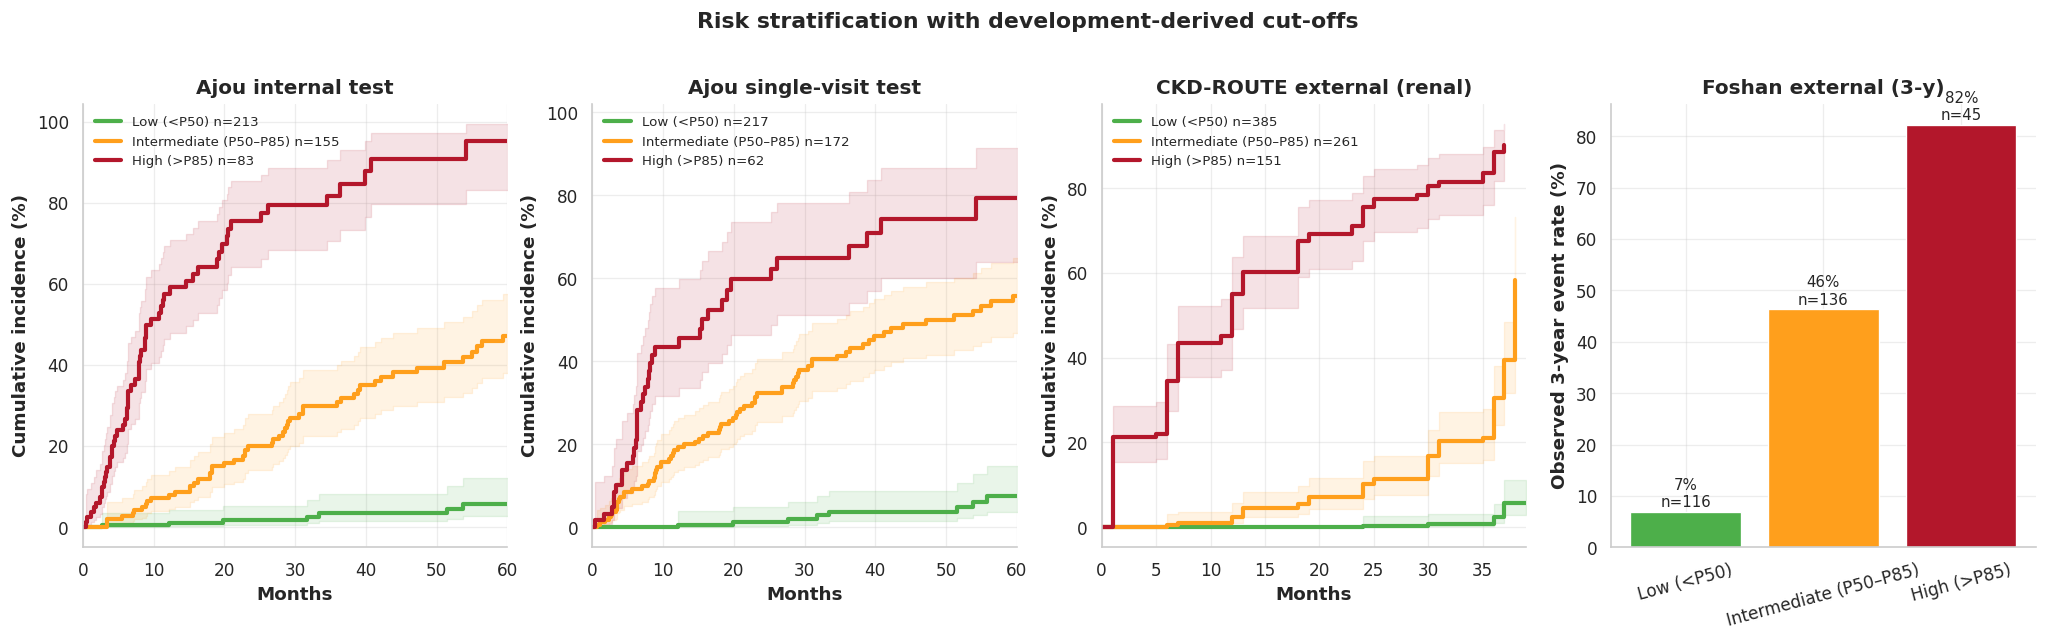

,cohort,group,n,risk36 %
0,Ajou internal test,Low (<P50),213,3.4
1,Ajou internal test,Intermediate (P50–P85),155,30.9
2,Ajou internal test,High (>P85),83,81.8
3,Ajou single-visit test,Low (<P50),217,3.7
4,Ajou single-visit test,Intermediate (P50–P85),172,42.3
5,Ajou single-visit test,High (>P85),62,64.8
6,CKD-ROUTE external (renal),Low (<P50),385,2.3
7,CKD-ROUTE external (renal),Intermediate (P50–P85),261,30.5
8,CKD-ROUTE external (renal),High (>P85),151,88.7
9,Foshan external (3-y),Low (<P50),116,6.9


In [16]:
pt = risk_at(PA[('CKD-GraphSurv', 'train')]['cif'], TAU); c1, c2 = np.percentile(pt, [50, 85])
RG = {'Low (<P50)': '#4DAF4A', 'Intermediate (P50–P85)': '#FF9F1C', 'High (>P85)': '#B3172B'}; STRAT = []
fig, axs = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, s in zip(axs, ['test', 'test_sv', 'route', 'foshan']):
    p = risk_at(PA[('CKD-GraphSurv', s)]['cif'], TAU); grp = np.where(p > c2, 2, np.where(p > c1, 1, 0)); d = SP[s]
    if is_binary(s):
        r = [d['E'][grp == g].mean() * 100 if (grp == g).any() else 0 for g in range(3)]
        ax.bar(list(RG), r, color=list(RG.values()), edgecolor='white')
        for g, v in enumerate(r): ax.text(g, v + 1, f'{v:.0f}%\nn={(grp == g).sum()}', ha='center', fontsize=9); STRAT.append({'cohort': COHORTS[s], 'group': list(RG)[g], 'n': int((grp == g).sum()), 'risk36 %': round(v, 1)})
        ax.set_ylabel('Observed 3-year event rate (%)'); ax.tick_params(axis='x', rotation=15)
    else:
        for g, (gl, c) in enumerate(RG.items()):
            sel = grp == g
            if sel.sum() < 3: continue
            km = KaplanMeierFitter().fit(d['Th'][sel], d['E'][sel]); x = km.cumulative_density_.index; yv = km.cumulative_density_.values[:, 0] * 100
            ax.step(x, yv, where='post', color=c, lw=2.5, label=f'{gl} n={sel.sum()}')
            ax.fill_between(x, km.confidence_interval_cumulative_density_.values[:, 0] * 100, km.confidence_interval_cumulative_density_.values[:, 1] * 100, step='post', color=c, alpha=0.12)
            STRAT.append({'cohort': COHORTS[s], 'group': gl, 'n': int(sel.sum()), 'risk36 %': round(km_at(d['Th'][sel], d['E'][sel], 36) * 100, 1)})
        ax.set_xlim(0, 60 if s != 'route' else 39); ax.set_xlabel('Months'); ax.set_ylabel('Cumulative incidence (%)'); ax.legend(fontsize=8)
    ax.set_title(COHORTS[s])
fig.suptitle('Risk stratification with development-derived cut-offs', fontweight='bold', y=1.04); save(fig, 'S13_risk_strata')
STRAT = pd.DataFrame(STRAT); STRAT.to_csv(RES/'risk_strata.csv', index=False); display(STRAT)

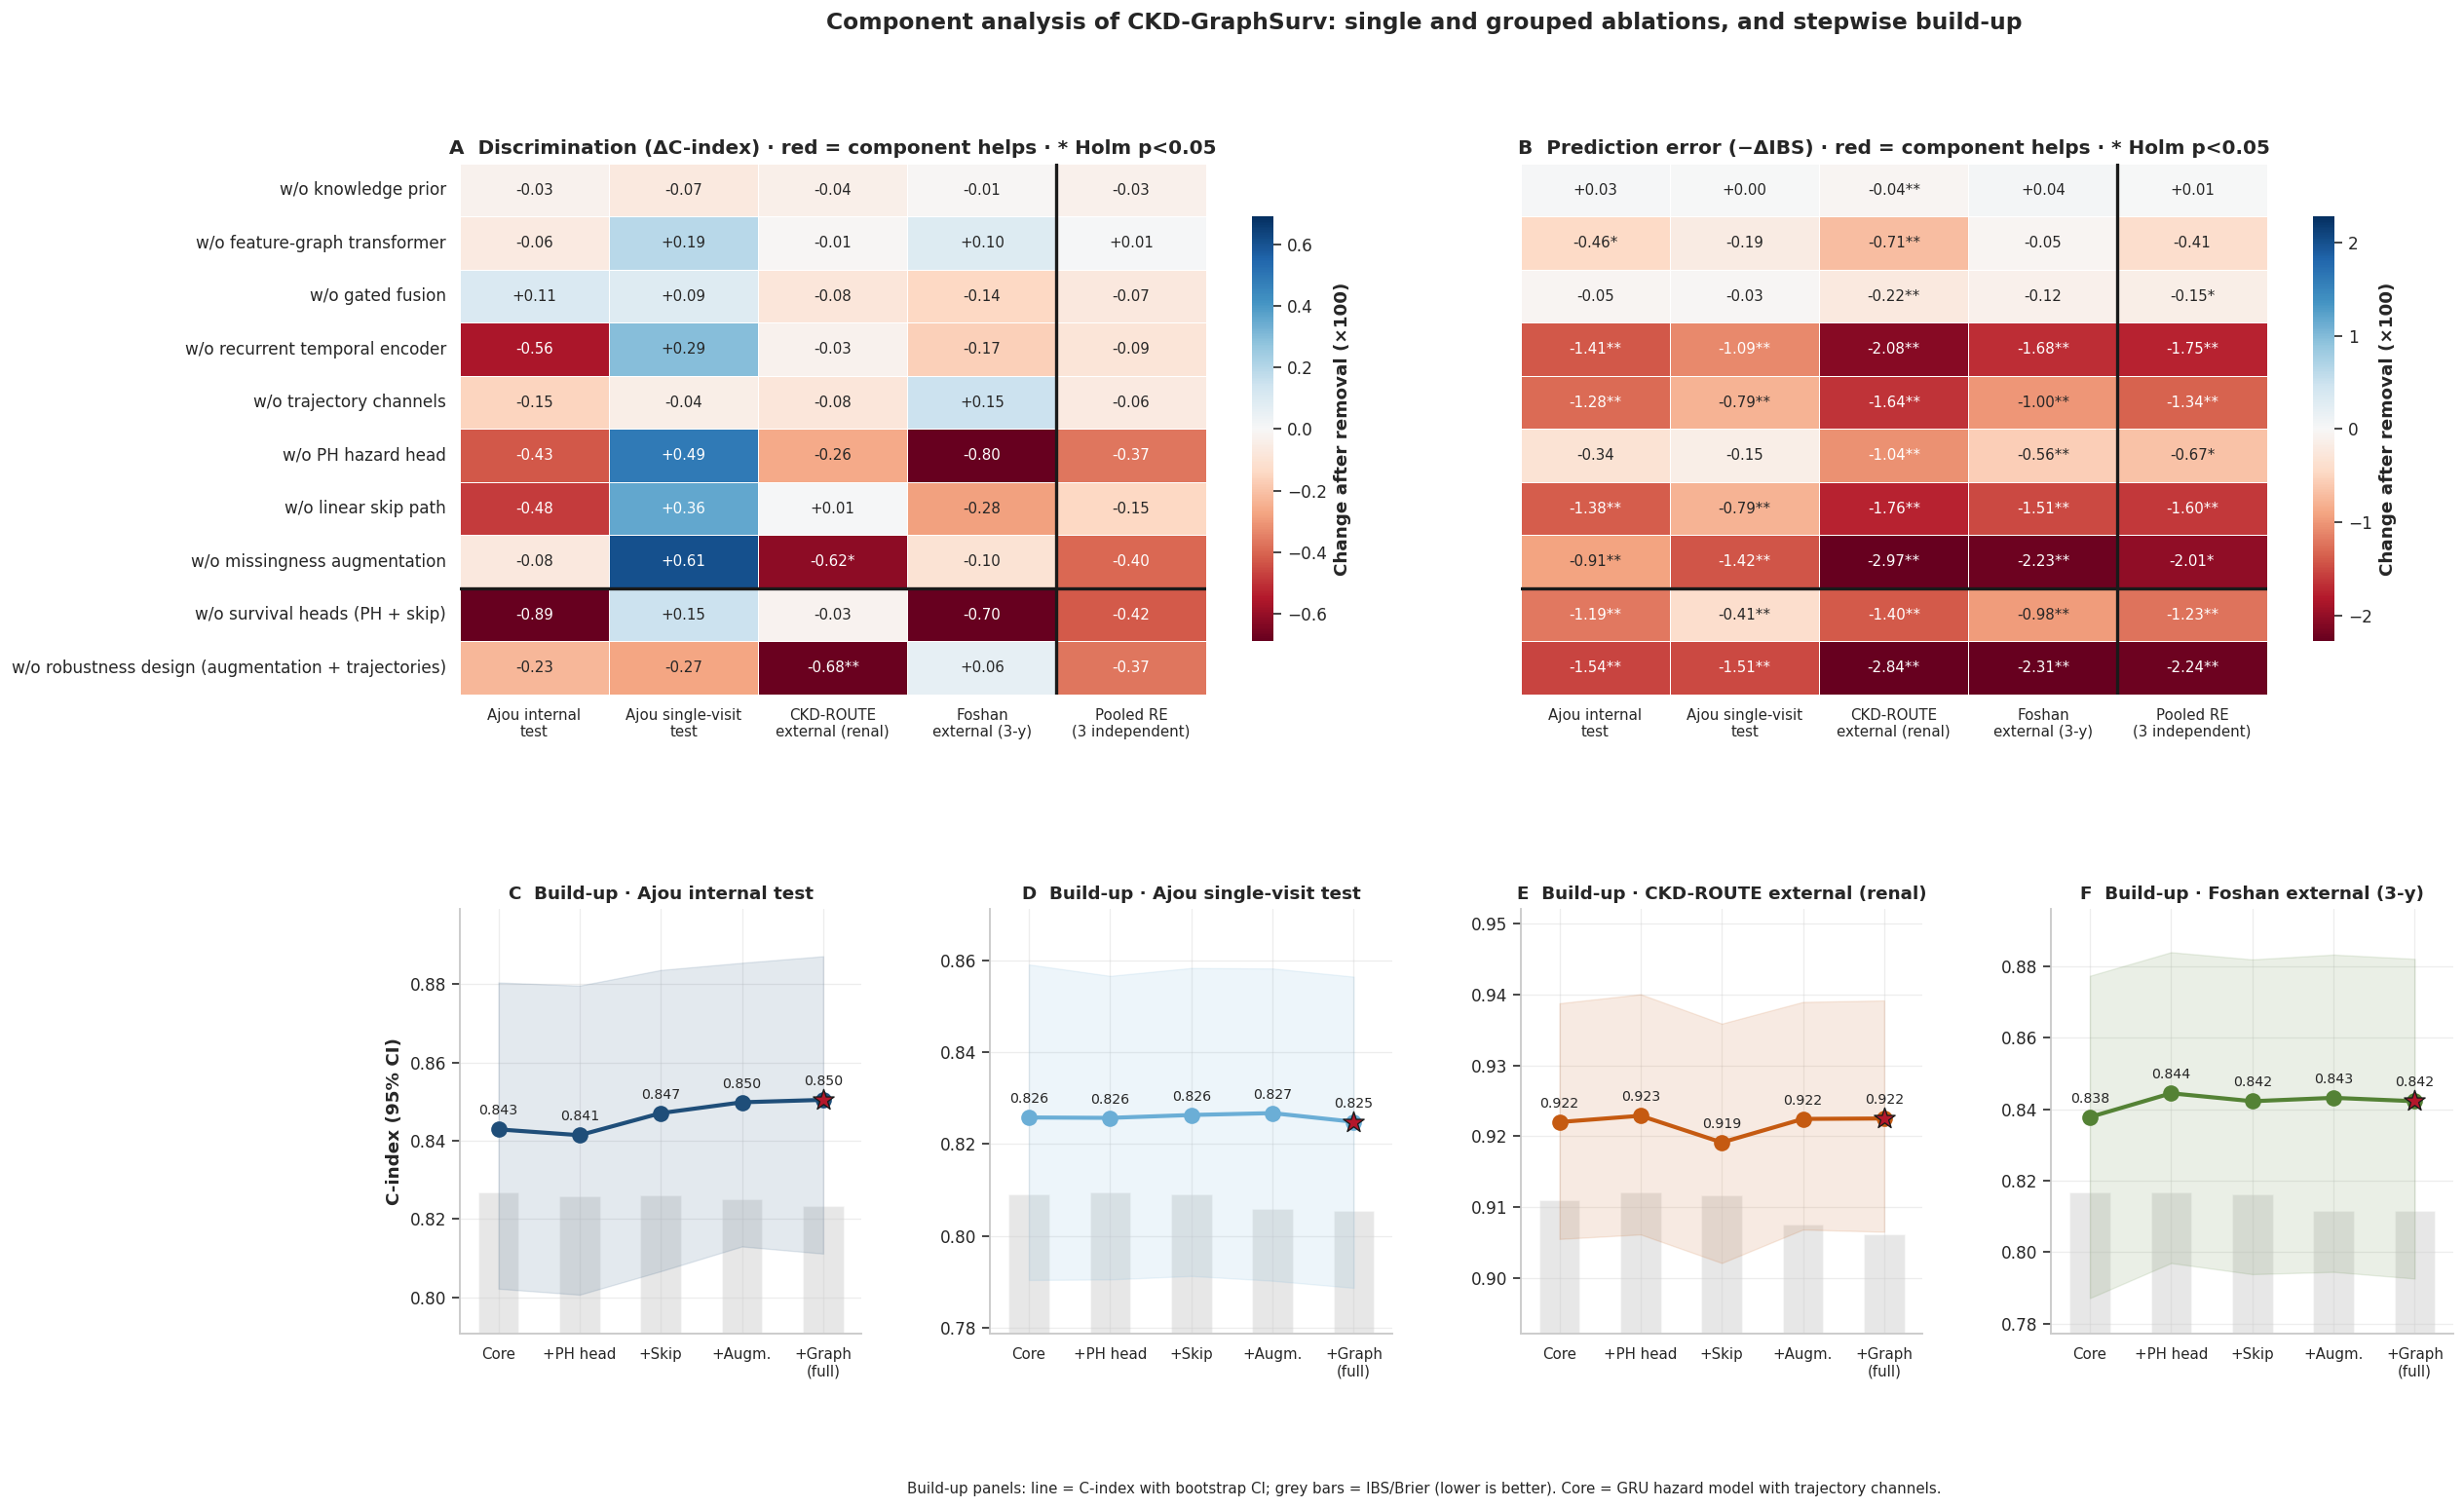

cohort                                                                       test                test_sv                  route                 foshan                 pooled
metric  variant                                                                                                                                                              
C-index Step 0 · GRU hazard core                             -0.75 (-1.60, +0.06)   +0.09 (-0.35, +0.67)   -0.05 (-0.29, +0.19)   -0.44 (-1.09, +0.18)   -0.26 (-0.65, +0.13)
        Step 1 · + PH hazard head                            -0.90 (-1.76, -0.16)   +0.09 (-0.27, +0.48)   +0.04 (-0.17, +0.27)   +0.22 (-0.13, +0.61)   -0.06 (-0.48, +0.35)
        Step 2 · + linear skip path                          -0.34 (-1.17, +0.44)   +0.15 (-0.32, +0.61)   -0.34 (-0.56, -0.12)   -0.00 (-0.56, +0.56)   -0.30 (-0.50, -0.09)
        Step 3 · + missingness augmentation                  -0.06 (-0.58, +0.51)   +0.19 (-0.07, +0.43)   -0.01 (-0.16, +0.14)   +0.10 (-0.29, +0.42)   +0.01 (-0.12, +0.13)
        w/o PH hazard head                                   -0.43 (-1.19, +0.31)   +0.49 (+0.08, +1.03)   -0.26 (-0.61, +0.01)   -0.80 (-1.54, -0.26)   -0.37 (-0.65, -0.09)
        w/o feature-graph transformer                        -0.06 (-0.58, +0.51)   +0.19 (-0.07, +0.43)   -0.01 (-0.16, +0.14)   +0.10 (-0.29, +0.42)   +0.01 (-0.12, +0.13)
        w/o gated fusion                                     +0.11 (-0.35, +0.59)   +0.09 (-0.18, +0.34)   -0.08 (-0.23, +0.07)   -0.14 (-0.48, +0.20)   -0.07 (-0.21, +0.07)
        w/o knowledge prior                                  -0.03 (-0.17, +0.07)   -0.07 (-0.16, +0.03)   -0.04 (-0.10, +0.01)   -0.01 (-0.11, +0.11)   -0.03 (-0.08, +0.01)
        w/o linear skip path                                 -0.48 (-1.05, +0.11)   +0.36 (+0.06, +0.78)   +0.01 (-0.23, +0.22)   -0.28 (-0.75, +0.19)   -0.15 (-0.42, +0.13)
        w/o missingness augmentation                         -0.08 (-0.72, +0.59)   +0.61 (-0.38, +1.41)  -0.62 (-1.03, -0.18)*   -0.10 (-1.04, +0.80)   -0.40 (-0.77, -0.02)
        w/o recurrent temporal encoder                       -0.56 (-1.36, +0.25)   +0.29 (-0.10, +0.67)   -0.03 (-0.28, +0.17)   -0.17 (-0.54, +0.25)   -0.09 (-0.29, +0.11)
        w/o robustness design (augmentation + trajector...   -0.23 (-1.65, +0.91)   -0.27 (-0.77, +0.22)  -0.68 (-1.02, -0.31)*   +0.06 (-0.61, +0.66)   -0.37 (-0.92, +0.17)
        w/o survival heads (PH + skip)                       -0.89 (-2.02, +0.07)   +0.15 (-0.32, +0.54)   -0.03 (-0.34, +0.22)   -0.70 (-1.30, -0.14)   -0.42 (-1.00, +0.15)
        w/o trajectory channels                              -0.15 (-1.77, +1.19)   -0.04 (-0.36, +0.28)   -0.08 (-0.23, +0.08)   +0.15 (-0.35, +0.57)   -0.06 (-0.20, +0.08)
IBS     Step 0 · GRU hazard core                             -0.92 (-1.41, -0.44)   -1.42 (-2.06, -0.84)   -2.58 (-3.27, -1.96)   -2.54 (-3.25, -1.60)   -1.99 (-3.17, -0.80)
        Step 1 · + PH hazard head                            -0.68 (-1.05, -0.35)   -1.57 (-2.29, -0.96)   -3.15 (-3.93, -2.47)   -2.52 (-3.25, -1.51)   -2.09 (-3.84, -0.34)
        Step 2 · + linear skip path                          -0.75 (-1.10, -0.41)   -1.42 (-2.08, -0.91)   -2.91 (-3.59, -2.30)   -2.25 (-2.92, -1.33)   -1.95 (-3.44, -0.46)
        Step 3 · + missingness augmentation                  -0.46 (-0.73, -0.13)   -0.19 (-0.35, -0.04)   -0.71 (-0.90, -0.55)   -0.05 (-0.27, +0.23)   -0.41 (-0.83, +0.01)
        w/o PH hazard head                                   -0.34 (-0.76, +0.03)   -0.15 (-0.33, +0.02)  -1.04 (-1.30, -0.82)*  -0.56 (-0.85, -0.23)*  -0.67 (-1.10, -0.24)*
        w/o feature-graph transformer                       -0.46 (-0.73, -0.13)*   -0.19 (-0.35, -0.04)  -0.71 (-0.90, -0.55)*   -0.05 (-0.27, +0.23)   -0.41 (-0.83, +0.01)
        w/o gated fusion                                     -0.05 (-0.23, +0.10)   -0.03 (-0.12, +0.05)  -0.22 (-0.29, -0.16)*   -0.12 (-0.26, +0.03)  -0.15 (-0.25, -0.04)

In [17]:
ABL_SHOW = list(ABL) + list(ABL_GROUP); ABL_COLS = MAIN_C + ['pooled']; ab = []
for k in ABL_ALL:
    v = ABL_KEY[k]
    for met in ['C-index', 'IBS']:
        ests, ses = [], []
        for s in MAIN_C:
            if met == 'IBS': need_ext(v, s, with_nb=False); need_ext('CKD-GraphSurv', s)
            est, dv = paired(v, 'CKD-GraphSurv', s, met); est, dv = (est, dv) if met == 'C-index' else (-est, -dv); se, p = wald(est, dv)
            ab.append({'variant': k, 'metric': met, 'cohort': s, 'Δ': est, 'lo': np.nanpercentile(dv, 2.5), 'hi': np.nanpercentile(dv, 97.5), 'p': p,
                       'value': c_point(v, s) if met == 'C-index' else EXT[(v, s)]['point'][0]})
            if s in INDEP: ests.append(est); ses.append(se)
        e, se = pool(ests, ses); ab.append({'variant': k, 'metric': met, 'cohort': 'pooled', 'Δ': e, 'lo': e - 1.96 * se, 'hi': e + 1.96 * se, 'p': 2 * (1 - norm.cdf(abs(e) / se)), 'value': np.nan})
AB = pd.DataFrame(ab)
for (met, s), g in AB[AB.variant.isin(ABL_SHOW)].groupby(['metric', 'cohort']): AB.loc[g.index, 'p Holm'] = holm(g['p'])
AB.to_csv(RES/'table3_ablation.csv', index=False)
CLAB = {**{s: COHORTS[s].replace(' external', '\nexternal').replace(' test', '\ntest') for s in MAIN_C}, 'pooled': 'Pooled RE\n(3 independent)'}

fig = plt.figure(figsize=(22, 13)); gs = fig.add_gridspec(2, 4, height_ratios=[1.25, 1], hspace=0.45, wspace=0.32)
for j, met in enumerate(['C-index', 'IBS']):
    ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2]); t = AB[(AB.metric == met) & AB.variant.isin(ABL_SHOW)]
    M = t.pivot(index='variant', columns='cohort', values='Δ').loc[ABL_SHOW, ABL_COLS] * 100; P = t.pivot(index='variant', columns='cohort', values='p Holm').loc[ABL_SHOW, ABL_COLS]
    ann = M.map(lambda v: f'{v:+.2f}') + P.map(lambda p: '**' if p < 0.01 else ('*' if p < 0.05 else ''))
    lim = max(0.3, np.nanpercentile(np.abs(M.values), 95)); sns.heatmap(M, ax=ax, cmap='RdBu', center=0, vmin=-lim, vmax=lim, annot=ann, fmt='', annot_kws={'fontsize': 9},
                                                                       linewidths=0.6, linecolor='white', cbar_kws={'label': 'Change after removal (×100)', 'shrink': 0.8})
    ax.axhline(len(ABL), color='k', lw=2); ax.axvline(len(MAIN_C), color='k', lw=2); ax.set_xticklabels([CLAB[c] for c in ABL_COLS], rotation=0, fontsize=9); ax.set_ylabel(''); ax.set_xlabel('')
    if j: ax.set_yticklabels([])
    ax.set_title(f"{'A' if j == 0 else 'B'}  {'Discrimination (ΔC-index)' if j == 0 else 'Prediction error (−ΔIBS)'} · red = component helps · * Holm p<0.05")
steps = list(BUILD) + ['Full CKD-GraphSurv']; skey = [ABL_KEY[k] for k in BUILD] + ['CKD-GraphSurv']
for j, s in enumerate(MAIN_C):
    ax = fig.add_subplot(gs[1, j]); c = np.array([c_point(v, s) for v in skey]); b = [ci(BOOT[(v, s)][:, 0]) for v in skey]
    ax.fill_between(range(len(skey)), [x[0] for x in b], [x[1] for x in b], color=COH_COL[s], alpha=0.12)
    ax.plot(range(len(skey)), c, marker='o', ms=9, lw=2.5, color=COH_COL[s]); ax.scatter(len(skey) - 1, c[-1], s=180, marker='*', color=PAL['CKD-GraphSurv'], edgecolor='k', zorder=5)
    for x_, v_ in enumerate(c): ax.annotate(f'{v_:.3f}', (x_, v_), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=8.5)
    ax2 = ax.twinx(); ib = [EXT[(v, s)]['point'][0] for v in skey]; ax2.bar(range(len(skey)), ib, color='#BBBBBB', alpha=0.35, width=0.5); ax2.set_ylim(0, max(ib) * 3); ax2.set_yticks([])
    lo_, hi_ = min(x[0] for x in b), max(x[1] for x in b); ax.set_ylim(lo_ - 0.01, hi_ + 0.012)
    ax.set_xticks(range(len(skey))); ax.set_xticklabels(['Core', '+PH head', '+Skip', '+Augm.', '+Graph\n(full)'], fontsize=9); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_title(f"{'CDEF'[j]}  Build-up · {COHORTS[s]}", fontsize=11); ax.set_ylabel('C-index (95% CI)' if j == 0 else '')
fig.text(0.5, 0.005, 'Build-up panels: line = C-index with bootstrap CI; grey bars = IBS/Brier (lower is better). Core = GRU hazard model with trajectory channels.', ha='center', fontsize=9)
fig.suptitle('Component analysis of CKD-GraphSurv: single and grouped ablations, and stepwise build-up', fontweight='bold', fontsize=14, y=0.98); save(fig, 'S14_ablation')
TAB3 = AB[AB.variant.isin(ABL_SHOW + list(BUILD))].assign(cell=lambda t: [f"{d*100:+.2f} ({l*100:+.2f}, {h*100:+.2f}){'*' if p < .05 else ''}" for d, l, h, p in zip(t['Δ'], t.lo, t.hi, t['p Holm'].fillna(1))])
TAB3 = TAB3.pivot_table(index=['metric', 'variant'], columns='cohort', values='cell', aggfunc='first')[ABL_COLS]; TAB3.to_csv(RES/'table3_ablation_formatted.csv'); display(TAB3)

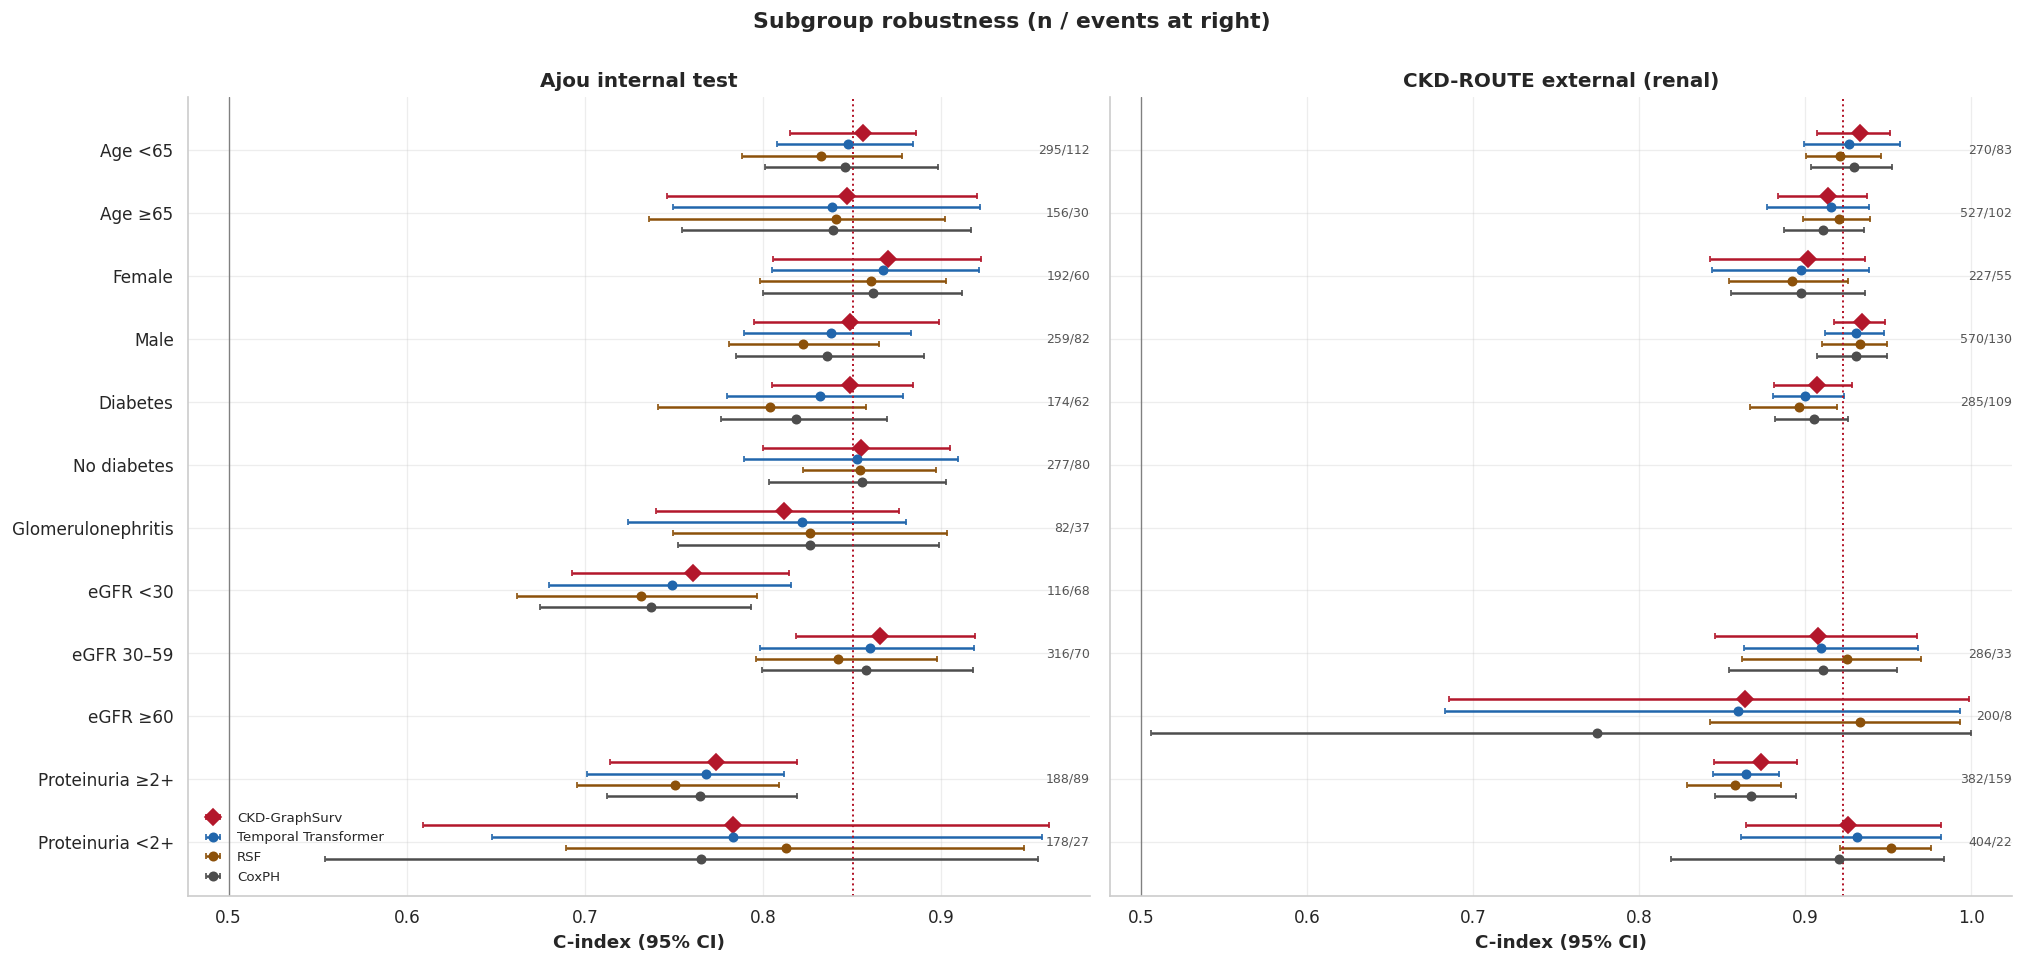

In [18]:
SUBG = {'Age <65': lambda m: m.age < 65, 'Age ≥65': lambda m: m.age >= 65, 'Female': lambda m: m.female == 1, 'Male': lambda m: m.female == 0,
        'Diabetes': lambda m: m.dm == 1, 'No diabetes': lambda m: m.dm == 0, 'Glomerulonephritis': lambda m: m.gn == 1,
        'eGFR <30': lambda m: m.base_egfr < 30, 'eGFR 30–59': lambda m: (m.base_egfr >= 30) & (m.base_egfr < 60), 'eGFR ≥60': lambda m: m.base_egfr >= 60,
        'Proteinuria ≥2+': lambda m: m.prot >= 2, 'Proteinuria <2+': lambda m: m.prot < 2}
sr = []; rg = np.random.default_rng(7)
for s in ['test', 'route']:
    d = SP[s]; mt = d['meta']
    for g, fn in SUBG.items():
        sel = fn(mt).fillna(False).values
        if d['E'][sel].sum() < 5 or sel.sum() < 30: continue
        for m in ['CKD-GraphSurv', 'Temporal Transformer', 'RSF', 'CoxPH']:
            cif = PA[(m, s)]['cif'][sel]; sub = {'Th': d['Th'][sel], 'E': d['E'][sel]}; bs_ = []
            try: c = disc(cif, sub, s)[0]
            except Exception: continue
            for _ in range(100):
                ix = rg.integers(0, sel.sum(), sel.sum())
                try: bs_.append(disc(cif[ix], {'Th': sub['Th'][ix], 'E': sub['E'][ix]}, s)[0])
                except Exception: pass
            sr.append({'cohort': COHORTS[s], 'subgroup': g, 'model': m, 'n': int(sel.sum()), 'events': int(sub['E'].sum()), 'C': c, 'lo': np.nanpercentile(bs_, 2.5), 'hi': np.nanpercentile(bs_, 97.5)})
SR = pd.DataFrame(sr); SR.to_csv(RES/'subgroups.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(17, 8), sharey=True); order = [g for g in SUBG if g in set(SR.subgroup)]
for ax, s in zip(axs, ['test', 'route']):
    for k, (m, off) in enumerate([('CKD-GraphSurv', 0.27), ('Temporal Transformer', 0.09), ('RSF', -0.09), ('CoxPH', -0.27)]):
        t = SR[(SR.cohort == COHORTS[s]) & (SR.model == m)].set_index('subgroup').reindex(order); y = np.arange(len(order))[::-1] + off
        ax.errorbar(t.C, y, xerr=[t.C - t.lo, t.hi - t.C], fmt='D' if k == 0 else 'o', color=PAL[m], ms=7 if k == 0 else 5, capsize=2, lw=1.5, label=m)
    ov = MAIN[(MAIN.Cohort == COHORTS[s]) & (MAIN.Model == 'CKD-GraphSurv')]._c.values[0]; ax.axvline(ov, color=PAL['CKD-GraphSurv'], ls=':', lw=1.2); ax.axvline(0.5, color='grey', lw=0.8)
    ax.set_yticks(np.arange(len(order))[::-1]); ax.set_yticklabels(order); ax.set_title(COHORTS[s]); ax.set_xlabel('C-index (95% CI)')
    for yy, g in zip(np.arange(len(order))[::-1], order):
        r = SR[(SR.cohort == COHORTS[s]) & (SR.model == 'CKD-GraphSurv') & (SR.subgroup == g)]
        if len(r): ax.text(1.0, yy, f"{int(r.n.iloc[0]):,}/{int(r.events.iloc[0])}", transform=ax.get_yaxis_transform(), fontsize=7.5, va='center', ha='right', color='#555555')
axs[0].legend(loc='lower left', fontsize=8); fig.suptitle('Subgroup robustness (n / events at right)', fontweight='bold', y=1.0); fig.tight_layout(); save(fig, 'S15_subgroups')

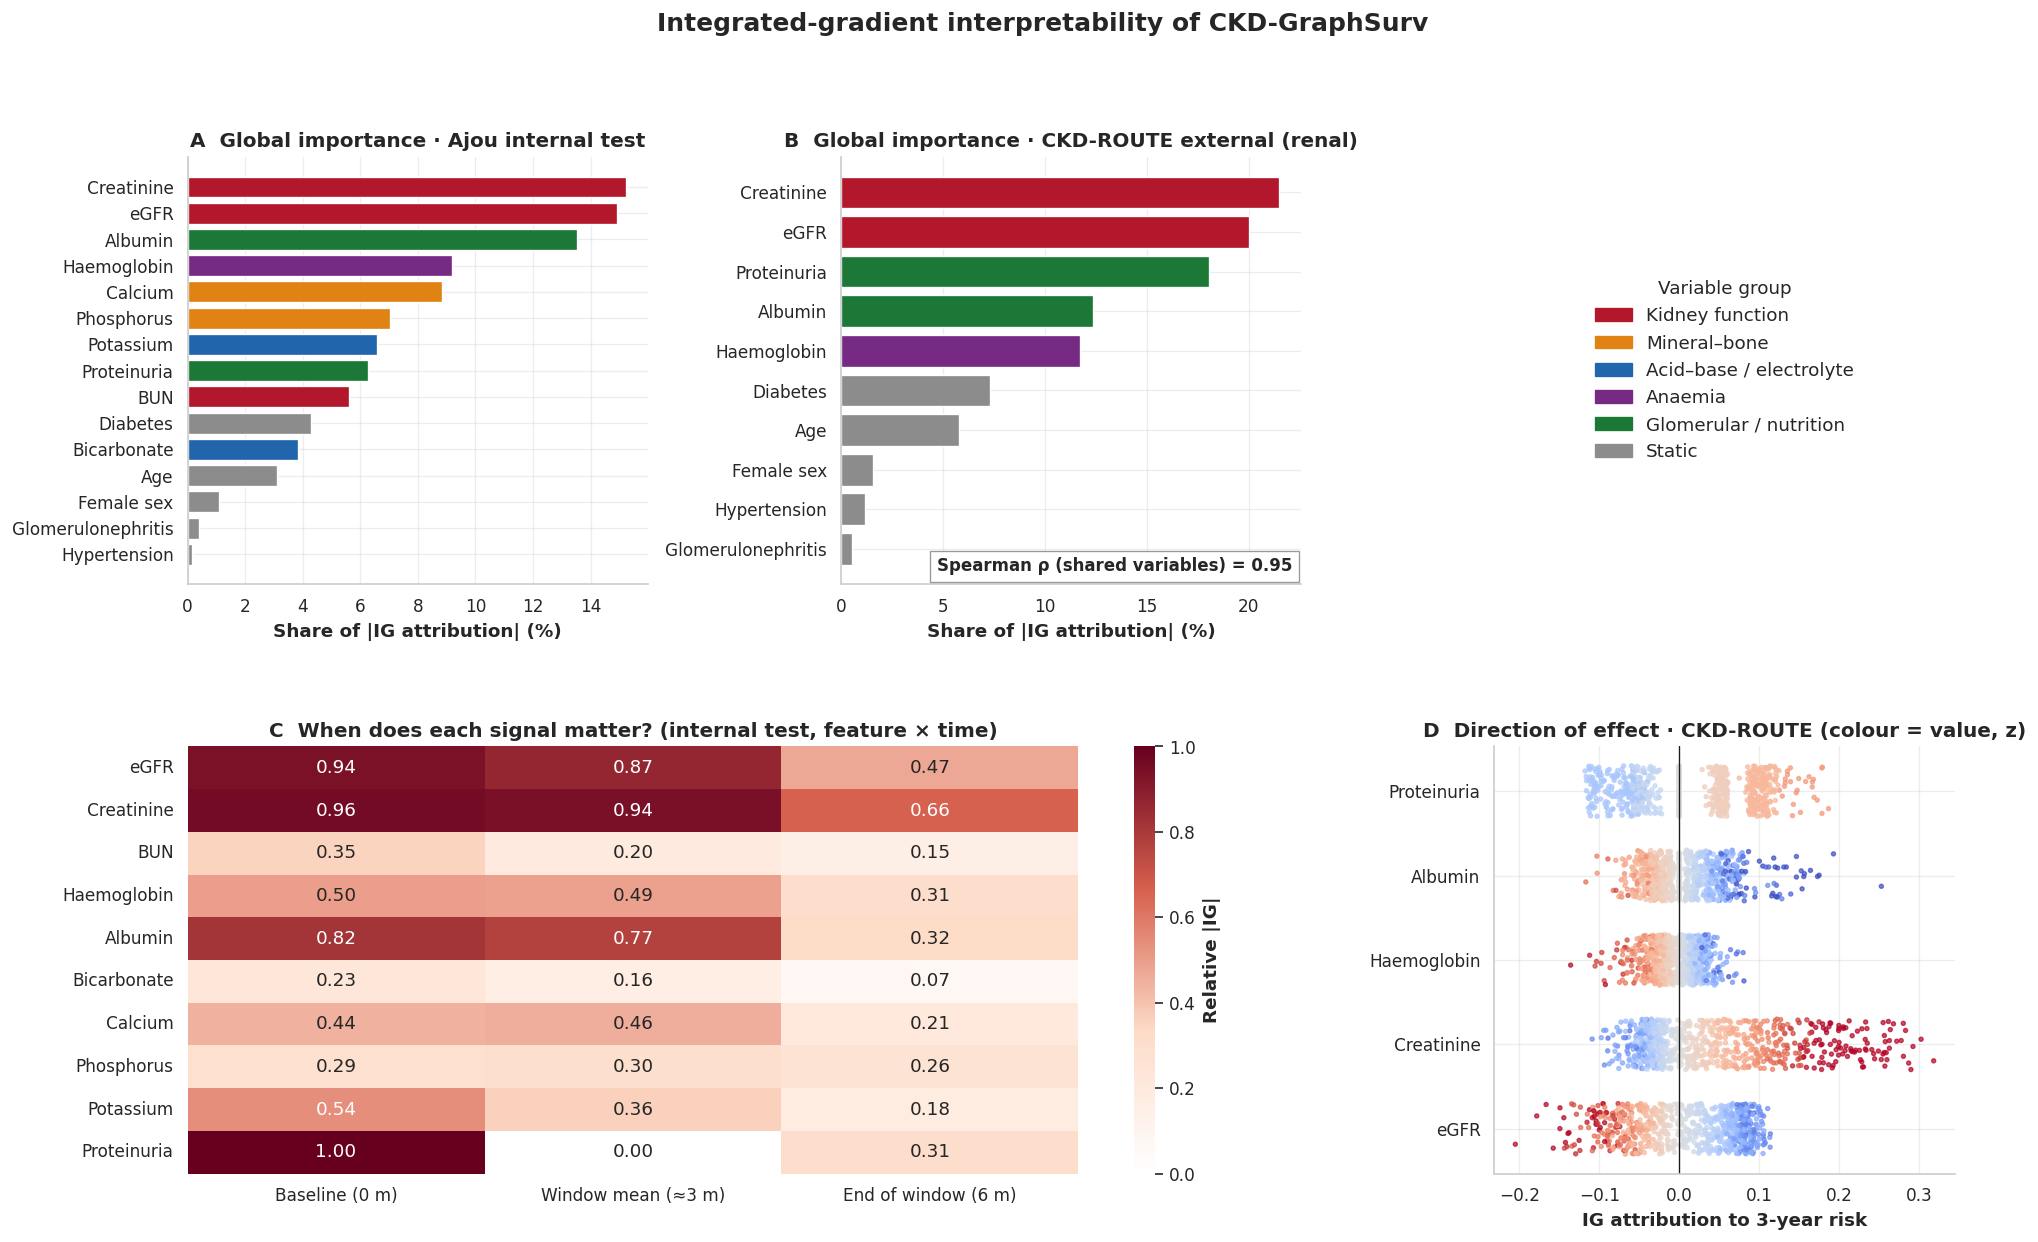

In [19]:
from captum.attr import IntegratedGradients
PM, _, _ = fit('CKD-GraphSurv', S0); IG_PATH = INT/f'ig_{VER}.pkl'
if not IG_PATH.exists():
    IGR = {}; ig = IntegratedGradients(lambda x, s: cif_t(PM({'X': x, 'S': s})['haz'])[:, TAU // BIN_M - 1])
    for s in ['test', 'route']:
        d = SP[s]; ix = np.arange(len(d['E']))
        x = torch.tensor(d['X'][ix], device=DEVICE, requires_grad=True); st = torch.tensor(d['S'][ix], device=DEVICE, requires_grad=True)
        with torch.backends.cudnn.flags(enabled=False):
            ax_, as_ = ig.attribute((x, st), baselines=(torch.zeros_like(x), torch.zeros_like(st)), n_steps=48, internal_batch_size=256)
        IGR[s] = {'ix': ix, 'x': ax_.detach().cpu().numpy(), 's': as_.detach().cpu().numpy()}
    pdump(IGR, IG_PATH)
IGR = pload(IG_PATH)
imp = {s: np.abs(IGR[s]['x']).sum(-1).sum(1).mean(0) for s in IGR}; imps = {s: np.abs(IGR[s]['s']).mean(0) for s in IGR}
names_all = [FLABEL[f] for f in LABS] + [SLABEL[s] for s in STATIC]; grp_all = [FGROUP[f] for f in LABS] + ['Static'] * len(STATIC); GP2 = {**GPAL, 'Static': '#8C8C8C'}
shared = [i for i, n in enumerate(LABS) if n in EXT_LABS] + list(range(F, F + S_DIM))
rho = spearmanr(np.r_[imp['test'], imps['test']][shared], np.r_[imp['route'], imps['route']][shared])[0]
fig = plt.figure(figsize=(19, 11)); gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.42)
for j, s in enumerate(['test', 'route']):
    ax = fig.add_subplot(gs[0, j]); v = np.r_[imp[s], imps[s]]; v = v / v.sum() * 100; o = [i for i in np.argsort(v) if v[i] > 0.05][-15:]
    ax.barh([names_all[i] for i in o], v[o], color=[GP2[grp_all[i]] for i in o], edgecolor='white'); ax.set_xlabel('Share of |IG attribution| (%)')
    ax.set_title(f"{'A' if j == 0 else 'B'}  Global importance · {COHORTS[s]}")
ax.text(0.98, 0.03, f'Spearman ρ (shared variables) = {rho:.2f}', transform=ax.transAxes, ha='right', fontsize=10, fontweight='bold', bbox=dict(fc='white', ec='#999999'))
ax = fig.add_subplot(gs[0, 2]); ax.axis('off'); ax.legend(handles=[mpl.patches.Patch(color=c, label=g) for g, c in GP2.items()], loc='center', title='Variable group', fontsize=11)
ax = fig.add_subplot(gs[1, :2]); hmv = np.abs(IGR['test']['x'][..., :2]).sum(-1).mean(0).T
sns.heatmap(hmv / hmv.max(), ax=ax, cmap=CMAP, annot=True, fmt='.2f', yticklabels=[FLABEL[f] for f in LABS], xticklabels=['Baseline (0 m)', 'Window mean (≈3 m)', 'End of window (6 m)'], cbar_kws={'label': 'Relative |IG|'})
ax.set_title('C  When does each signal matter? (internal test, feature × time)')
ax = fig.add_subplot(gs[1, 2]); top = [FI[f] for f in EXT_LABS]; sv = IGR['route']['x'][:, 0, :, 0]; xv = SP['route']['X'][:, 0, :, 0]
for k, fi in enumerate(top):
    yy = k + np.random.default_rng(k).uniform(-0.3, 0.3, len(sv)); ax.scatter(sv[:, fi], yy, c=np.clip(xv[:, fi], -2, 2), cmap='coolwarm', s=6, alpha=0.7, vmin=-2, vmax=2)
ax.set_yticks(range(len(top))); ax.set_yticklabels([FLABEL[LABS[i]] for i in top]); ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('IG attribution to 3-year risk'); ax.set_title('D  Direction of effect · CKD-ROUTE (colour = value, z)')
fig.suptitle('Integrated-gradient interpretability of CKD-GraphSurv', fontweight='bold', fontsize=15, y=0.99); save(fig, 'S16_ig')

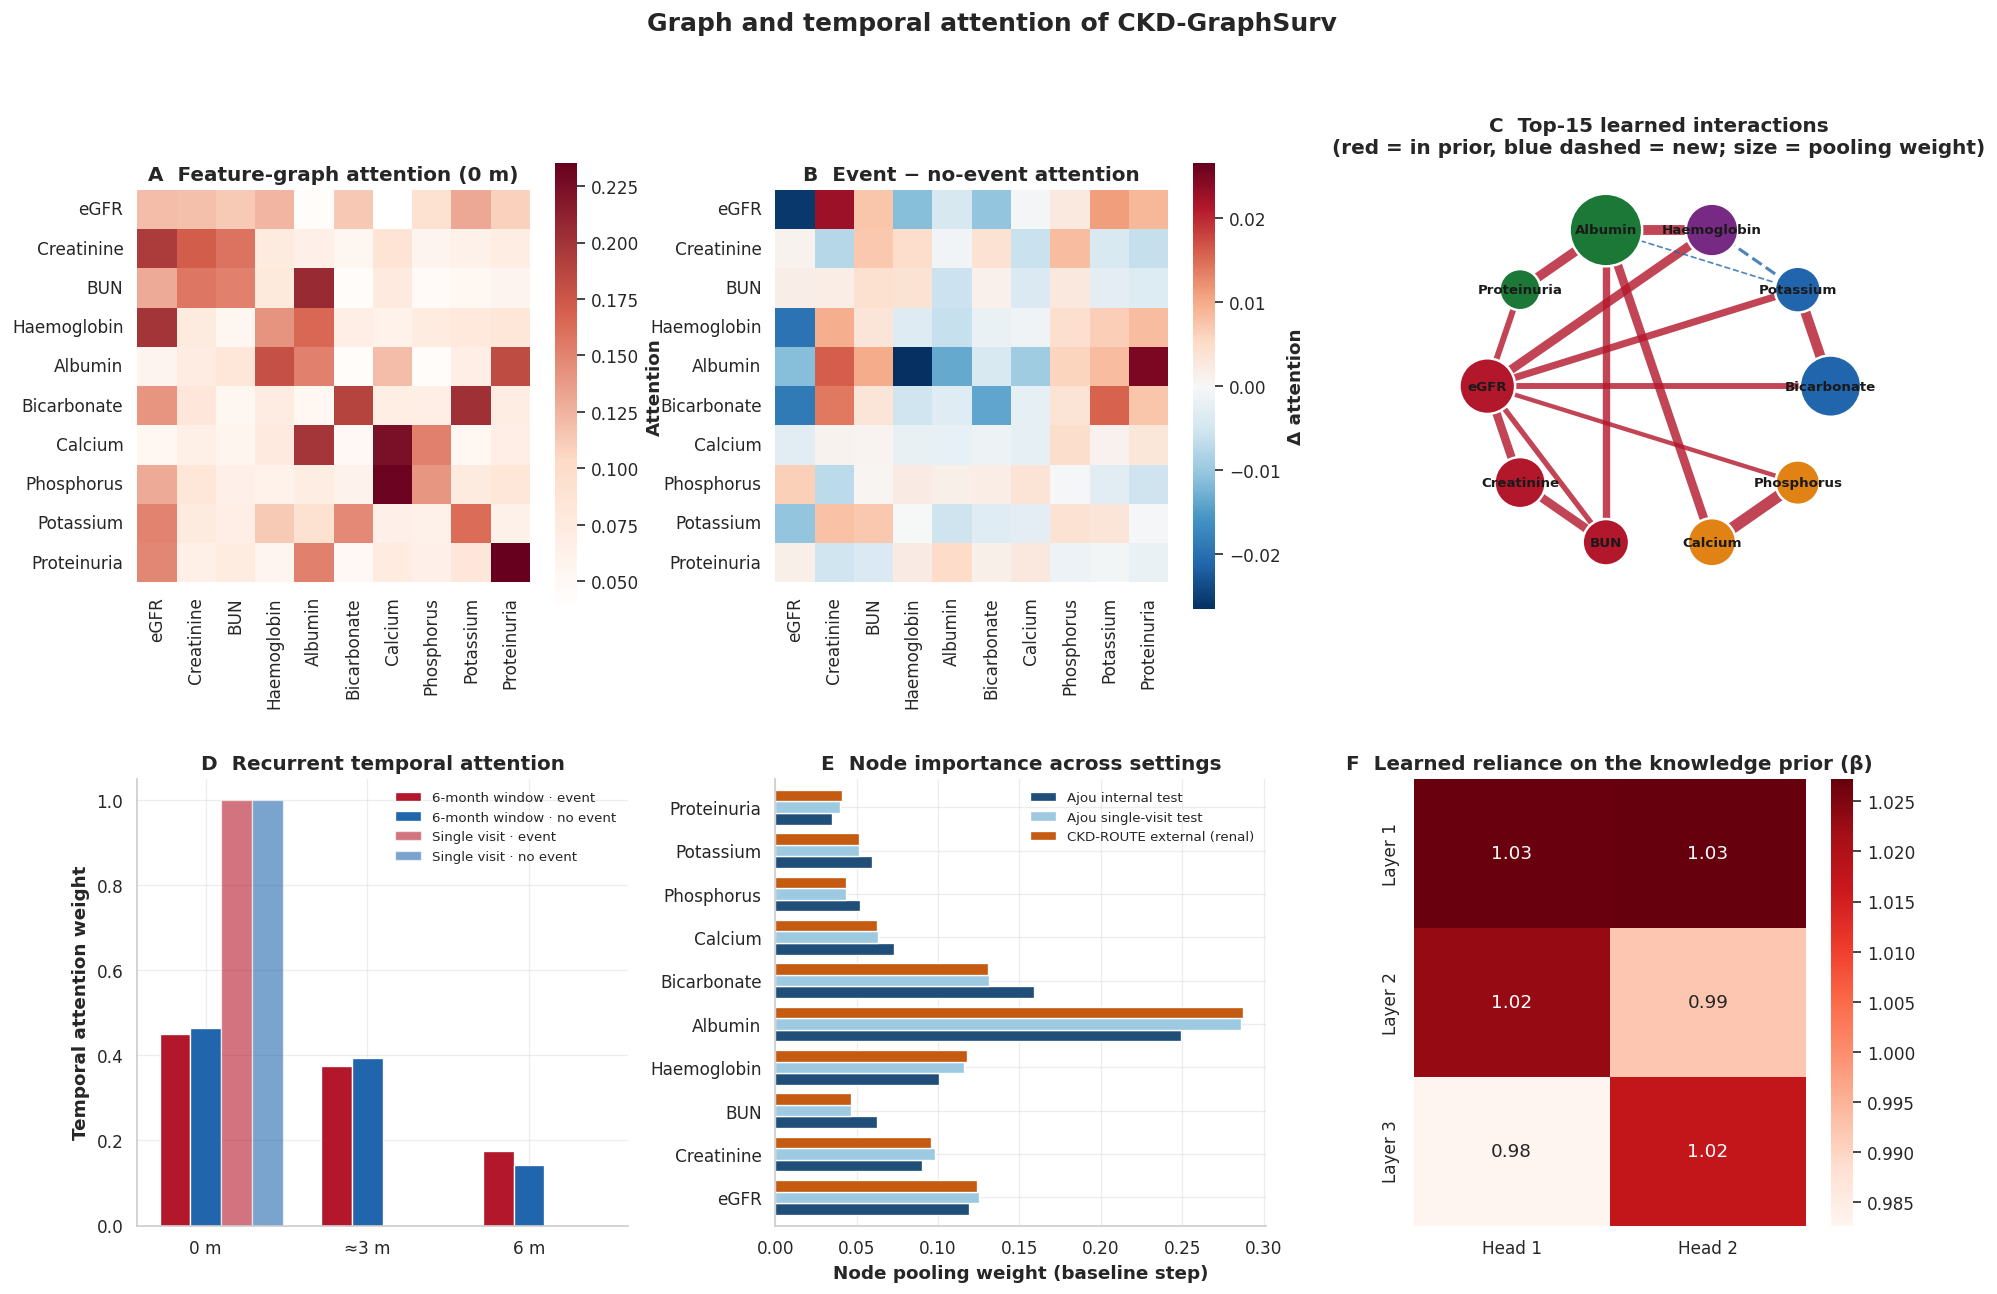

In [20]:
ATT_PATH = INT/f'attention_{VER}.pkl'
if not ATT_PATH.exists():
    ATT = {}; PM.set_keep(True)
    for s in ['test', 'test_sv', 'route']:
        d = SP[s]
        with torch.no_grad(): PM({k: torch.as_tensor(d[k]).to(DEVICE) for k in ['X', 'S']})
        B = len(d['E']); ATT[s] = {'graph': PM.gl[-1].last.mean(1).view(B, T_STEPS, F, F)[:, 0].cpu().numpy(), 'time': PM.time_w.cpu().numpy(),
                                   'node': PM.node_w[:, 0].cpu().numpy(), 'E': d['E']}
    PM.set_keep(False); pdump(ATT, ATT_PATH)
ATT = pload(ATT_PATH); lab = [FLABEL[f] for f in LABS]
fig = plt.figure(figsize=(19, 11.5)); gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.3)
ax = fig.add_subplot(gs[0, 0]); Gm = ATT['test']['graph'].mean(0); sns.heatmap(Gm, ax=ax, cmap=CMAP, xticklabels=lab, yticklabels=lab, square=True, cbar_kws={'label': 'Attention'}); ax.set_title('A  Feature-graph attention (0 m)')
ax = fig.add_subplot(gs[0, 1]); G_ = ATT['test']['graph']; e = ATT['test']['E'] == 1; dif = G_[e].mean(0) - G_[~e].mean(0); lim = np.abs(dif).max()
sns.heatmap(dif, ax=ax, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, xticklabels=lab, yticklabels=lab, square=True, cbar_kws={'label': 'Δ attention'}); ax.set_title('B  Event − no-event attention')
ax = fig.add_subplot(gs[0, 2]); W = (Gm + Gm.T) / 2; np.fill_diagonal(W, 0); Gg = nx.Graph(); thr = np.sort(W[np.triu_indices(F, 1)])[-16]
for i in range(F):
    for j in range(i + 1, F):
        if W[i, j] >= thr: Gg.add_edge(LABS[i], LABS[j], w=W[i, j], prior=PRIOR_NP[i, j] > 0)
pos = nx.circular_layout(sorted(LABS, key=lambda n: FGROUP[n])); ws = np.array([Gg[u][v]['w'] for u, v in Gg.edges])
nx.draw_networkx_edges(Gg, pos, ax=ax, width=1 + 6 * (ws - ws.min()) / (np.ptp(ws) + 1e-9), edge_color=['#B3172B' if Gg[u][v]['prior'] else '#2166AC' for u, v in Gg.edges], alpha=0.8,
                       style=['solid' if Gg[u][v]['prior'] else 'dashed' for u, v in Gg.edges])
nx.draw_networkx_nodes(Gg, pos, ax=ax, nodelist=LABS, node_color=[GPAL[FGROUP[n]] for n in LABS], node_size=[400 + 6000 * ATT['test']['node'][:, FI[n]].mean() for n in LABS], edgecolors='white', linewidths=1.5)
nx.draw_networkx_labels(Gg, pos, ax=ax, labels={n: FLABEL[n] for n in LABS}, font_size=8, font_weight='bold'); ax.axis('off')
ax.margins(0.15); ax.set_title('C  Top-15 learned interactions\n(red = in prior, blue dashed = new; size = pooling weight)')
ax = fig.add_subplot(gs[1, 0]); x = np.arange(T_STEPS); w = 0.38
for k, (s, lb) in enumerate([('test', '6-month window'), ('test_sv', 'Single visit')]):
    tw = ATT[s]['time']; e = ATT[s]['E'] == 1
    ax.bar(x + (k - 0.5) * w, tw[e].mean(0), w * 0.5, color=PAL['CKD-GraphSurv'], alpha=1 - 0.4 * k, label=f'{lb} · event'); ax.bar(x + (k - 0.5) * w + w * 0.5, tw[~e].mean(0), w * 0.5, color='#2166AC', alpha=1 - 0.4 * k, label=f'{lb} · no event')
ax.set_xticks(x); ax.set_xticklabels(['0 m', '≈3 m', '6 m']); ax.set_ylabel('Temporal attention weight'); ax.set_title('D  Recurrent temporal attention'); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 1]); nw = pd.DataFrame({COHORTS[s]: ATT[s]['node'].mean(0) for s in ['test', 'test_sv', 'route']}, index=lab)
nw.plot.barh(ax=ax, color=['#1F4E79', '#9ECAE1', '#C55A11'], width=0.8); ax.set_xlabel('Node pooling weight (baseline step)'); ax.set_title('E  Node importance across settings'); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 2]); bt = np.stack([l.beta.detach().cpu().numpy() for l in PM.gl]); sns.heatmap(bt, ax=ax, annot=True, fmt='.2f', cmap='Reds', xticklabels=[f'Head {i+1}' for i in range(bt.shape[1])], yticklabels=[f'Layer {i+1}' for i in range(bt.shape[0])])
ax.set_title('F  Learned reliance on the knowledge prior (β)')
fig.suptitle('Graph and temporal attention of CKD-GraphSurv', fontweight='bold', fontsize=15, y=0.99); save(fig, 'S17_attention')

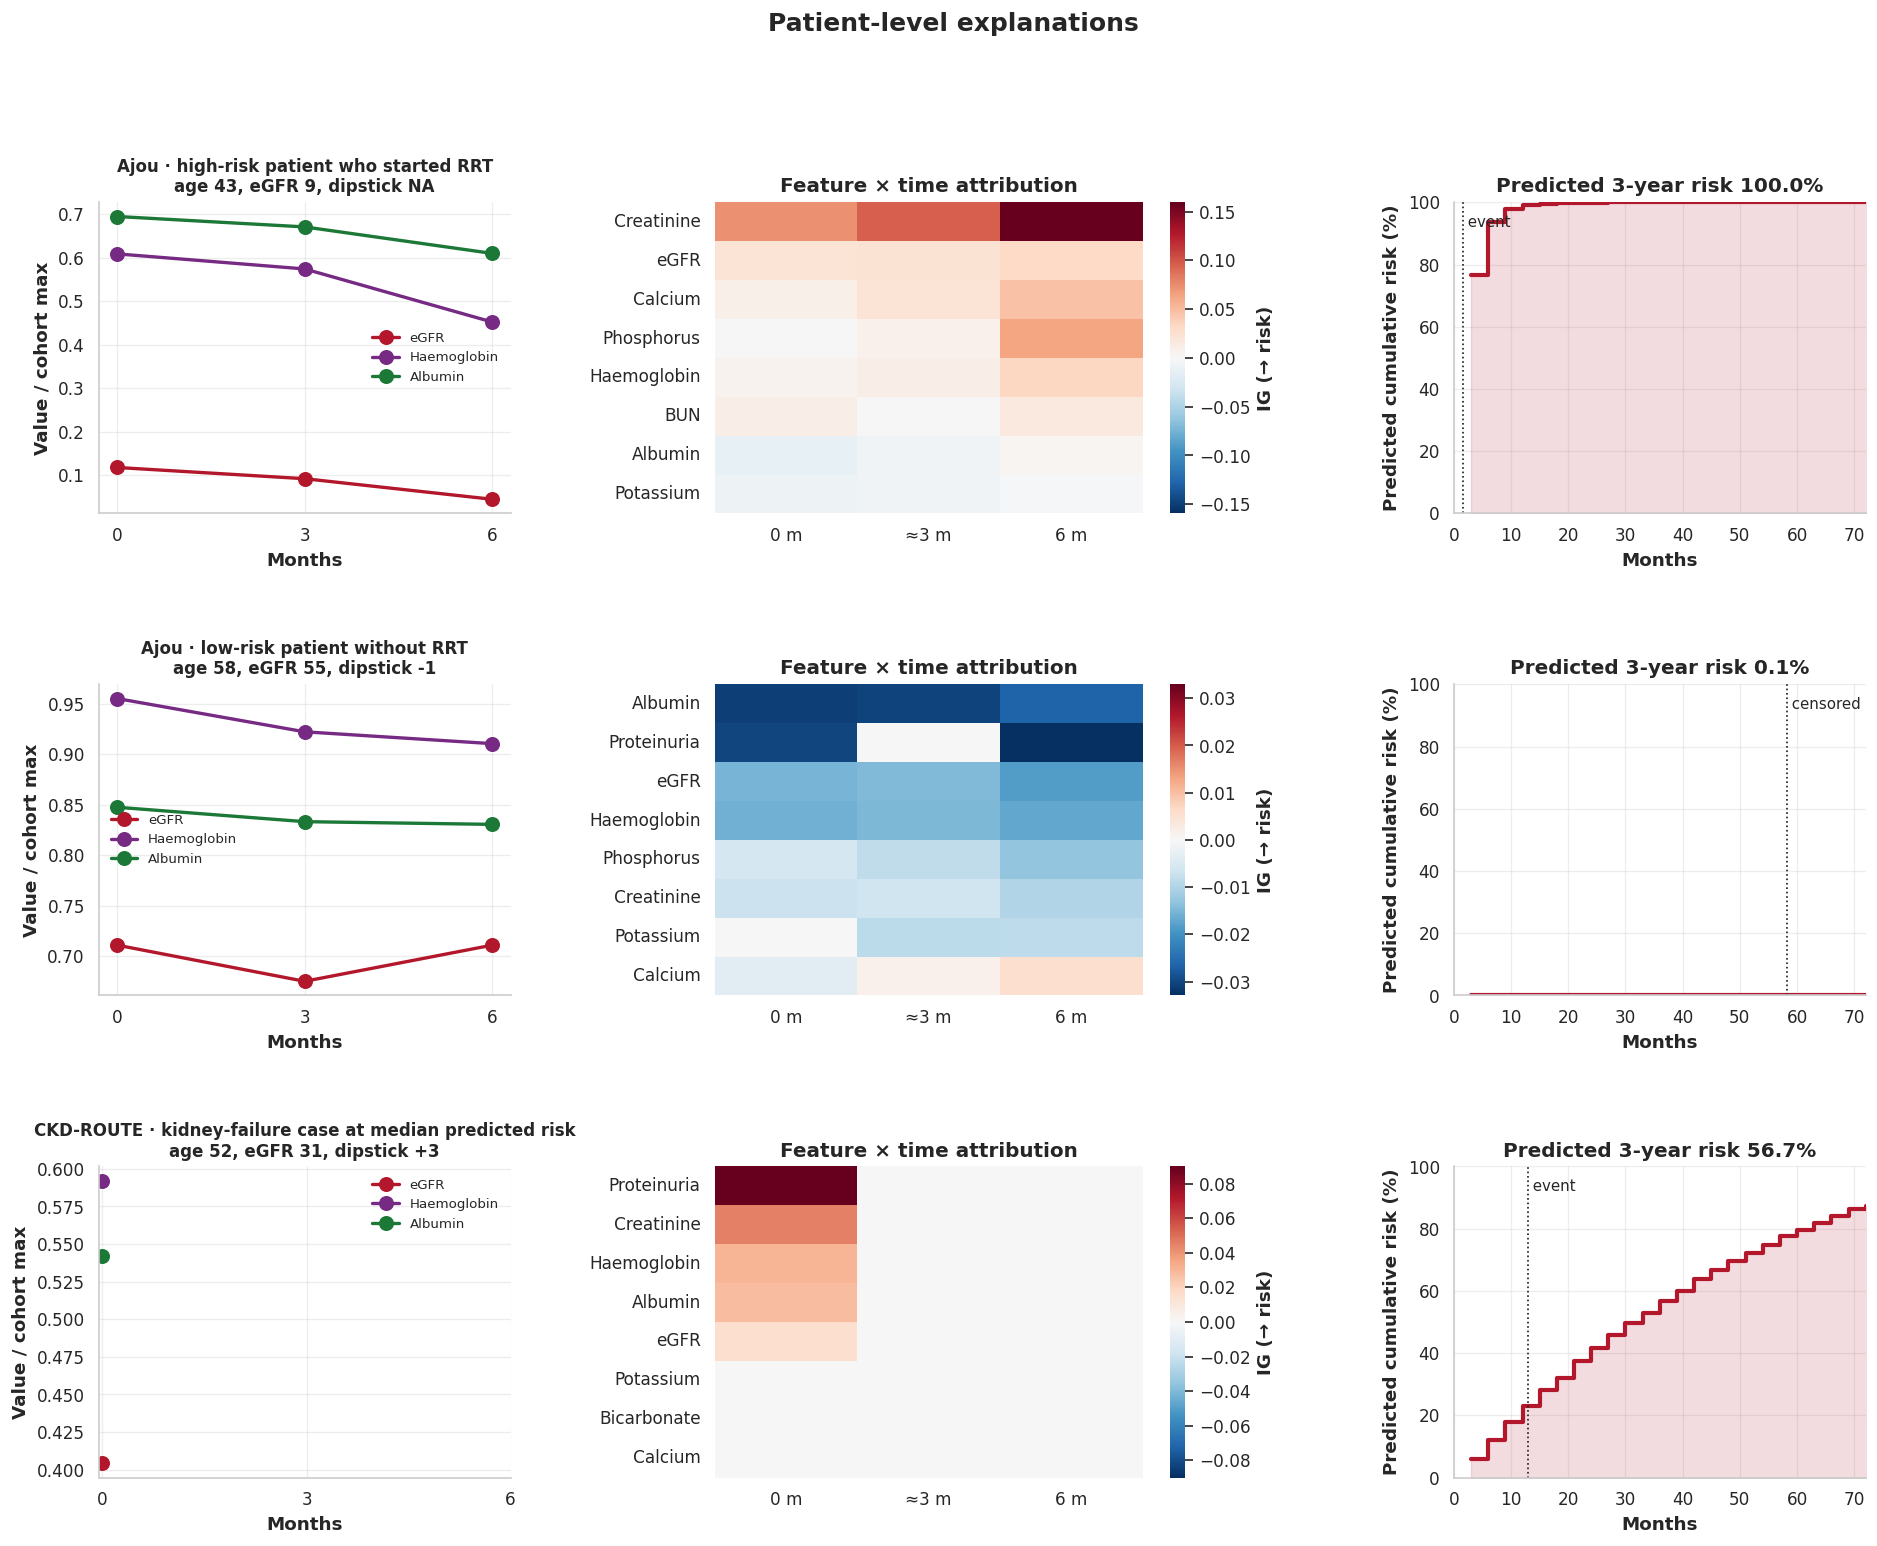

In [21]:
cases = []; d = SP['test']; r = risk_at(PA[('CKD-GraphSurv', 'test')]['cif'], TAU); ev = np.where(d['E'] == 1)[0]; ne = np.where(d['E'] == 0)[0]
cases += [('test', ev[np.argmax(r[ev])], 'Ajou · high-risk patient who started RRT'), ('test', ne[np.argmin(r[ne])], 'Ajou · low-risk patient without RRT')]
d2 = SP['route']; r2 = risk_at(PA[('CKD-GraphSurv', 'route')]['cif'], TAU); ev2 = np.where(d2['E'] == 1)[0]
if len(ev2): cases.append(('route', ev2[np.argsort(r2[ev2])[len(ev2) // 2]], 'CKD-ROUTE · kidney-failure case at median predicted risk'))
fig, axs = plt.subplots(len(cases), 3, figsize=(19, 4.6 * len(cases)), gridspec_kw={'width_ratios': [1, 1.3, 1], 'wspace': 0.45, 'hspace': 0.55})
for row, (s, i, ttl) in enumerate(cases):
    d = SP[s]; v = d['Vraw'][i]; ax = axs[row, 0]; tt = T_POS
    for f, c in [('egfr', '#B3172B'), ('hemoglobin', '#762A83'), ('albumin', '#1B7837')]:
        y = v[:, FI[f]] / np.nanmax(np.abs(SP['train']['Vraw'][:, 0, FI[f]])); ax.plot(tt[~np.isnan(y)], y[~np.isnan(y)], 'o-', color=c, lw=2, ms=8, label=FLABEL[f])
    ax.set_xticks(tt); ax.set_xlabel('Months'); ax.set_ylabel('Value / cohort max'); ax.legend(fontsize=8)
    mt = d['meta'].iloc[i]; dip = 'NA' if np.isnan(mt.prot) else f'{mt.prot:+.0f}'; ax.set_title(f"{ttl}\nage {mt.age:.0f}, eGFR {mt.base_egfr:.0f}, dipstick {dip}", fontsize=10)
    ax = axs[row, 1]; at = IGR[s]['x'][i, ..., :2].sum(-1).T; o = np.argsort(np.abs(at).sum(1))[::-1][:8]; lim = np.abs(at[o]).max() + 1e-9
    sns.heatmap(at[o], ax=ax, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, yticklabels=[FLABEL[LABS[j]] for j in o], xticklabels=['0 m', '≈3 m', '6 m'], cbar_kws={'label': 'IG (→ risk)'}); ax.set_title('Feature × time attribution')
    ax = axs[row, 2]; cif = PA[('CKD-GraphSurv', s)]['cif'][i] * 100; ax.step(BIN_END, cif, where='post', color=PAL['CKD-GraphSurv'], lw=2.5); ax.fill_between(BIN_END, 0, cif, step='post', color=PAL['CKD-GraphSurv'], alpha=0.15)
    ax.axvline(d['Th'][i], color='k', ls=':', lw=1); ax.text(d['Th'][i], 0.92, ' event' if d['E'][i] else ' censored', fontsize=9, transform=ax.get_xaxis_transform())
    ax.set_xlim(0, 72); ax.set_ylim(0, 100); ax.set_xlabel('Months'); ax.set_ylabel('Predicted cumulative risk (%)'); ax.set_title(f'Predicted 3-year risk {risk_at(PA[("CKD-GraphSurv", s)]["cif"], TAU)[i]*100:.1f}%')
fig.suptitle('Patient-level explanations', fontweight='bold', fontsize=15, y=0.995); save(fig, 'S18_case_studies')

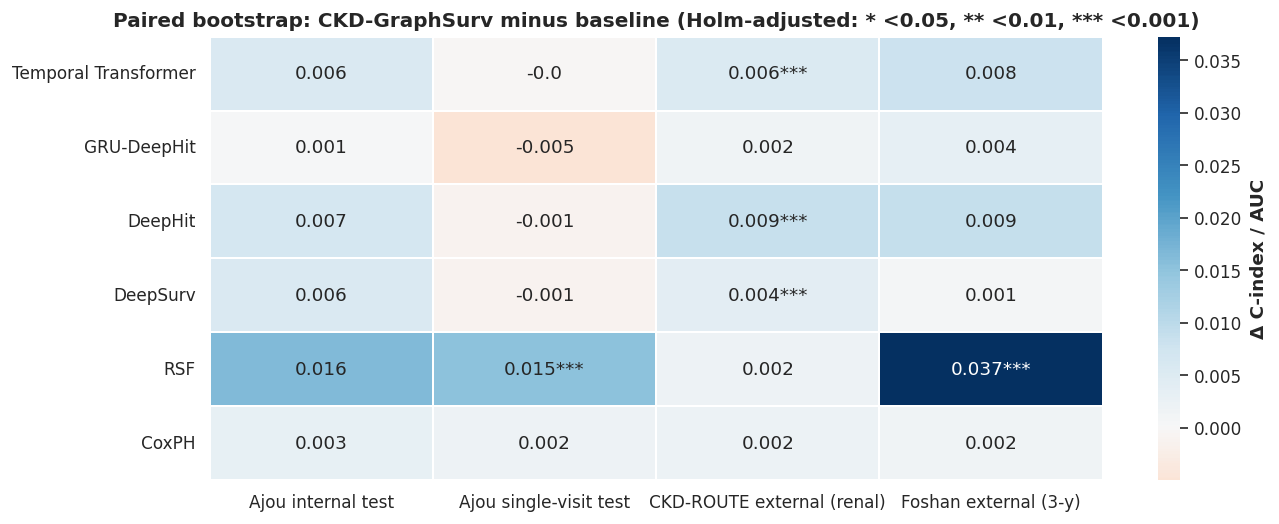

C-index         mean AUC             IBS        
                                                      mean     std     mean     std    mean     std
cohort                        model                                                                
Ajou internal test            CKD-GraphSurv         0.8504  0.0049   0.9024  0.0048  0.0857  0.0012
                              CoxPH                 0.8469  0.0000   0.9032  0.0000  0.0853  0.0000
                              DeepHit               0.8437  0.0028   0.8974  0.0044  0.0984  0.0025
                              DeepSurv              0.8442  0.0054   0.8977  0.0040  0.0860  0.0018
                              GRU-DeepHit           0.8495  0.0065   0.9017  0.0074  0.1050  0.0051
                              RSF                   0.8354  0.0017   0.8955  0.0014  0.0865  0.0005
                              Temporal Transformer  0.8450  0.0033   0.8966  0.0067  0.0936  0.0025
Ajou single-visit test        CKD-GraphSurv         0.8248  0.0010   0.8747  0.0020  0.1033  0.0033
                              CoxPH                 0.8226  0.0000   0.8741  0.0000  0.1117  0.0000
                              DeepHit               0.8261  0.0034   0.8772  0.0032  0.1155  0.0041
                              DeepSurv              0.8261  0.0019   0.8763  0.0036  0.1040  0.0039
                              GRU-DeepHit           0.8298  0.0017   0.8817  0.0016  0.1139  0.0045
                              RSF                   0.8092  0.0029   0.8680  0.0010  0.1036  0.0004
                              Temporal Transformer  0.8253  0.0026   0.8761  0.0019  0.1032  0.0027
CKD-ROUTE composite (n=1,138) CKD-GraphSurv         0.9167  0.0022   0.9379  0.0016  0.0820  0.0040
                              CoxPH                 0.9154  0.0000   0.9351  0.0000  0.0892  0.0000
                              DeepHit               0.9088  0.0020   0.9314  0.0017  0.1071  0.0069
                              DeepSurv              0.9135  0.0016   0.9352  0.0006  0.0848  0.0078
                              GRU-DeepHit           0.9154  0.0020   0.9369  0.0013  0.1065  0.0062
                              RSF                   0.9107  0.0006   0.9299  0.0010  0.0761  0.0008
                              Temporal Transformer  0.9115  0.0037   0.9329  0.0026  0.0888  0.0053
CKD-ROUTE external (renal)    CKD-GraphSurv         0.9225  0.0023   0.9452  0.0014  0.0749  0.0033
                              CoxPH                 0.9205  0.0000   0.9416  0.0000  0.0805  0.0000
                              DeepHit               0.9140  0.0019   0.9384  0.0016  0.0984  0.0063
                              DeepSurv              0.9188  0.0016   0.9427  0.0007  0.0775  0.0069
                              GRU-DeepHit           0.9208  0.0019   0.9430  0.0012  0.0983  0.0058
                              RSF                   0.9205  0.0010   0.9363  0.0012  0.0705  0.0007
                              Temporal Transformer  0.9171  0.0040   0.9398  0.0019  0.0817  0.0053
Foshan external (3-y)         CKD-GraphSurv         0.8422  0.0036   0.8422  0.0036  0.1669  0.0056
                              CoxPH                 0.8414  0.0000   0.8414  0.0000  0.1792  0.0000
                              DeepHit               0.8338  0.0047   0.8338  0.0047  0.1945  0.0082
                              DeepSurv              0.8415  0.0083   0.8415  0.0083  0.1695  0.0107
                              GRU-DeepHit           0.8390  0.0026   0.8390  0.0026  0.1938  0.0090
                              RSF                   0.8050  0.0038   0.8050  0.0038  0.1722  0.0023
                              Temporal Transformer  0.8341  0.0021   0.8341  0.0021  0.1782  0.0058

,cohort,baseline,metric,Δ (proposed − baseline),95% CI,p,p (Holm)
0,Ajou internal test,Temporal Transformer,C-index,0.0057,-0.002 to 0.016,0.2400,0.8400
1,Ajou internal test,Temporal Transformer,mean AUC,0.0061,-0.003 to 0.016,0.2100,1.0000
2,Ajou internal test,GRU-DeepHit,C-index,0.0005,-0.008 to 0.008,0.9000,1.0000
3,Ajou internal test,GRU-DeepHit,mean AUC,0.0004,-0.009 to 0.009,0.8700,1.0000
4,Ajou internal test,DeepHit,C-index,0.0065,-0.003 to 0.018,0.2000,0.8400
5,Ajou internal test,DeepHit,mean AUC,0.0048,-0.006 to 0.016,0.3500,1.0000
6,Ajou internal test,DeepSurv,C-index,0.0059,-0.003 to 0.013,0.1600,0.8400
7,Ajou internal test,DeepSurv,mean AUC,0.0045,-0.005 to 0.013,0.3200,1.0000
8,Ajou internal test,RSF,C-index,0.0163,-0.002 to 0.037,0.1400,0.8400
9,Ajou internal test,RSF,mean AUC,0.0081,-0.010 to 0.025,0.4300,1.0000


Figures: /content/drive/MyDrive/CKD_GraphSurv_Public/figures_v3
Tables: /content/drive/MyDrive/CKD_GraphSurv_Public/results_v3


In [22]:
st_rows = []
for s in MAIN_C:
    bp = BOOT[('CKD-GraphSurv', s)]
    for m in MODELS[1:]:
        b = BOOT[(m, s)]
        for j, met in enumerate(['C-index', 'mean AUC'] if not is_binary(s) else ['AUC (3-y)']):
            dl = bp[:, j] - b[:, j]; dl = dl[~np.isnan(dl)]
            st_rows.append({'cohort': COHORTS[s], 'baseline': m, 'metric': met, 'Δ (proposed − baseline)': np.mean(dl), '95% CI': f'{np.percentile(dl, 2.5):.3f} to {np.percentile(dl, 97.5):.3f}',
                            'p': min(1., 2 * min((dl <= 0).mean(), (dl >= 0).mean()))})
ST = pd.DataFrame(st_rows)
ST['p (Holm)'] = ST.groupby(['cohort', 'metric']).p.transform(lambda p: np.minimum(1, np.maximum.accumulate(np.sort(p.values) * (len(p) - np.arange(len(p)))))[np.argsort(np.argsort(p.values))])
ST.to_csv(RES/'table4_paired_bootstrap.csv', index=False); ST.round(4).to_latex(RES/'table4_paired_bootstrap.tex', index=False)
piv = ST[ST.metric.isin(['C-index', 'AUC (3-y)'])]
t = piv.pivot(index='baseline', columns='cohort', values='Δ (proposed − baseline)').loc[MODELS[1:], [COHORTS[s] for s in MAIN_C]]
pv = piv.pivot(index='baseline', columns='cohort', values='p (Holm)').loc[MODELS[1:], [COHORTS[s] for s in MAIN_C]]
fig, ax = plt.subplots(figsize=(12, 4.8))
ann = t.round(3).astype(str) + pv.map(lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '')
sns.heatmap(t, annot=ann, fmt='', cmap='RdBu', center=0, ax=ax, linewidths=1, linecolor='white', cbar_kws={'label': 'Δ C-index / AUC'})
ax.set_title('Paired bootstrap: CKD-GraphSurv minus baseline (Holm-adjusted: * <0.05, ** <0.01, *** <0.001)'); ax.set_xlabel(''); ax.set_ylabel(''); save(fig, 'S19_paired_tests')
if len(SEEDS) > 1:
    SS = RESULTS[RESULTS.model.isin(MODELS)].groupby(['cohort', 'model'])[['C-index', 'mean AUC', 'IBS']].agg(['mean', 'std']).round(4); SS.to_csv(RES/'seed_summary.csv'); display(SS)
display(ST.round(4)); print('Figures:', FIG); print('Tables:', RES)